# 📘 Xử lý ảnh với OpenCV — Hướng dẫn chi tiết từ cơ bản đến nâng cao

> **Mục tiêu:** Nắm vững *các thao tác xử lý trên MỘT bức ảnh* với OpenCV (Python): từ pixel, màu sắc, biến đổi hình học, lọc, phát hiện cạnh, hình thái học, contour… đến phân vùng ảnh và một dự án hoàn chỉnh (Document Scanner).

Mỗi phần đều có cấu trúc:

1. 🧠 **Lý thuyết** — ý tưởng, công thức, khi nào dùng.
2. 💻 **Code ví dụ** — có chú thích từng dòng.
3. 🖼️ **Kết quả** — ảnh/biểu đồ ngay bên dưới (notebook đã được chạy sẵn).
4. 🔍 **Nhận xét** — đọc kết quả thế nào, lỗi hay gặp.
5. ✍️ **Bài tập nhỏ** — tự làm để nhớ lâu (lời giải ở cuối notebook).

### 🗺️ Mục lục

| # | Chủ đề | Hàm chính |
|---|---|---|
| 0 | Chuẩn bị môi trường & hàm tiện ích | `show`, `load_sample` |
| 1 | Ảnh số là gì? | NumPy `ndarray`, `shape`, `dtype` |
| 2 | Đọc – hiển thị – lưu ảnh | `imread`, `imwrite`, `imencode` |
| 3 | Pixel, ROI, tách/gộp kênh, viền | `split`, `merge`, `copyMakeBorder` |
| 4 | Không gian màu | `cvtColor`, `inRange` |
| 5 | Vẽ hình & chữ | `line`, `rectangle`, `circle`, `putText` |
| 6 | Phép toán số học & bitwise | `add`, `addWeighted`, `bitwise_*` |
| 7 | Biến đổi hình học | `resize`, `warpAffine`, `warpPerspective`, `remap` |
| 8 | Độ sáng, tương phản, gamma | `convertScaleAbs`, `LUT`, `normalize` |
| 9 | Histogram & cân bằng histogram | `calcHist`, `equalizeHist`, `CLAHE` |
| 10 | Phân ngưỡng | `threshold`, Otsu, `adaptiveThreshold` |
| 11 | Tích chập & lọc làm mịn / khử nhiễu | `filter2D`, `GaussianBlur`, `medianBlur`, `bilateralFilter` |
| 12 | Làm sắc nét | kernel sharpen, unsharp mask |
| 13 | Phát hiện cạnh | `Sobel`, `Scharr`, `Laplacian`, `Canny` |
| 14 | Hình thái học | `erode`, `dilate`, `morphologyEx` |
| 15 | Contour & phân tích hình dạng | `findContours`, `moments`, `approxPolyDP` |
| 16 | Connected Components | `connectedComponentsWithStats` |
| 17 | Hough: đường thẳng & đường tròn | `HoughLinesP`, `HoughCircles` |
| 18 | Template Matching | `matchTemplate` |
| 19 | Góc & đặc trưng | `cornerHarris`, `goodFeaturesToTrack`, ORB, SIFT |
| 20 | Image Pyramid & pha trộn ảnh | `pyrDown`, `pyrUp` |
| 21 | Miền tần số (Fourier) | `np.fft`, lọc thông thấp/cao, notch |
| 22 | Phân vùng ảnh | `kmeans`, `watershed`, `grabCut` |
| 23 | Phục hồi ảnh (Inpainting) | `inpaint` |
| 24 | 🚀 Dự án: Document Scanner | tổng hợp |
| 25 | Tra cứu nhanh, lỗi hay gặp, bài tập & lời giải | |

> 💡 **Cách học hiệu quả:** Đừng chỉ đọc! Hãy chạy lại từng ô (`Shift + Enter`), **thay đổi tham số** (kích thước kernel, ngưỡng, góc xoay…) rồi quan sát kết quả thay đổi thế nào.

---
## 0. Chuẩn bị môi trường

Cài đặt (chỉ cần một lần, chạy trong terminal hoặc trong ô notebook với `%pip`):

```bash
pip install opencv-python numpy matplotlib
```

- `opencv-python`: thư viện OpenCV (module `cv2`).
- `numpy`: OpenCV biểu diễn ảnh dưới dạng **mảng NumPy**.
- `matplotlib`: hiển thị ảnh ngay trong notebook.

> ⚠️ `cv2.imshow()` mở cửa sổ riêng và **không hoạt động tốt trong Jupyter** (dễ treo kernel). Trong notebook ta dùng Matplotlib để hiển thị. `cv2.imshow` chỉ nên dùng trong script `.py` (xem mục 2.3).

Ô dưới đây import thư viện và định nghĩa các **hàm tiện ích** dùng xuyên suốt notebook:

- `show(...)`: hiển thị 1 hoặc nhiều ảnh (tự đổi BGR → RGB).
- `load_sample(name)`: tải ảnh mẫu chính thức của OpenCV từ GitHub về thư mục `images/` (nếu không có mạng sẽ tự tạo ảnh tổng hợp thay thế).
- `plot_hist(...)`: vẽ histogram.

In [1]:
%matplotlib inline
import os
import time
import urllib.request
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 80          # độ phân giải hình trong notebook
plt.rcParams['axes.titlesize'] = 10

print('OpenCV    :', cv2.__version__)
print('NumPy     :', np.__version__)

IMG_DIR = Path('images');          IMG_DIR.mkdir(exist_ok=True)   # nơi chứa ảnh mẫu
OUT_DIR = Path('outputs_opencv');  OUT_DIR.mkdir(exist_ok=True)   # nơi lưu kết quả


def show(images, titles=None, cols=3, size=4.0, cmap='gray'):
    """Hiển thị 1 hoặc nhiều ảnh OpenCV.

    - Ảnh 3 kênh được coi là BGR và tự chuyển sang RGB để hiển thị đúng màu.
    - Ảnh 1 kênh (xám) hiển thị bằng colormap `cmap`.
    - Ảnh uint8 luôn được hiển thị trong thang 0..255 (không tự kéo giãn).
    """
    if not isinstance(images, (list, tuple)):
        images = [images]
        titles = [titles] if titles is not None else None
    n = len(images)
    cols = min(cols, n)
    rows = int(np.ceil(n / cols))
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * h / w + 0.5))
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        ax.axis('off')
        if i >= n:
            continue
        img = images[i]
        if img.dtype == bool:
            img = img.astype(np.uint8) * 255
        if img.ndim == 2:
            if img.dtype == np.uint8:
                ax.imshow(img, cmap=cmap, vmin=0, vmax=255)
            else:
                ax.imshow(img, cmap=cmap)
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        if titles is not None:
            ax.set_title(titles[i])
    plt.tight_layout()
    plt.show()


def plot_hist(img, ax=None, title='Histogram', mask=None):
    """Vẽ histogram cho ảnh xám (1 đường) hoặc ảnh màu BGR (3 đường)."""
    ax = ax or plt.gca()
    if img.ndim == 2:
        hist = cv2.calcHist([img], [0], mask, [256], [0, 256])
        ax.plot(hist, color='k')
    else:
        for i, c in enumerate(('b', 'g', 'r')):
            hist = cv2.calcHist([img], [i], mask, [256], [0, 256])
            ax.plot(hist, color=c, label=c.upper())
        ax.legend()
    ax.set_xlim(0, 255)
    ax.set_title(title)
    ax.set_xlabel('Mức xám')
    ax.set_ylabel('Số pixel')


def make_synthetic(name, h=480, w=640):
    """Ảnh tổng hợp thay thế khi không tải được ảnh mẫu."""
    rng = np.random.default_rng(0)
    img = np.zeros((h, w, 3), np.uint8)
    img[:] = np.linspace(40, 200, w, dtype=np.uint8)[None, :, None]
    if 'sudoku' in name:
        img[:] = 230
        for i in range(10):
            t = 3 if i % 3 == 0 else 1
            cv2.line(img, (60 + i * 40, 40), (60 + i * 40, 400), (20, 20, 20), t)
            cv2.line(img, (60, 40 + i * 40), (420, 40 + i * 40), (20, 20, 20), t)
        for _ in range(30):
            r, c = rng.integers(0, 9, 2)
            cv2.putText(img, str(rng.integers(1, 10)), (72 + c * 40, 72 + r * 40),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, (30, 30, 30), 2)
        shade = np.linspace(0.5, 1.1, w)[None, :, None]
        img = np.clip(img * shade, 0, 255).astype(np.uint8)
    else:
        colors = [(40, 40, 220), (40, 200, 40), (220, 120, 30), (30, 200, 230), (200, 40, 200)]
        for _ in range(25):
            c = tuple(int(x) for x in colors[rng.integers(len(colors))])
            cv2.circle(img, (int(rng.integers(40, w - 40)), int(rng.integers(40, h - 40))),
                       int(rng.integers(15, 40)), c, -1)
    return img


BASE_URL = 'https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/'


def load_sample(name, flags=cv2.IMREAD_COLOR):
    """Đọc ảnh mẫu của OpenCV (tự tải về lần đầu)."""
    path = IMG_DIR / name
    if not path.exists():
        try:
            urllib.request.urlretrieve(BASE_URL + name, path)
            print(f'Đã tải {name}')
        except Exception as e:
            print(f'Không tải được {name} ({e}) -> dùng ảnh tổng hợp thay thế')
            cv2.imwrite(str(path), make_synthetic(name))
    img = cv2.imread(str(path), flags)
    assert img is not None, f'Không đọc được {path}'
    return img


# Tải trước các ảnh mẫu sẽ dùng
for name in ['fruits.jpg', 'sudoku.png', 'smarties.png', 'messi5.jpg',
             'building.jpg', 'apple.jpg', 'orange.jpg']:
    load_sample(name)
print('Ảnh mẫu trong thư mục images/:', sorted(p.name for p in IMG_DIR.iterdir()))

OpenCV    : 5.0.0
NumPy     : 2.5.4
Ảnh mẫu trong thư mục images/: ['apple.jpg', 'building.jpg', 'fruits.jpg', 'messi5.jpg', 'orange.jpg', 'smarties.png', 'sudoku.png']


---
## 1. Ảnh số là gì?

### 1.1. Pixel và ma trận

Một bức ảnh số là **lưới các điểm ảnh (pixel)**. Trong OpenCV-Python, ảnh chính là một **mảng NumPy** (`numpy.ndarray`):

| Loại ảnh | `shape` | Ý nghĩa |
|---|---|---|
| Ảnh xám (grayscale) | `(H, W)` | mỗi pixel là 1 số: độ sáng |
| Ảnh màu | `(H, W, 3)` | mỗi pixel có 3 số: **B, G, R** (chú ý thứ tự!) |
| Ảnh có kênh trong suốt | `(H, W, 4)` | B, G, R, **A**lpha |

- `H` (height) = số **hàng**, `W` (width) = số **cột**.
- Kiểu dữ liệu phổ biến nhất: `uint8` → giá trị nguyên **0 … 255** (0 = đen, 255 = trắng).

### 1.2. Hệ tọa độ — điều gây nhầm lẫn số 1!

```
(0,0) ───────────► x (cột, width)
  │
  │      pixel tại (x, y)  ⇔  img[y, x]
  ▼
  y (hàng, height)
```

- **Gốc tọa độ ở góc trên-trái**, trục y hướng **xuống**.
- Khi **truy cập mảng NumPy**: `img[y, x]` (hàng trước, cột sau).
- Khi **gọi hàm OpenCV** (vẽ, cắt bằng điểm…): truyền điểm dạng `(x, y)`.
- `cv2.resize(img, (W, H))` nhận **(rộng, cao)**, ngược với `img.shape = (H, W)`.

Ma trận ảnh:
 [[  0  50 100 150 200]
 [ 50 100 150 200 250]
 [100 150 200 250 200]
 [150 200 250 200 150]
 [200 250 200 150 100]]
shape = (5, 5) | dtype = uint8 | số pixel = 25
Pixel tại hàng y=0, cột x=4 : 200


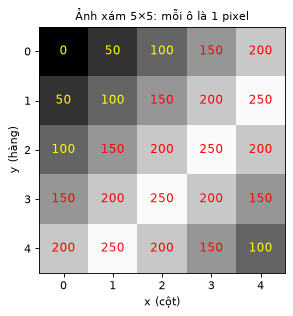

In [2]:
# Một ảnh xám 5x5 tự tạo bằng NumPy
tiny = np.array([[  0,  50, 100, 150, 200],
                 [ 50, 100, 150, 200, 250],
                 [100, 150, 200, 250, 200],
                 [150, 200, 250, 200, 150],
                 [200, 250, 200, 150, 100]], dtype=np.uint8)

print('Ma trận ảnh:\n', tiny)
print('shape =', tiny.shape, '| dtype =', tiny.dtype, '| số pixel =', tiny.size)
print('Pixel tại hàng y=0, cột x=4 :', tiny[0, 4])

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(tiny, cmap='gray', vmin=0, vmax=255)
for y in range(5):
    for x in range(5):
        ax.text(x, y, tiny[y, x], ha='center', va='center',
                color='red' if tiny[y, x] > 127 else 'yellow', fontsize=11)
ax.set_xlabel('x (cột)'); ax.set_ylabel('y (hàng)')
ax.set_title('Ảnh xám 5×5: mỗi ô là 1 pixel')
plt.show()

### 1.3. Ảnh màu: thứ tự kênh **BGR** (không phải RGB!)

Vì lý do lịch sử, OpenCV lưu ảnh màu theo thứ tự **B – G – R**. Matplotlib, PIL, hầu hết thư viện khác dùng **R – G – B**. Nếu đưa thẳng ảnh OpenCV vào `plt.imshow` → màu bị sai (đỏ ↔ xanh dương).

C:\Users\Dell\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Dell\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


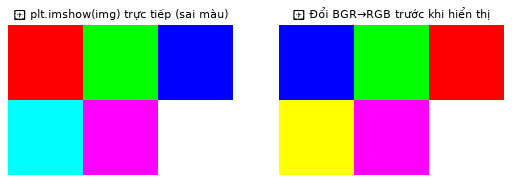

Pixel [0,0] (B,G,R) = [255   0   0]


In [3]:
color = np.zeros((2, 3, 3), np.uint8)   # ảnh 2 hàng x 3 cột x 3 kênh
color[0, 0] = (255, 0, 0)     # B=255 -> XANH DƯƠNG
color[0, 1] = (0, 255, 0)     # G=255 -> XANH LÁ
color[0, 2] = (0, 0, 255)     # R=255 -> ĐỎ
color[1, 0] = (0, 255, 255)   # G+R   -> VÀNG
color[1, 1] = (255, 0, 255)   # B+R   -> TÍM HỒNG (magenta)
color[1, 2] = (255, 255, 255) # cả 3  -> TRẮNG

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].imshow(color)                                  # SAI: coi BGR là RGB
axes[0].set_title('❌ plt.imshow(img) trực tiếp (sai màu)')
axes[1].imshow(cv2.cvtColor(color, cv2.COLOR_BGR2RGB)) # ĐÚNG
axes[1].set_title('✅ Đổi BGR→RGB trước khi hiển thị')
for a in axes: a.axis('off')
plt.show()
print('Pixel [0,0] (B,G,R) =', color[0, 0])

🔍 **Nhận xét:** Pixel `(255, 0, 0)` trong OpenCV là **xanh dương**, nhưng Matplotlib hiểu là **đỏ**. Hàm `show()` ở mục 0 đã tự xử lý việc này. Cách khác: `img[:, :, ::-1]` (đảo thứ tự kênh bằng NumPy).

---
## 2. Đọc – hiển thị – lưu ảnh

### 2.1. `cv2.imread(path, flags)`

| Flag | Kết quả |
|---|---|
| `cv2.IMREAD_COLOR` (mặc định, =1) | ảnh màu BGR 3 kênh (bỏ alpha) |
| `cv2.IMREAD_GRAYSCALE` (=0) | ảnh xám 1 kênh |
| `cv2.IMREAD_UNCHANGED` (=-1) | giữ nguyên (kể cả kênh alpha, ảnh 16-bit) |
| `cv2.IMREAD_REDUCED_COLOR_2/4/8` | đọc và thu nhỏ 2/4/8 lần (nhanh với ảnh lớn) |

> ⚠️ **Quan trọng:** Nếu đường dẫn sai, `imread` **không báo lỗi** mà trả về `None`. Luôn kiểm tra `img is None`!

img   : type=ndarray, shape=(480, 512, 3), dtype=uint8, min=0, max=252, mean=80.9
gray  : type=ndarray, shape=(480, 512), dtype=uint8, min=0, max=238, mean=88.7
small : type=ndarray, shape=(240, 256, 3), dtype=uint8, min=0, max=249, mean=80.9


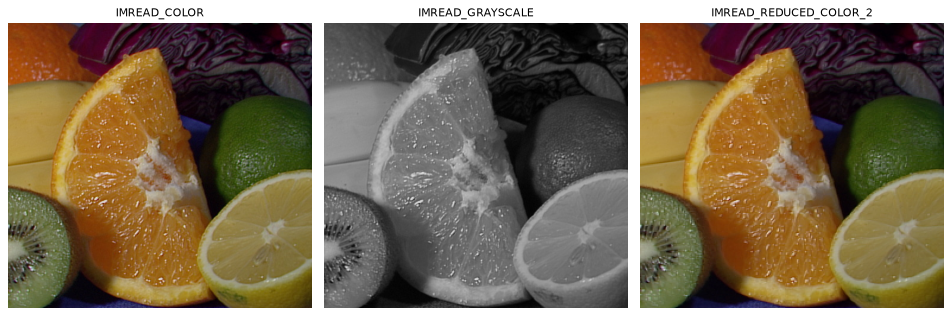

Đọc file không tồn tại -> None
=> Luôn kiểm tra: if img is None: raise FileNotFoundError(...)


In [4]:
path = str(IMG_DIR / 'fruits.jpg')

img   = cv2.imread(path)                              # màu (BGR)
gray  = cv2.imread(path, cv2.IMREAD_GRAYSCALE)        # xám
small = cv2.imread(path, cv2.IMREAD_REDUCED_COLOR_2)  # thu nhỏ 1/2

for name, im in [('img', img), ('gray', gray), ('small', small)]:
    print(f'{name:6s}: type={type(im).__name__}, shape={im.shape}, dtype={im.dtype}, '
          f'min={im.min()}, max={im.max()}, mean={im.mean():.1f}')

show([img, gray, small], ['IMREAD_COLOR', 'IMREAD_GRAYSCALE', 'IMREAD_REDUCED_COLOR_2'])

bad = cv2.imread('khong_ton_tai.jpg')
print('Đọc file không tồn tại ->', bad)   # None, không có exception!
if bad is None:
    print('=> Luôn kiểm tra: if img is None: raise FileNotFoundError(...)')

### 2.2. Lưu ảnh: `cv2.imwrite(path, img, params)`

Định dạng được quyết định bởi **đuôi file**. Một số tham số:

- JPEG: `[cv2.IMWRITE_JPEG_QUALITY, 0..100]` (mặc định 95) — nén **mất dữ liệu** (lossy).
- PNG: `[cv2.IMWRITE_PNG_COMPRESSION, 0..9]` — nén **không mất dữ liệu** (lossless), số càng lớn file càng nhỏ nhưng ghi chậm hơn.

Để đo chất lượng ảnh sau nén, ta dùng **PSNR** (Peak Signal-to-Noise Ratio):

$$\text{PSNR} = 10\log_{10}\frac{255^2}{\text{MSE}}, \qquad \text{MSE}=\frac{1}{N}\sum (I-K)^2$$

PSNR càng cao càng giống ảnh gốc (> 40 dB: gần như không phân biệt; < 30 dB: thấy rõ suy giảm; ảnh giống hệt → ∞).

Định dạng    | Dung lượng | PSNR
JPEG q=95    |     89.1 KB | 39.07 dB
JPEG q=50    |     23.8 KB | 32.25 dB
JPEG q=10    |      8.5 KB | 27.26 dB
PNG          |    397.9 KB | 361.20 dB


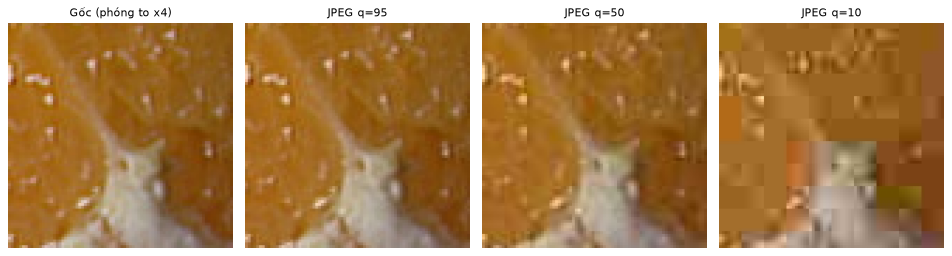

In [5]:
results, crops = [], []
y0, x0, s = 150, 200, 80                       # vùng cắt để phóng to quan sát
for q in [95, 50, 10]:
    p = OUT_DIR / f'fruits_q{q}.jpg'
    cv2.imwrite(str(p), img, [cv2.IMWRITE_JPEG_QUALITY, q])
    rec = cv2.imread(str(p))
    results.append((f'JPEG q={q}', p.stat().st_size / 1024, cv2.PSNR(img, rec)))
    crops.append(rec[y0:y0+s, x0:x0+s])

p = OUT_DIR / 'fruits.png'
cv2.imwrite(str(p), img, [cv2.IMWRITE_PNG_COMPRESSION, 9])
rec = cv2.imread(str(p))
results.append(('PNG', p.stat().st_size / 1024, cv2.PSNR(img, rec)))

print(f'{"Định dạng":12s} | {"Dung lượng":>10s} | PSNR')
for name, kb, psnr in results:
    print(f'{name:12s} | {kb:8.1f} KB | {psnr:.2f} dB')

zoom = lambda im: cv2.resize(im, None, fx=4, fy=4, interpolation=cv2.INTER_NEAREST)
show([zoom(img[y0:y0+s, x0:x0+s])] + [zoom(c) for c in crops],
     ['Gốc (phóng to x4)', 'JPEG q=95', 'JPEG q=50', 'JPEG q=10'], cols=4, size=3)

🔍 **Nhận xét:**
- PNG cho PSNR = ∞ (OpenCV trả về một số rất lớn, ví dụ 361 dB) vì **giống hệt** ảnh gốc, nhưng file lớn.
- JPEG chất lượng 10 rất nhỏ nhưng xuất hiện **khối vuông 8×8** và viền nhòe (*blocking artifacts*).
- ➜ Lưu **kết quả trung gian / mask / ảnh nhị phân** nên dùng **PNG**; ảnh chụp để chia sẻ dùng JPEG 85–95.

### 2.3. Hiển thị bằng cửa sổ OpenCV (dùng trong file `.py`, không chạy trong notebook)

```python
img = cv2.imread('anh.jpg')
cv2.imshow('Cua so anh', img)   # tên cửa sổ không nên có dấu
key = cv2.waitKey(0)            # chờ nhấn phím (0 = chờ mãi); trả về mã phím
if key == ord('s'):
    cv2.imwrite('da_luu.png', img)
cv2.destroyAllWindows()         # đóng tất cả cửa sổ
```

### 2.4. ⚠️ Đường dẫn có tiếng Việt (Unicode) trên Windows

`cv2.imread('D:/Ảnh/mèo.jpg')` thường trả về `None` trên Windows vì OpenCV không đọc được đường dẫn Unicode. Giải pháp: đọc byte bằng NumPy rồi giải mã bằng `cv2.imdecode`.

In [6]:
def imread_unicode(path, flags=cv2.IMREAD_COLOR):
    """Đọc ảnh từ đường dẫn có ký tự Unicode (tiếng Việt)."""
    data = np.fromfile(str(path), dtype=np.uint8)
    return cv2.imdecode(data, flags)


def imwrite_unicode(path, img, params=None):
    """Ghi ảnh ra đường dẫn Unicode."""
    ok, buf = cv2.imencode(Path(path).suffix, img, params or [])
    if ok:
        buf.tofile(str(path))
    return ok


vn_path = OUT_DIR / 'ảnh_trái_cây.png'
print('imwrite_unicode :', imwrite_unicode(vn_path, img))
print('cv2.imread      :', None if cv2.imread(str(vn_path)) is None else 'đọc được')
print('imread_unicode  :', imread_unicode(vn_path).shape)

# imencode cũng rất hữu ích để gửi ảnh qua mạng / lưu vào database dưới dạng bytes
ok, buf = cv2.imencode('.jpg', img, [cv2.IMWRITE_JPEG_QUALITY, 80])
print('Ảnh mã hóa JPEG trong bộ nhớ:', buf.shape, 'bytes')

imwrite_unicode : True
cv2.imread      : đọc được
imread_unicode  : (480, 512, 3)
Ảnh mã hóa JPEG trong bộ nhớ: (40677,) bytes


---
## 3. Truy cập pixel, ROI, tách/gộp kênh

### 3.1. Đọc & ghi pixel

Kích thước: rộng=512, cao=480, số kênh=3
Pixel (x=50, y=100) -> B=61, G=107, R=125
Chỉ kênh đỏ  img[y, x, 2] = 125


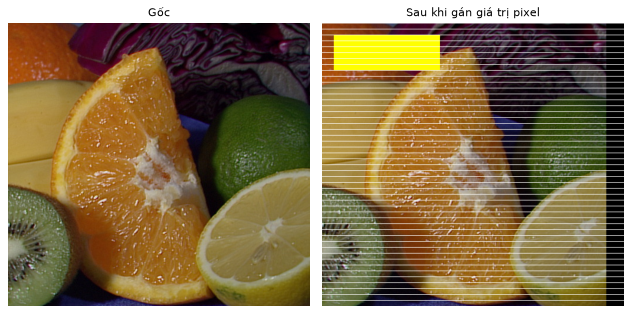

In [7]:
img = load_sample('fruits.jpg')
h, w, c = img.shape
print(f'Kích thước: rộng={w}, cao={h}, số kênh={c}')

y, x = 100, 50
b, g, r = img[y, x]                       # đọc 1 pixel -> 3 giá trị B, G, R
print(f'Pixel (x={x}, y={y}) -> B={b}, G={g}, R={r}')
print('Chỉ kênh đỏ  img[y, x, 2] =', img[y, x, 2])

canvas = img.copy()                        # luôn copy nếu không muốn sửa ảnh gốc
canvas[y, x] = (0, 0, 255)                 # ghi 1 pixel (rất nhỏ, khó thấy)
canvas[20:80, 20:200] = (0, 255, 255)      # ghi cả 1 vùng: tô vàng
canvas[:, -30:] = 0                        # 30 cột cuối -> đen
canvas[::10, :] = (255, 255, 255)          # cứ 10 hàng kẻ 1 đường trắng
show([img, canvas], ['Gốc', 'Sau khi gán giá trị pixel'])

### 3.2. ROI (Region of Interest) — vùng quan tâm

ROI = **cắt một vùng chữ nhật** bằng slicing NumPy: `roi = img[y1:y2, x1:x2]`.

> ⚠️ **View vs Copy:** slicing NumPy trả về một **view** (cùng chia sẻ bộ nhớ). Sửa `roi` ⇒ **ảnh gốc cũng bị sửa**! Dùng `.copy()` nếu muốn bản độc lập.

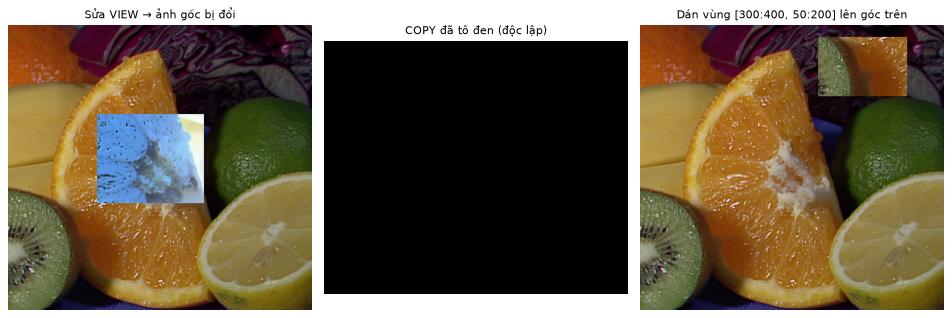

np.shares_memory(work, roi_view) = True
np.shares_memory(work, roi_copy) = False


In [8]:
work = img.copy()
roi_view = work[150:300, 150:330]       # VIEW
roi_copy = work[150:300, 150:330].copy()  # COPY

roi_view[:] = 255 - roi_view             # đảo màu trên view -> ảnh 'work' bị đổi theo!
roi_copy[:] = 0                          # sửa copy -> 'work' không đổi

# Sao chép (dán) một vùng sang chỗ khác: hai vùng phải cùng kích thước
patch = img[300:400, 50:200]
work2 = img.copy()
work2[20:120, 300:450] = patch

show([work, roi_copy, work2],
     ['Sửa VIEW → ảnh gốc bị đổi', 'COPY đã tô đen (độc lập)', 'Dán vùng [300:400, 50:200] lên góc trên'])
print('np.shares_memory(work, roi_view) =', np.shares_memory(work, roi_view))
print('np.shares_memory(work, roi_copy) =', np.shares_memory(work, roi_copy))

### 3.3. Tách và gộp kênh màu — `cv2.split` / `cv2.merge`

Mỗi kênh là một ảnh xám: pixel **sáng** trong kênh R nghĩa là vùng đó **có nhiều màu đỏ**.

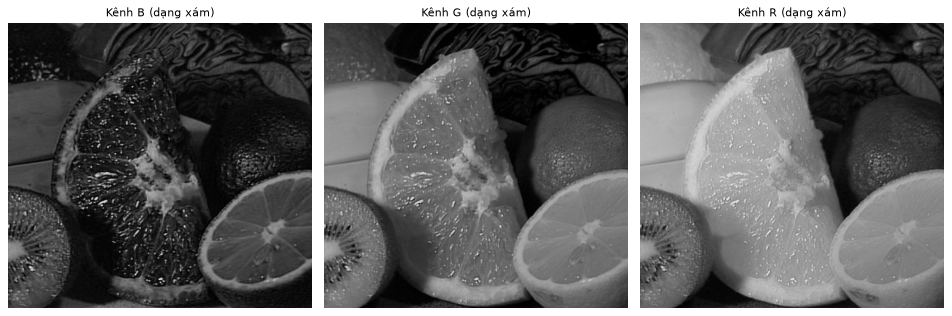

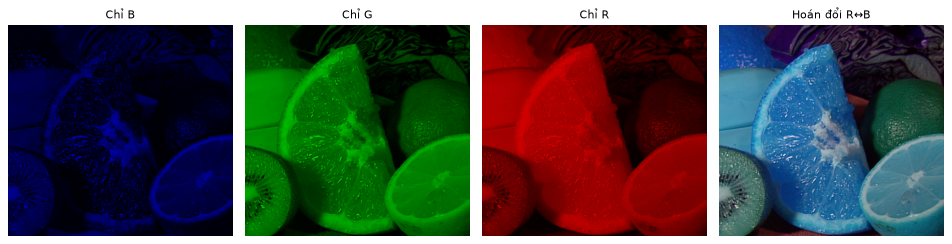

In [9]:
b, g, r = cv2.split(img)                 # tương đương: b = img[:, :, 0], ...
zeros = np.zeros_like(b)

only_b = cv2.merge([b, zeros, zeros])    # chỉ giữ kênh B
only_g = cv2.merge([zeros, g, zeros])
only_r = cv2.merge([zeros, zeros, r])
swap   = cv2.merge([r, g, b])            # hoán đổi R <-> B

show([b, g, r], ['Kênh B (dạng xám)', 'Kênh G (dạng xám)', 'Kênh R (dạng xám)'])
show([only_b, only_g, only_r, swap], ['Chỉ B', 'Chỉ G', 'Chỉ R', 'Hoán đổi R↔B'], cols=4, size=3)

🔍 **Nhận xét:** Quả chuối / cam (vàng – cam) sáng trong cả kênh **R** và **G** nhưng tối trong kênh **B** (vì vàng = đỏ + lục). `cv2.split` tốn chi phí sao chép; nếu chỉ cần 1 kênh, dùng indexing `img[:, :, 2]` sẽ nhanh hơn.

### 3.4. Thống kê ảnh

In [10]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
mean, std = cv2.meanStdDev(img)
print('Trung bình mỗi kênh (B,G,R):', mean.ravel().round(1))
print('Độ lệch chuẩn (B,G,R)      :', std.ravel().round(1))

min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(gray)   # chỉ cho ảnh 1 kênh
print(f'Pixel tối nhất = {min_val} tại (x,y)={min_loc}; sáng nhất = {max_val} tại {max_loc}')
print('Số pixel sáng hơn 200:', cv2.countNonZero((gray > 200).astype(np.uint8)))

Trung bình mỗi kênh (B,G,R): [ 46.2  85.6 110.8]
Độ lệch chuẩn (B,G,R)      : [34.1 47.5 55.4]
Pixel tối nhất = 0.0 tại (x,y)=(228, 1); sáng nhất = 238.0 tại (146, 296)
Số pixel sáng hơn 200: 400


### 3.5. ⚡ Đừng dùng vòng lặp `for` trên từng pixel!

Python rất chậm khi lặp từng pixel. Hãy dùng **phép toán vector hóa của NumPy** hoặc **hàm OpenCV** (viết bằng C++ và tối ưu SIMD).

In [11]:
small = cv2.resize(img, (200, 200))

t = time.perf_counter()
out_loop = np.empty_like(small)
for yy in range(small.shape[0]):
    for xx in range(small.shape[1]):
        out_loop[yy, xx] = 255 - small[yy, xx]
t_loop = time.perf_counter() - t

t = time.perf_counter(); out_np = 255 - small;            t_np = time.perf_counter() - t
t = time.perf_counter(); out_cv = cv2.bitwise_not(small); t_cv = time.perf_counter() - t

print(f'Vòng lặp Python : {t_loop*1000:8.2f} ms')
print(f'NumPy vector    : {t_np*1000:8.3f} ms  (nhanh hơn ~{t_loop/t_np:,.0f} lần)')
print(f'OpenCV          : {t_cv*1000:8.3f} ms')
print('Ba kết quả giống nhau:', np.array_equal(out_loop, out_np) and np.array_equal(out_np, out_cv))

Vòng lặp Python :    39.67 ms
NumPy vector    :    0.082 ms  (nhanh hơn ~484 lần)
OpenCV          :    0.068 ms
Ba kết quả giống nhau: True


### 3.6. Thêm viền ảnh — `cv2.copyMakeBorder`

Rất quan trọng vì các bộ lọc (mục 11) cần biết "bên ngoài ảnh" có giá trị gì. Các kiểu viền:

| Kiểu | Minh họa (dãy `abcdefgh`) |
|---|---|
| `BORDER_CONSTANT` | `iiiiii|abcdefgh|iiiiii` (giá trị cố định) |
| `BORDER_REPLICATE` | `aaaaaa|abcdefgh|hhhhhhh` |
| `BORDER_REFLECT` | `fedcba|abcdefgh|hgfedcb` |
| `BORDER_REFLECT_101` (mặc định của bộ lọc) | `gfedcb|abcdefgh|gfedcba` |
| `BORDER_WRAP` | `cdefgh|abcdefgh|abcdefg` |

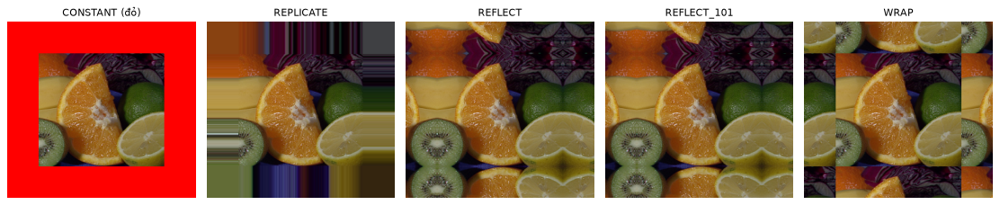

In [12]:
src = cv2.resize(img, (200, 180))
p = 50
borders = {
    'CONSTANT (đỏ)': cv2.copyMakeBorder(src, p, p, p, p, cv2.BORDER_CONSTANT, value=(0, 0, 255)),
    'REPLICATE':     cv2.copyMakeBorder(src, p, p, p, p, cv2.BORDER_REPLICATE),
    'REFLECT':       cv2.copyMakeBorder(src, p, p, p, p, cv2.BORDER_REFLECT),
    'REFLECT_101':   cv2.copyMakeBorder(src, p, p, p, p, cv2.BORDER_REFLECT_101),
    'WRAP':          cv2.copyMakeBorder(src, p, p, p, p, cv2.BORDER_WRAP),
}
show(list(borders.values()), list(borders.keys()), cols=5, size=2.8)

✍️ **Bài tập 3:**
1. Cắt ra quả chuối trong ảnh `fruits.jpg` (thử đoán tọa độ, hiển thị để kiểm tra).
2. Tạo ảnh mà nửa trái là ảnh gốc, nửa phải là ảnh âm bản (`255 - img`).

---
## 4. Không gian màu (Color Spaces)

`cv2.cvtColor(img, code)` chuyển đổi giữa hơn 150 không gian màu. Các không gian hay dùng:

| Không gian | Thành phần | Dùng khi |
|---|---|---|
| **BGR** | Blue, Green, Red | mặc định của OpenCV |
| **GRAY** | độ sáng | hầu hết thuật toán (cạnh, ngưỡng, contour…) |
| **HSV** | Hue (sắc độ), Saturation (bão hòa), Value (độ sáng) | **lọc theo màu**, ít nhạy với ánh sáng |
| **LAB** | L (sáng), a (lục↔đỏ), b (lam↔vàng) | so sánh màu theo cảm nhận người, cân bằng sáng |
| **YCrCb** | Y (sáng), Cr, Cb (màu) | nén ảnh, phát hiện da, cân bằng histogram |

### 4.1. Ảnh xám

$$Y = 0.299R + 0.587G + 0.114B$$

Mắt người nhạy với màu lục nhất ⇒ trọng số G lớn nhất. Đây **không phải** trung bình cộng đơn giản.

Sai khác lớn nhất cvtColor vs công thức: 1


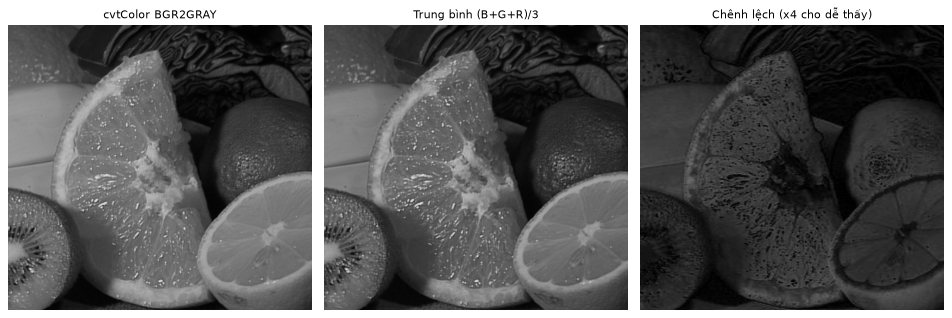

In [13]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

B, G, R = [img[:, :, i].astype(np.float32) for i in range(3)]
gray_manual = np.round(0.299 * R + 0.587 * G + 0.114 * B).astype(np.uint8)
gray_mean = img.mean(axis=2).astype(np.uint8)

print('Sai khác lớn nhất cvtColor vs công thức:', np.abs(gray.astype(int) - gray_manual).max())
show([gray, gray_mean, cv2.absdiff(gray, gray_mean) * 4],
     ['cvtColor BGR2GRAY', 'Trung bình (B+G+R)/3', 'Chênh lệch (x4 cho dễ thấy)'])

### 4.2. HSV — không gian lý tưởng để lọc màu

- **H (Hue)**: "màu gì" — góc trên vòng màu 0°–360°. ⚠️ Trong OpenCV với ảnh `uint8`, **H ∈ [0, 179]** (= độ/2) để vừa 1 byte.
- **S (Saturation)**: độ "tươi/đậm" của màu, 0 = xám, 255 = rất tươi.
- **V (Value)**: độ sáng, 0 = đen.

Vì màu (H) tách riêng khỏi độ sáng (V), nên lọc theo H ổn định hơn nhiều so với lọc trên BGR khi ánh sáng thay đổi.

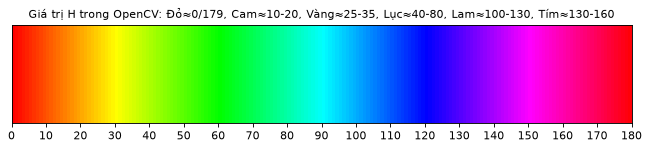

Đỏ    BGR=(0, 0, 255) -> HSV=[  0 255 255]
Lục   BGR=(0, 255, 0) -> HSV=[ 60 255 255]
Lam   BGR=(255, 0, 0) -> HSV=[120 255 255]
Vàng  BGR=(0, 255, 255) -> HSV=[ 30 255 255]


In [14]:
# Thanh màu Hue của OpenCV: H chạy từ 0 -> 179, S = V = 255
hue = np.tile(np.arange(180, dtype=np.uint8), (30, 1))
hsv_bar = cv2.merge([hue, np.full_like(hue, 255), np.full_like(hue, 255)])
bar = cv2.cvtColor(hsv_bar, cv2.COLOR_HSV2BGR)

fig, ax = plt.subplots(figsize=(10, 1.6))
ax.imshow(cv2.cvtColor(bar, cv2.COLOR_BGR2RGB), aspect='auto', extent=[0, 180, 0, 1])
ax.set_yticks([]); ax.set_xticks(range(0, 181, 10))
ax.set_title('Giá trị H trong OpenCV: Đỏ≈0/179, Cam≈10-20, Vàng≈25-35, Lục≈40-80, Lam≈100-130, Tím≈130-160')
plt.show()

# Mẹo: tra giá trị HSV của một màu BGR bất kỳ
for name, bgr in [('Đỏ', (0, 0, 255)), ('Lục', (0, 255, 0)), ('Lam', (255, 0, 0)), ('Vàng', (0, 255, 255))]:
    print(f'{name:5s} BGR={bgr} -> HSV={cv2.cvtColor(np.uint8([[bgr]]), cv2.COLOR_BGR2HSV)[0, 0]}')

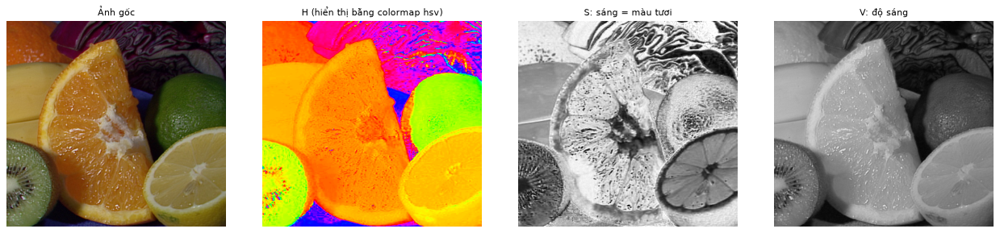

In [15]:
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(hsv)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0].set_title('Ảnh gốc')
axes[1].imshow(H, cmap='hsv', vmin=0, vmax=179);     axes[1].set_title('H (hiển thị bằng colormap hsv)')
axes[2].imshow(S, cmap='gray', vmin=0, vmax=255);    axes[2].set_title('S: sáng = màu tươi')
axes[3].imshow(V, cmap='gray', vmin=0, vmax=255);    axes[3].set_title('V: độ sáng')
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

### 4.3. Tách đối tượng theo màu — `cv2.inRange`

`mask = cv2.inRange(hsv, lower, upper)` → ảnh nhị phân: **255** nếu pixel nằm trong khoảng `[lower, upper]` ở **cả 3 kênh**, ngược lại **0**. Sau đó dùng `cv2.bitwise_and(img, img, mask=mask)` để giữ lại phần có màu đó.

> ⚠️ **Màu đỏ "quấn vòng"**: H của đỏ nằm ở **cả hai đầu** (0–10 và 170–179) ⇒ phải dùng **2 khoảng** rồi OR lại.

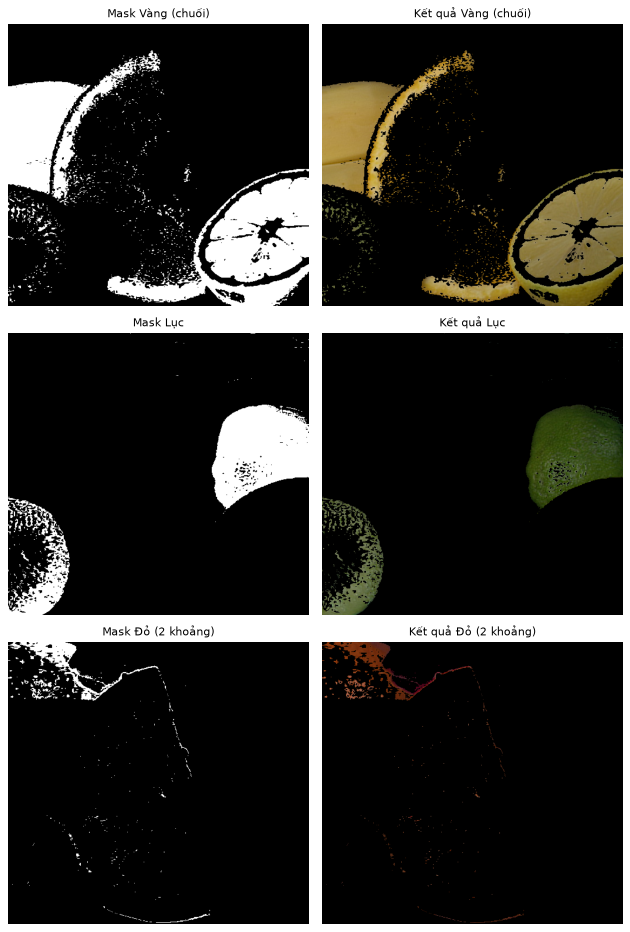

In [16]:
ranges = {
    'Vàng (chuối)':  [((20, 100, 100), (35, 255, 255))],
    'Lục':           [((36, 60, 40),   (85, 255, 255))],
    'Đỏ (2 khoảng)': [((0, 120, 70),   (10, 255, 255)),
                      ((170, 120, 70), (179, 255, 255))],
}
outs, titles = [], []
for name, rr in ranges.items():
    mask = np.zeros(img.shape[:2], np.uint8)
    for lo, hi in rr:
        mask |= cv2.inRange(hsv, np.array(lo), np.array(hi))
    outs += [mask, cv2.bitwise_and(img, img, mask=mask)]
    titles += [f'Mask {name}', f'Kết quả {name}']
show(outs, titles, cols=2, size=4)

🔍 **Nhận xét:** Mask chưa hoàn hảo — có lỗ nhỏ và nhiễu lấm tấm. Ở mục 14 (hình thái học) ta sẽ học cách "làm sạch" mask bằng **opening/closing**.

### 4.4. Ứng dụng: đổi màu đối tượng (dịch Hue)

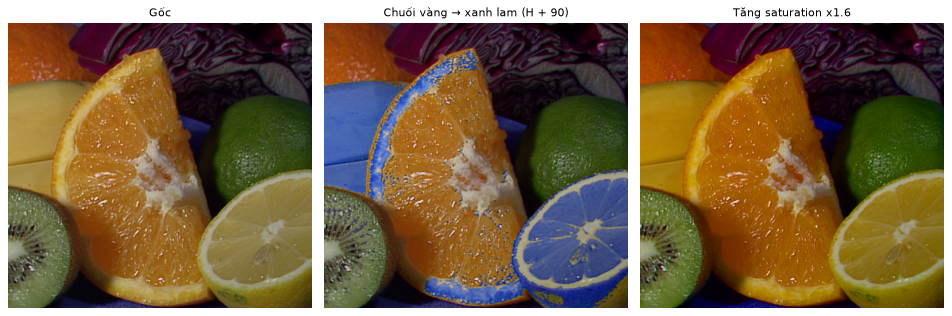

In [17]:
hsv2 = hsv.copy()
mask_y = cv2.inRange(hsv, np.array((20, 100, 100)), np.array((35, 255, 255)))
hsv2[..., 0] = np.where(mask_y > 0, (hsv2[..., 0].astype(int) + 90) % 180, hsv2[..., 0])  # dịch 180°
recolor = cv2.cvtColor(hsv2, cv2.COLOR_HSV2BGR)

hsv3 = hsv.copy()
hsv3[..., 1] = cv2.multiply(hsv3[..., 1], 1.6)          # tăng độ bão hòa 60% (tự cắt ở 255)
vivid = cv2.cvtColor(hsv3, cv2.COLOR_HSV2BGR)
show([img, recolor, vivid], ['Gốc', 'Chuối vàng → xanh lam (H + 90)', 'Tăng saturation x1.6'])

### 4.5. LAB và YCrCb

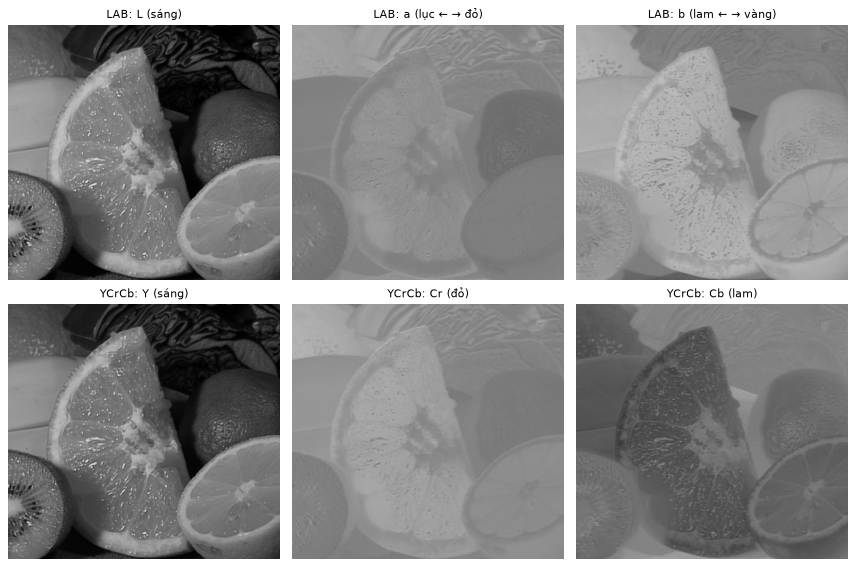

In [18]:
lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
ycc = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
L, A, Bc = cv2.split(lab)
Y, Cr, Cb = cv2.split(ycc)
show([L, A, Bc, Y, Cr, Cb],
     ['LAB: L (sáng)', 'LAB: a (lục ← → đỏ)', 'LAB: b (lam ← → vàng)',
      'YCrCb: Y (sáng)', 'YCrCb: Cr (đỏ)', 'YCrCb: Cb (lam)'], cols=3, size=3.6)

🔍 **Nhận xét:** Kênh **L** và **Y** gần như ảnh xám — chứa *độ sáng*; các kênh còn lại chỉ chứa *thông tin màu*. Đây là lý do khi muốn chỉnh sáng/tương phản ảnh màu (mục 9), ta chỉ xử lý L hoặc Y để **không làm lệch màu**.

✍️ **Bài tập 4:** Dùng `inRange` trong HSV để tách các viên kẹo màu xanh lam trong `smarties.png`.

---
## 5. Vẽ hình và chữ lên ảnh

Các hàm vẽ **sửa trực tiếp** ảnh truyền vào (in-place). Tham số chung:
- `color`: tuple **BGR**, ví dụ `(0, 0, 255)` = đỏ.
- `thickness`: độ dày nét; **`-1` (hoặc `cv2.FILLED`) = tô kín**.
- `lineType`: `cv2.LINE_AA` cho nét mượt (khử răng cưa).
- Tọa độ điểm là **`(x, y)` kiểu `int`**.

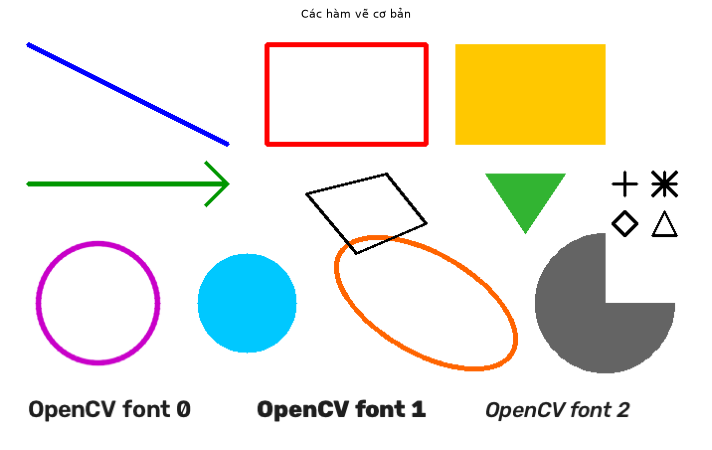

In [19]:
canvas = np.full((420, 700, 3), 255, np.uint8)        # nền trắng

cv2.line(canvas, (20, 20), (220, 120), (255, 0, 0), 3)                     # đường thẳng
cv2.arrowedLine(canvas, (20, 160), (220, 160), (0, 150, 0), 3, tipLength=0.15)
cv2.rectangle(canvas, (260, 20), (420, 120), (0, 0, 255), 3)               # chữ nhật viền
cv2.rectangle(canvas, (450, 20), (600, 120), (0, 200, 255), -1)            # chữ nhật tô kín
cv2.circle(canvas, (90, 280), 60, (200, 0, 200), 4, cv2.LINE_AA)           # đường tròn
cv2.circle(canvas, (240, 280), 50, (255, 200, 0), -1)                      # hình tròn đặc
cv2.ellipse(canvas, (420, 280), (100, 50), 30, 0, 360, (0, 100, 255), 3)   # elip xoay 30°
cv2.ellipse(canvas, (600, 280), (70, 70), 0, 0, 270, (100, 100, 100), -1)  # cung 0..270° (hình Pac-man)

pts = np.array([[300, 170], [380, 150], [420, 200], [350, 230]], np.int32)
cv2.polylines(canvas, [pts], isClosed=True, color=(0, 0, 0), thickness=2)  # đa giác
tri = np.array([[480, 150], [560, 150], [520, 210]], np.int32)
cv2.fillPoly(canvas, [tri], (50, 180, 50))                                  # đa giác tô kín

for i, m in enumerate([cv2.MARKER_CROSS, cv2.MARKER_STAR, cv2.MARKER_DIAMOND, cv2.MARKER_TRIANGLE_UP]):
    cv2.drawMarker(canvas, (620 + (i % 2) * 40, 160 + (i // 2) * 40), (0, 0, 0), m, 25, 2)

fonts = [cv2.FONT_HERSHEY_SIMPLEX, cv2.FONT_HERSHEY_COMPLEX, cv2.FONT_HERSHEY_SCRIPT_SIMPLEX]
for i, f in enumerate(fonts):
    cv2.putText(canvas, f'OpenCV font {i}', (20 + i * 230, 395), f, 0.8, (30, 30, 30), 2, cv2.LINE_AA)
show(canvas, 'Các hàm vẽ cơ bản', size=9)

### 5.1. Vẽ nhãn kiểu "object detection" và chữ tiếng Việt

- `cv2.getTextSize` cho biết kích thước chữ ⇒ vẽ được nền chữ vừa khít.
- ⚠️ `cv2.putText` **không hỗ trợ tiếng Việt có dấu** (chỉ ASCII). Muốn viết tiếng Việt, dùng **Pillow (PIL)** với font TrueType.

C:\Users\Dell\AppData\Local\Temp\ipykernel_13832\1805128670.py:53: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Dell\AppData\Local\Temp\ipykernel_13832\1805128670.py:53: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


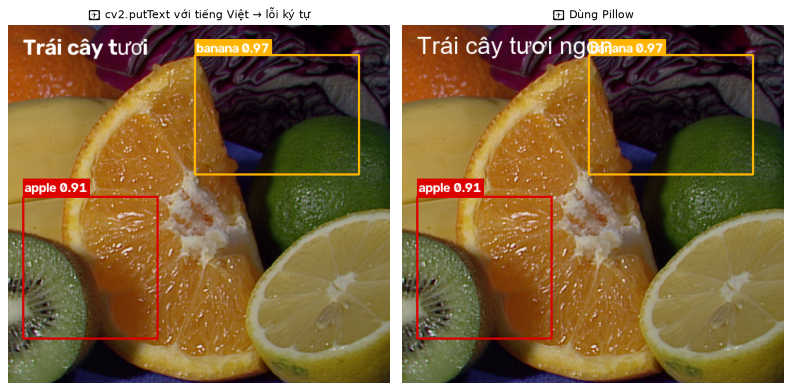

In [20]:
from PIL import Image, ImageDraw, ImageFont


def draw_label(img, text, x1, y1, x2, y2, color=(0, 200, 0)):
    """Vẽ bounding box + nhãn có nền giống kết quả object detection."""
    cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
    (tw, th), baseline = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
    cv2.rectangle(img, (x1, y1 - th - baseline - 4), (x1 + tw + 4, y1), color, -1)
    cv2.putText(img, text, (x1 + 2, y1 - baseline - 2), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)


def put_text_vn(img_bgr, text, org, font_size=28, color=(255, 255, 255)):
    """Viết chữ Unicode (tiếng Việt) bằng Pillow. color theo BGR."""
    pil = Image.fromarray(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    draw = ImageDraw.Draw(pil)
    font = None
    for f in ['C:/Windows/Fonts/arial.ttf', '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',
              '/Library/Fonts/Arial.ttf', '/System/Library/Fonts/Supplemental/Arial.ttf']:
        if os.path.exists(f):
            font = ImageFont.truetype(f, font_size)
            break
    font = font or ImageFont.load_default()
    draw.text(org, text, font=font, fill=tuple(int(c) for c in color[::-1]))
    return cv2.cvtColor(np.array(pil), cv2.COLOR_RGB2BGR)


annot = img.copy()
draw_label(annot, 'banana 0.97', 250, 40, 470, 200, (0, 180, 255))
draw_label(annot, 'apple 0.91', 20, 230, 200, 420, (0, 0, 220))
bad = annot.copy()
cv2.putText(bad, 'Trái cây tươi', (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2)
good = put_text_vn(annot, 'Trái cây tươi ngon', (20, 10), 32, (255, 255, 255))
show([bad, good], ['❌ cv2.putText với tiếng Việt → lỗi ký tự', '✅ Dùng Pillow'], size=5)

---
## 6. Phép toán số học & bitwise

### 6.1. ⚠️ Tràn số: NumPy vs OpenCV

Với `uint8`:
- **NumPy** dùng phép toán **modulo** (quấn vòng): `250 + 10 = 260 % 256 = 4` ⇒ pixel sáng bỗng thành đen!
- **OpenCV** dùng **bão hòa (saturate)**: `250 + 10 = 255`, `10 − 20 = 0`. Đây thường là điều ta muốn.

C:\Users\Dell\AppData\Local\Temp\ipykernel_13832\1805128670.py:53: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Dell\AppData\Local\Temp\ipykernel_13832\1805128670.py:53: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


NumPy  250 + 10 = 4   | OpenCV cv2.add      = 255
NumPy   10 - 250 = 16  | OpenCV cv2.subtract = 0


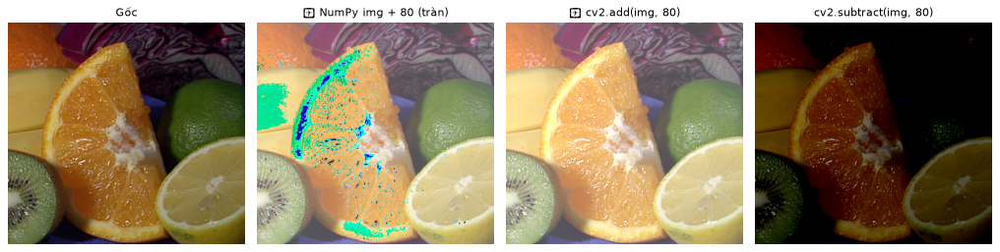

In [21]:
a = np.uint8([[250]]); b = np.uint8([[10]])
print('NumPy  250 + 10 =', (a + b)[0, 0], '  | OpenCV cv2.add      =', cv2.add(a, b)[0, 0])
print('NumPy   10 - 250 =', (b - a)[0, 0], ' | OpenCV cv2.subtract =', cv2.subtract(b, a)[0, 0])

bright_np = img + 80                                    # sai: tràn số
bright_cv = cv2.add(img, np.full_like(img, 80))         # đúng: bão hòa
dark_cv   = cv2.subtract(img, np.full_like(img, 80))
show([img, bright_np, bright_cv, dark_cv],
     ['Gốc', '❌ NumPy img + 80 (tràn)', '✅ cv2.add(img, 80)', 'cv2.subtract(img, 80)'], cols=4, size=3.2)

🔍 **Nhận xét:** Ảnh `img + 80` của NumPy có các mảng màu lạ ở vùng sáng (giá trị > 175 bị "quấn" về gần 0). Nếu muốn dùng NumPy an toàn: chuyển sang kiểu lớn hơn rồi cắt: `np.clip(img.astype(np.int16) + 80, 0, 255).astype(np.uint8)`.

### 6.2. Pha trộn ảnh — `cv2.addWeighted`

$$dst = \alpha \cdot img_1 + \beta \cdot img_2 + \gamma$$

Hai ảnh phải **cùng kích thước và cùng số kênh**.

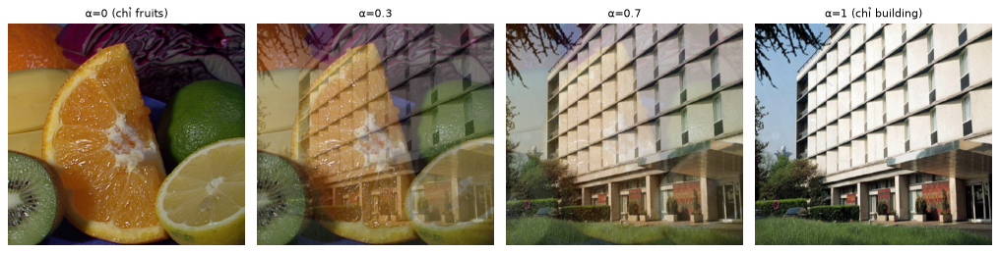

In [22]:
img2 = cv2.resize(load_sample('building.jpg'), (img.shape[1], img.shape[0]))
blends = [cv2.addWeighted(img, 1 - a, img2, a, 0) for a in [0, 0.3, 0.7, 1.0]]
show(blends, ['α=0 (chỉ fruits)', 'α=0.3', 'α=0.7', 'α=1 (chỉ building)'], cols=4, size=3.2)

### 6.3. Hiệu tuyệt đối — `cv2.absdiff` (phát hiện thay đổi)

$|img_1 - img_2|$ — vùng nào giống nhau sẽ đen, vùng khác nhau sẽ sáng. Đây là nền tảng của phát hiện chuyển động và "tìm điểm khác nhau".

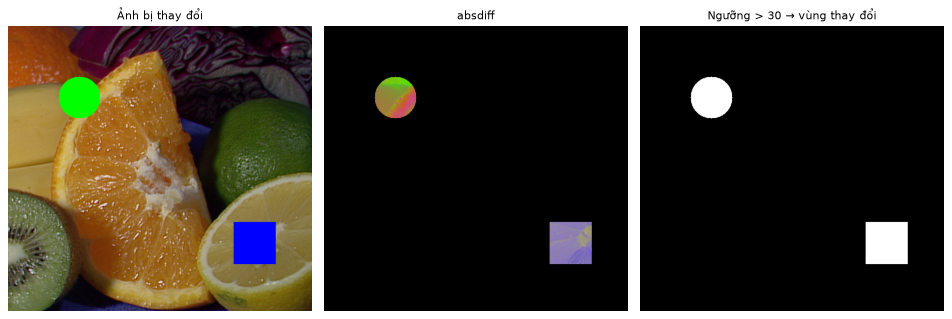

In [23]:
changed = img.copy()
cv2.circle(changed, (120, 120), 35, (0, 255, 0), -1)
cv2.rectangle(changed, (380, 330), (450, 400), (255, 0, 0), -1)
diff = cv2.absdiff(img, changed)
diff_gray = cv2.cvtColor(diff, cv2.COLOR_BGR2GRAY)
_, diff_mask = cv2.threshold(diff_gray, 30, 255, cv2.THRESH_BINARY)
show([changed, diff, diff_mask], ['Ảnh bị thay đổi', 'absdiff', 'Ngưỡng > 30 → vùng thay đổi'])

### 6.4. Phép toán bitwise và mask

| Hàm | Ý nghĩa (với ảnh nhị phân 0/255) |
|---|---|
| `cv2.bitwise_and(a, b)` | giao (trắng khi **cả hai** trắng) |
| `cv2.bitwise_or(a, b)` | hợp (trắng khi **một trong hai** trắng) |
| `cv2.bitwise_xor(a, b)` | trắng khi **chỉ một** trắng |
| `cv2.bitwise_not(a)` | đảo |

Tham số `mask=`: phép toán chỉ thực hiện ở nơi mask ≠ 0, nơi khác = 0.

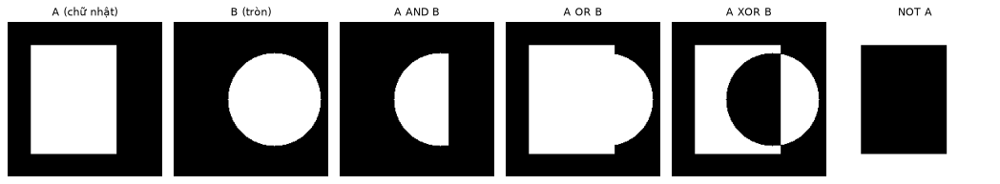

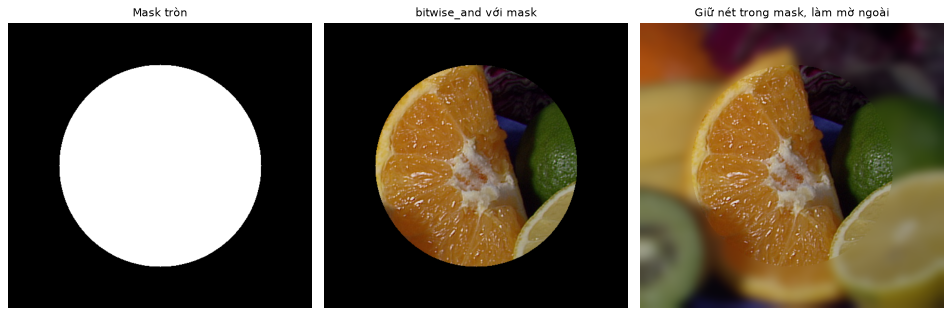

In [24]:
r1 = np.zeros((200, 200), np.uint8); cv2.rectangle(r1, (30, 30), (140, 170), 255, -1)
c1 = np.zeros((200, 200), np.uint8); cv2.circle(c1, (130, 100), 60, 255, -1)
show([r1, c1, cv2.bitwise_and(r1, c1), cv2.bitwise_or(r1, c1), cv2.bitwise_xor(r1, c1), cv2.bitwise_not(r1)],
     ['A (chữ nhật)', 'B (tròn)', 'A AND B', 'A OR B', 'A XOR B', 'NOT A'], cols=6, size=2.2)

# Dùng mask để giữ lại vùng tròn của ảnh
mask = np.zeros(img.shape[:2], np.uint8)
cv2.circle(mask, (img.shape[1] // 2, img.shape[0] // 2), 170, 255, -1)
keep = cv2.bitwise_and(img, img, mask=mask)
blur_bg = cv2.GaussianBlur(img, (51, 51), 0)
portrait = np.where(mask[..., None] > 0, img, blur_bg)      # hiệu ứng "xóa phông" đơn giản
show([mask, keep, portrait], ['Mask tròn', 'bitwise_and với mask', 'Giữ nét trong mask, làm mờ ngoài'])

### 6.5. Chèn logo / watermark có nền trong suốt (kinh điển)

Ý tưởng: tạo mask từ logo → "khoét lỗ" trên ảnh nền bằng `mask_inv` → lấy phần logo bằng `mask` → cộng hai phần.

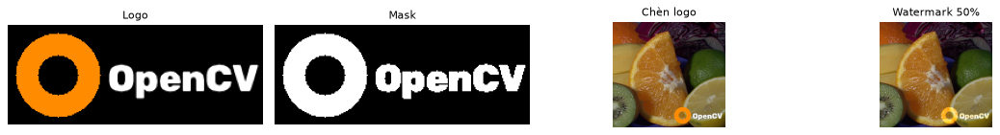

In [25]:
# Tạo logo: chữ trắng + vòng tròn màu trên nền đen
logo = np.zeros((90, 230, 3), np.uint8)
cv2.circle(logo, (45, 45), 38, (0, 140, 255), -1)
cv2.circle(logo, (45, 45), 18, (0, 0, 0), -1)
cv2.putText(logo, 'OpenCV', (90, 60), cv2.FONT_HERSHEY_DUPLEX, 1.2, (255, 255, 255), 2)

logo_gray = cv2.cvtColor(logo, cv2.COLOR_BGR2GRAY)
_, mask = cv2.threshold(logo_gray, 10, 255, cv2.THRESH_BINARY)   # nơi có logo = 255
mask_inv = cv2.bitwise_not(mask)

dst = img.copy()
lh, lw = logo.shape[:2]
y, x = dst.shape[0] - lh - 10, dst.shape[1] - lw - 10           # góc dưới-phải
roi = dst[y:y+lh, x:x+lw]
bg = cv2.bitwise_and(roi, roi, mask=mask_inv)    # nền: khoét chỗ logo
fg = cv2.bitwise_and(logo, logo, mask=mask)      # logo: bỏ nền đen
dst[y:y+lh, x:x+lw] = cv2.add(bg, fg)

# Watermark bán trong suốt
wm = img.copy()
roi2 = wm[y:y+lh, x:x+lw]
blend = cv2.addWeighted(roi2, 1, logo, 0.5, 0)
roi2[mask > 0] = blend[mask > 0]

show([logo, mask, dst, wm], ['Logo', 'Mask', 'Chèn logo', 'Watermark 50%'], cols=4, size=3.5)

---
## 7. Biến đổi hình học (Geometric Transformations)

### 7.1. Thay đổi kích thước — `cv2.resize`

```python
cv2.resize(src, dsize=(W, H))                 # kích thước cụ thể (rộng, cao)
cv2.resize(src, None, fx=0.5, fy=0.5)         # theo tỉ lệ
```

**Phương pháp nội suy** (interpolation) — cách tính giá trị pixel mới:

| Phương pháp | Đặc điểm | Nên dùng |
|---|---|---|
| `INTER_NEAREST` | lấy pixel gần nhất, nhanh nhất, bị răng cưa | mask, ảnh nhãn (không được tạo giá trị mới) |
| `INTER_LINEAR` (mặc định) | song tuyến tính 2×2 | phóng to, đa dụng |
| `INTER_CUBIC` | bicubic 4×4, mịn hơn, chậm hơn | phóng to chất lượng cao |
| `INTER_LANCZOS4` | 8×8, sắc nét nhất | phóng to chất lượng rất cao |
| `INTER_AREA` | lấy trung bình vùng | **thu nhỏ** (tránh nhiễu moiré) |

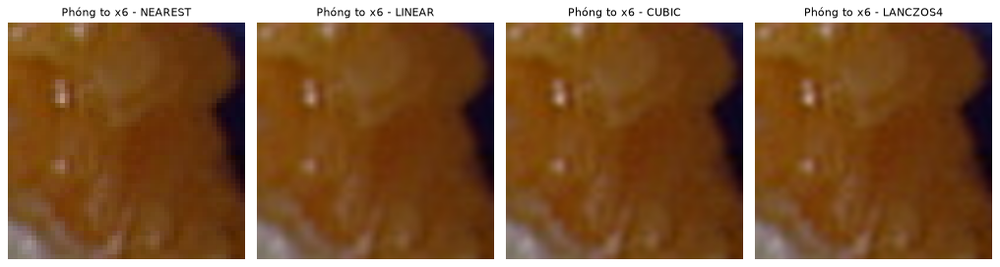

Gốc: (480, 512, 3) -> resize_keep_ratio(width=200): (187, 200, 3)


In [26]:
crop = img[180:230, 260:310]                 # vùng 50x50
methods = {'NEAREST': cv2.INTER_NEAREST, 'LINEAR': cv2.INTER_LINEAR,
           'CUBIC': cv2.INTER_CUBIC, 'LANCZOS4': cv2.INTER_LANCZOS4}
ups = [cv2.resize(crop, None, fx=6, fy=6, interpolation=m) for m in methods.values()]
show(ups, [f'Phóng to x6 - {k}' for k in methods], cols=4, size=3.2)


def resize_keep_ratio(image, width=None, height=None, inter=cv2.INTER_AREA):
    """Resize giữ nguyên tỉ lệ khung hình: chỉ cần cho width HOẶC height."""
    h, w = image.shape[:2]
    if width is None and height is None:
        return image
    if width is not None:
        r = width / w; dim = (width, int(h * r))
    else:
        r = height / h; dim = (int(w * r), height)
    return cv2.resize(image, dim, interpolation=inter)


print('Gốc:', img.shape, '-> resize_keep_ratio(width=200):', resize_keep_ratio(img, width=200).shape)

🔍 **Nhận xét:** `NEAREST` cho các ô vuông rõ rệt; `LINEAR` mịn nhưng hơi mờ; `CUBIC`/`LANCZOS4` sắc nét hơn. **Không phương pháp nào tạo ra chi tiết thật** — muốn vậy cần siêu phân giải (super-resolution) bằng deep learning.

### 7.2. Lật và xoay 90°

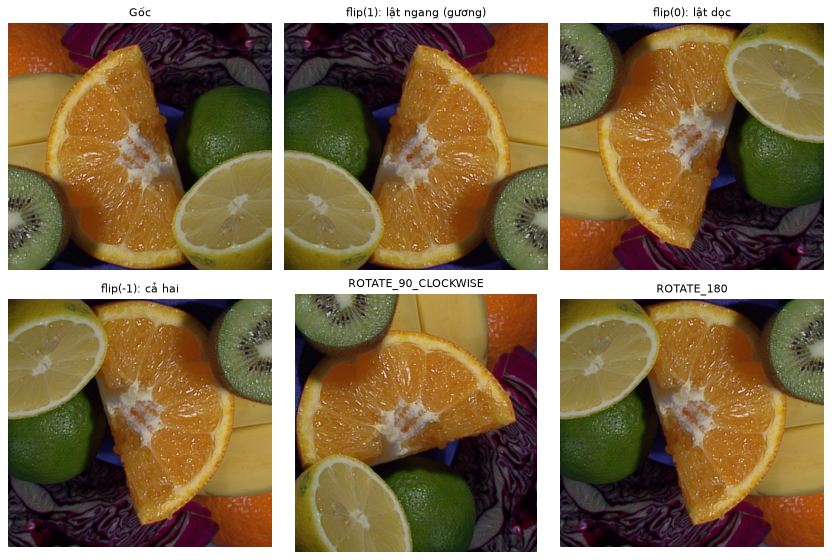

In [27]:
show([img, cv2.flip(img, 1), cv2.flip(img, 0), cv2.flip(img, -1),
      cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE), cv2.rotate(img, cv2.ROTATE_180)],
     ['Gốc', 'flip(1): lật ngang (gương)', 'flip(0): lật dọc', 'flip(-1): cả hai',
      'ROTATE_90_CLOCKWISE', 'ROTATE_180'], cols=3, size=3.5)

### 7.3. Biến đổi Affine — `cv2.warpAffine(src, M, (W, H))`

Biến đổi affine dùng **ma trận 2×3** $M$, ánh xạ điểm $(x, y)$ thành:

$$\begin{bmatrix} x' \\ y' \end{bmatrix} = \begin{bmatrix} a_{11} & a_{12} & t_x \\ a_{21} & a_{22} & t_y \end{bmatrix} \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}$$

Affine **giữ nguyên tính song song** của các đường thẳng. Bao gồm: tịnh tiến, xoay, co giãn, trượt (shear).

- **Tịnh tiến**: $M = \begin{bmatrix} 1 & 0 & t_x \\ 0 & 1 & t_y \end{bmatrix}$
- **Xoay** quanh tâm $(c_x, c_y)$ một góc θ (độ, **dương = ngược chiều kim đồng hồ**), tỉ lệ s: `cv2.getRotationMatrix2D(center, angle, scale)`
- **Từ 3 cặp điểm**: `cv2.getAffineTransform(src_pts, dst_pts)`

Ma trận xoay 30°:
 [[  0.866   0.5   -85.703]
 [ -0.5     0.866 160.154]]


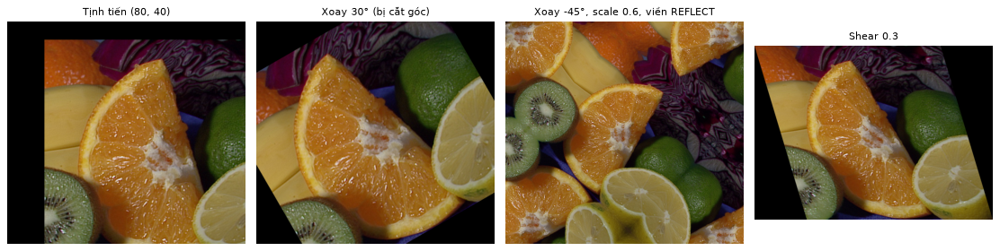

In [28]:
h, w = img.shape[:2]

M_t = np.float32([[1, 0, 80], [0, 1, 40]])                  # dịch phải 80, xuống 40
shifted = cv2.warpAffine(img, M_t, (w, h))

M_r = cv2.getRotationMatrix2D((w / 2, h / 2), 30, 1.0)      # xoay 30° quanh tâm
rotated = cv2.warpAffine(img, M_r, (w, h))
print('Ma trận xoay 30°:\n', M_r.round(3))

M_rs = cv2.getRotationMatrix2D((w / 2, h / 2), -45, 0.6)    # xoay -45° (cùng chiều kim đồng hồ) và thu nhỏ
rot_scaled = cv2.warpAffine(img, M_rs, (w, h), borderMode=cv2.BORDER_REFLECT)

M_sh = np.float32([[1, 0.3, 0], [0, 1, 0]])                 # trượt ngang (shear)
sheared = cv2.warpAffine(img, M_sh, (int(w + 0.3 * h), h))

show([shifted, rotated, rot_scaled, sheared],
     ['Tịnh tiến (80, 40)', 'Xoay 30° (bị cắt góc)', 'Xoay -45°, scale 0.6, viền REFLECT', 'Shear 0.3'],
     cols=4, size=3.5)

Khi xoay, các góc ảnh bị **cắt mất**. Hàm dưới tính lại kích thước khung để chứa trọn ảnh sau xoay:

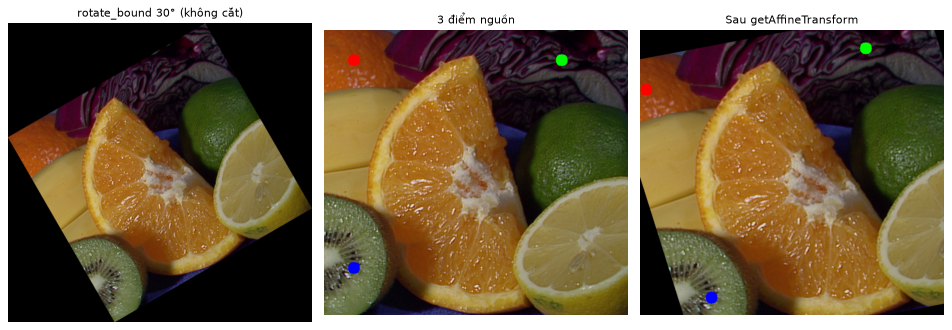

In [29]:
def rotate_bound(image, angle):
    """Xoay ảnh mà không bị cắt góc (khung tự mở rộng)."""
    h, w = image.shape[:2]
    cx, cy = w / 2, h / 2
    M = cv2.getRotationMatrix2D((cx, cy), angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    new_w = int(h * sin + w * cos)
    new_h = int(h * cos + w * sin)
    M[0, 2] += new_w / 2 - cx          # dời tâm sang tâm khung mới
    M[1, 2] += new_h / 2 - cy
    return cv2.warpAffine(image, M, (new_w, new_h))


# Affine từ 3 cặp điểm
src_pts = np.float32([[50, 50], [400, 50], [50, 400]])
dst_pts = np.float32([[10, 100], [380, 30], [120, 450]])
M_aff = cv2.getAffineTransform(src_pts, dst_pts)
aff = cv2.warpAffine(img, M_aff, (w, h))
vis = img.copy()
for (px, py), col in zip(src_pts.astype(int), [(0, 0, 255), (0, 255, 0), (255, 0, 0)]):
    cv2.circle(vis, (px, py), 10, col, -1)
for (px, py), col in zip(dst_pts.astype(int), [(0, 0, 255), (0, 255, 0), (255, 0, 0)]):
    cv2.circle(aff, (px, py), 10, col, -1)
show([rotate_bound(img, 30), vis, aff], ['rotate_bound 30° (không cắt)', '3 điểm nguồn', 'Sau getAffineTransform'])

### 7.4. Biến đổi phối cảnh (Perspective) — `cv2.warpPerspective`

Dùng **ma trận 3×3** (homography), cần **4 cặp điểm**. Không giữ tính song song ⇒ dùng để "nhìn thẳng" một mặt phẳng bị chụp nghiêng: tài liệu, bảng số xe, bàn cờ, sudoku…

$$\begin{bmatrix} x' w \\ y' w \\ w \end{bmatrix} = H \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}$$

Ma trận homography 3x3:
 [[ 1.179800e+00  1.043000e-01 -9.499060e+01]
 [ 4.570000e-02  1.269700e+00 -1.112599e+02]
 [ 1.000000e-04  4.000000e-04  1.000000e+00]]


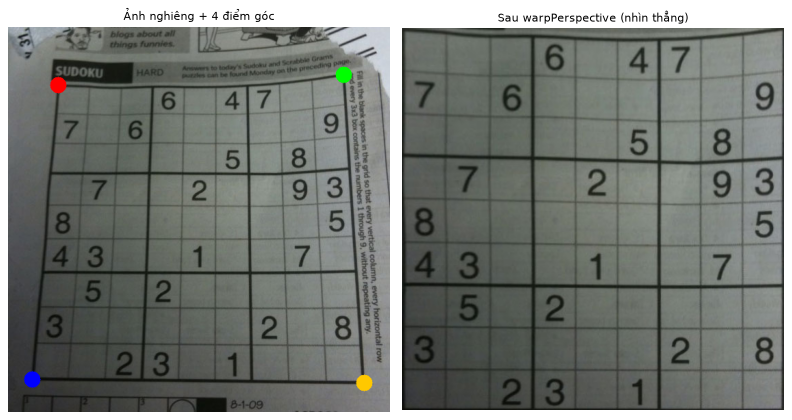

In [30]:
sudoku = load_sample('sudoku.png')
# 4 góc của khung sudoku (trên-trái, trên-phải, dưới-trái, dưới-phải) - xác định thủ công.
# Ở mục 24 ta sẽ tìm 4 góc này TỰ ĐỘNG bằng contour.
pts1 = np.float32([[73, 85], [490, 70], [35, 515], [520, 520]])
pts2 = np.float32([[0, 0], [450, 0], [0, 450], [450, 450]])
H_mat = cv2.getPerspectiveTransform(pts1, pts2)
warped = cv2.warpPerspective(sudoku, H_mat, (450, 450))
print('Ma trận homography 3x3:\n', H_mat.round(4))

vis = sudoku.copy()
for p, col in zip(pts1.astype(int), [(0, 0, 255), (0, 255, 0), (255, 0, 0), (0, 200, 255)]):
    cv2.circle(vis, tuple(int(v) for v in p), 12, col, -1)
show([vis, warped], ['Ảnh nghiêng + 4 điểm góc', 'Sau warpPerspective (nhìn thẳng)'], size=5)

### 7.5. Biến dạng tự do — `cv2.remap`

`remap` cho phép **mỗi pixel đích lấy giá trị từ vị trí bất kỳ** của ảnh nguồn: `dst(y, x) = src(map_y(y,x), map_x(y,x))`. Dùng để sửa méo ống kính, hiệu ứng sóng nước, phóng to "mắt cá"…

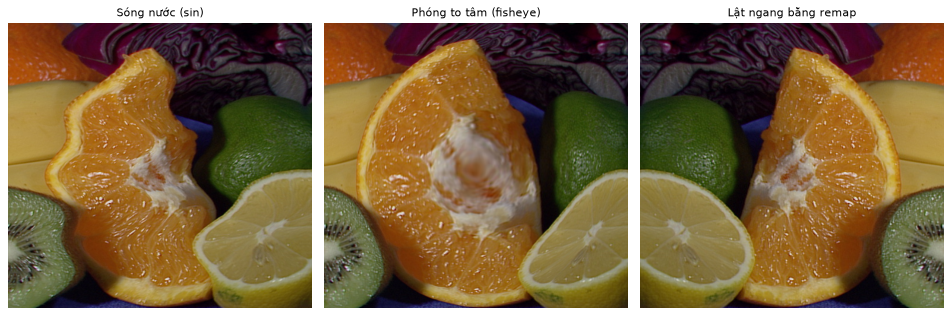

In [31]:
h, w = img.shape[:2]
map_x, map_y = np.meshgrid(np.arange(w, dtype=np.float32), np.arange(h, dtype=np.float32))

wave = cv2.remap(img, map_x + 12 * np.sin(map_y / 18), map_y,
                 cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)

# Hiệu ứng "kính lúp/mắt cá" quanh tâm
cx, cy = w / 2, h / 2
dx, dy = map_x - cx, map_y - cy
r = np.sqrt(dx**2 + dy**2)
R = min(w, h) / 2
factor = np.where(r < R, (r / R) ** 0.6, 1.0).astype(np.float32)   # co bán kính vào tâm -> phóng to tâm
fish = cv2.remap(img, cx + dx * factor, cy + dy * factor, cv2.INTER_LINEAR)

mirror = cv2.remap(img, (w - 1 - map_x), map_y, cv2.INTER_LINEAR)  # = flip ngang, viết bằng remap
show([wave, fish, mirror], ['Sóng nước (sin)', 'Phóng to tâm (fisheye)', 'Lật ngang bằng remap'])

✍️ **Bài tập 7:** Viết hàm `zoom_center(img, factor)` phóng to vùng trung tâm ảnh (crop + resize) và so sánh với dùng `warpAffine` với scale.

---
## 8. Độ sáng, tương phản và Gamma

### 8.1. Biến đổi tuyến tính

$$g(x, y) = \alpha \cdot f(x, y) + \beta$$

- $\alpha > 1$: tăng **tương phản**; $0 < \alpha < 1$: giảm tương phản.
- $\beta > 0$: tăng **độ sáng**; $\beta < 0$: giảm.

`cv2.convertScaleAbs(img, alpha=α, beta=β)` thực hiện công thức trên, lấy trị tuyệt đối và bão hòa về `uint8`.

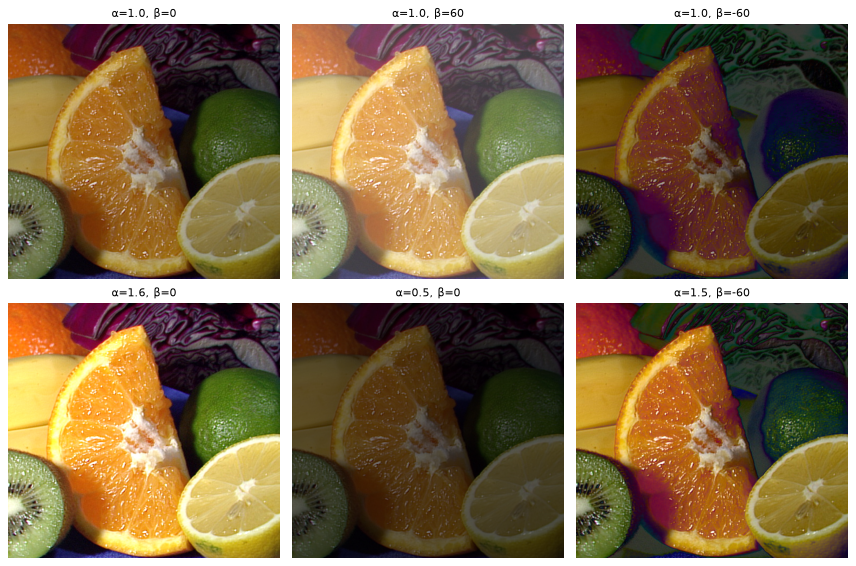

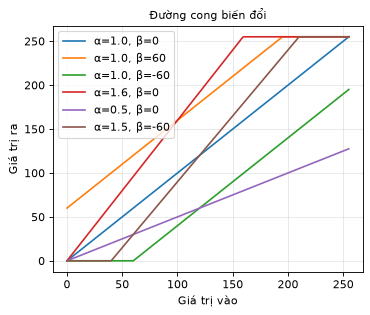

In [32]:
params = [(1.0, 0), (1.0, 60), (1.0, -60), (1.6, 0), (0.5, 0), (1.5, -60)]
outs = [cv2.convertScaleAbs(img, alpha=a, beta=b) for a, b in params]
show(outs, [f'α={a}, β={b}' for a, b in params], cols=3, size=3.6)

x = np.arange(256)
plt.figure(figsize=(5, 4))
for a, b in params:
    plt.plot(x, np.clip(a * x + b, 0, 255), label=f'α={a}, β={b}')
plt.xlabel('Giá trị vào'); plt.ylabel('Giá trị ra'); plt.title('Đường cong biến đổi'); plt.legend(); plt.grid(alpha=.3)
plt.show()

### 8.2. Hiệu chỉnh Gamma — `cv2.LUT`

$$O = 255 \cdot \left(\frac{I}{255}\right)^{\gamma}$$

- $\gamma < 1$: **làm sáng vùng tối** mạnh hơn vùng sáng (rất hợp với ảnh thiếu sáng).
- $\gamma > 1$: làm tối, tăng chi tiết vùng sáng.

Khác với cộng β (nâng đều mọi pixel, dễ "cháy" vùng sáng), gamma là phép biến đổi **phi tuyến**.

**LUT (Look-Up Table)**: vì `uint8` chỉ có 256 giá trị, ta tính trước bảng 256 phần tử rồi tra bảng ⇒ cực nhanh với mọi phép biến đổi điểm.

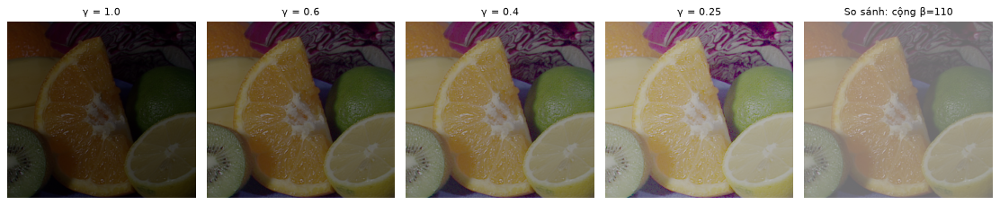

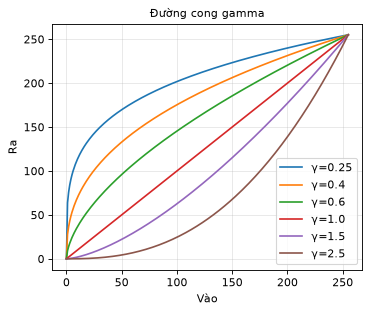

In [33]:
def adjust_gamma(image, gamma):
    table = np.array([((i / 255.0) ** gamma) * 255 for i in range(256)]).astype(np.uint8)
    return cv2.LUT(image, table)


dark = cv2.convertScaleAbs(img, alpha=0.35, beta=0)       # giả lập ảnh thiếu sáng
gammas = [1.0, 0.6, 0.4, 0.25]
show([adjust_gamma(dark, g) for g in gammas] + [cv2.add(dark, np.full_like(dark, 110))],
     [f'γ = {g}' for g in gammas] + ['So sánh: cộng β=110'], cols=5, size=2.8)

plt.figure(figsize=(5, 4))
for g in [0.25, 0.4, 0.6, 1.0, 1.5, 2.5]:
    plt.plot(x, 255 * (x / 255) ** g, label=f'γ={g}')
plt.legend(); plt.grid(alpha=.3); plt.title('Đường cong gamma'); plt.xlabel('Vào'); plt.ylabel('Ra')
plt.show()

🔍 **Nhận xét:** Với γ = 0.4, chi tiết trong vùng tối hiện rõ mà vùng sáng không bị cháy. Cộng β=110 làm ảnh "bạc màu" (mọi pixel bị nâng đều, tương phản giảm).

### 8.3. Kéo giãn tương phản tự động — `cv2.normalize`

Ảnh có tương phản thấp chỉ dùng một dải hẹp (vd 90–160). Kéo giãn tuyến tính dải đó ra 0–255:

$$O = \frac{I - I_{min}}{I_{max} - I_{min}} \times 255$$

Ảnh tương phản thấp: min = 90 , max = 161
Sau normalize      : min = 0 , max = 255


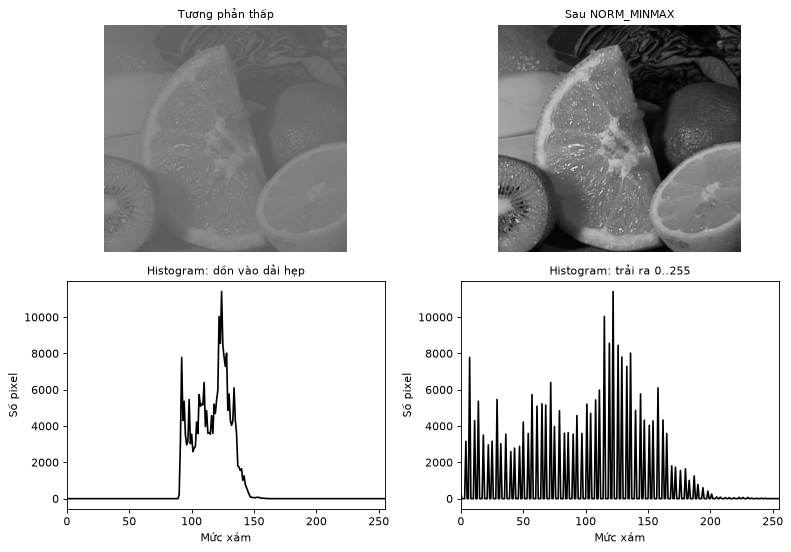

In [34]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
low = cv2.convertScaleAbs(gray, alpha=0.3, beta=90)           # giả lập ảnh tương phản thấp
stretched = cv2.normalize(low, None, 0, 255, cv2.NORM_MINMAX)
print('Ảnh tương phản thấp: min =', low.min(), ', max =', low.max())
print('Sau normalize      : min =', stretched.min(), ', max =', stretched.max())

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].imshow(low, cmap='gray', vmin=0, vmax=255); axes[0, 0].set_title('Tương phản thấp'); axes[0, 0].axis('off')
axes[0, 1].imshow(stretched, cmap='gray', vmin=0, vmax=255); axes[0, 1].set_title('Sau NORM_MINMAX'); axes[0, 1].axis('off')
plot_hist(low, axes[1, 0], 'Histogram: dồn vào dải hẹp')
plot_hist(stretched, axes[1, 1], 'Histogram: trải ra 0..255')
plt.tight_layout(); plt.show()

---
## 9. Histogram và cân bằng histogram

### 9.1. Histogram là gì?

**Histogram** đếm số pixel ở mỗi mức xám 0..255. Nó cho biết "phân bố độ sáng" của ảnh:
- Dồn về **bên trái** → ảnh tối; dồn về **bên phải** → ảnh sáng.
- Dồn vào một **dải hẹp** → tương phản thấp; trải rộng → tương phản cao.

```python
hist = cv2.calcHist([img], channels=[0], mask=None, histSize=[256], ranges=[0, 256])
```

hist.shape = (256,) | tổng = 245760 = số pixel 245760


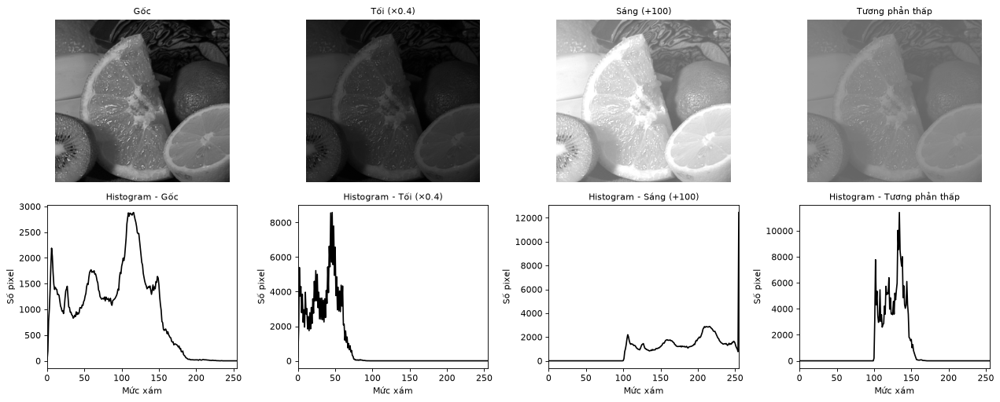

In [35]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
print('hist.shape =', hist.shape, '| tổng =', int(hist.sum()), '= số pixel', gray.size)

variants = {'Gốc': gray,
            'Tối (×0.4)': cv2.convertScaleAbs(gray, alpha=0.4),
            'Sáng (+100)': cv2.add(gray, np.full_like(gray, 100)),
            'Tương phản thấp': cv2.convertScaleAbs(gray, alpha=0.3, beta=100)}
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for i, (name, im) in enumerate(variants.items()):
    axes[0, i].imshow(im, cmap='gray', vmin=0, vmax=255); axes[0, i].set_title(name); axes[0, i].axis('off')
    plot_hist(im, axes[1, i], f'Histogram - {name}')
plt.tight_layout(); plt.show()

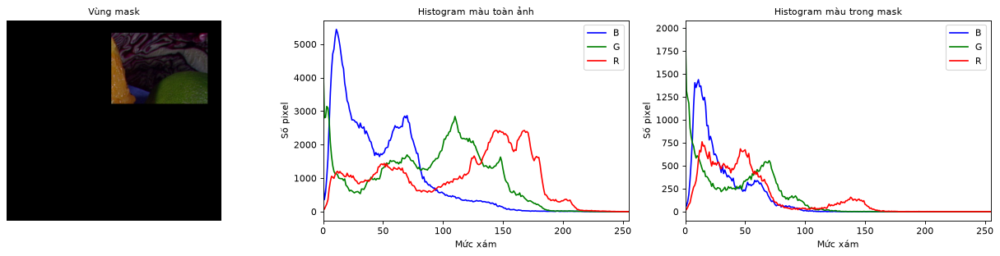

In [36]:
# Histogram màu và histogram có mask (chỉ tính trong 1 vùng)
mask = np.zeros(gray.shape, np.uint8)
mask[30:200, 250:480] = 255                         # vùng chứa chuối
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].imshow(cv2.cvtColor(cv2.bitwise_and(img, img, mask=mask), cv2.COLOR_BGR2RGB)); axes[0].axis('off')
axes[0].set_title('Vùng mask')
plot_hist(img, axes[1], 'Histogram màu toàn ảnh')
plot_hist(img, axes[2], 'Histogram màu trong mask', mask=mask)
plt.tight_layout(); plt.show()

### 9.2. Cân bằng histogram — `cv2.equalizeHist`

Ý tưởng: biến đổi mức xám sao cho histogram **trải đều** hơn, dùng **hàm phân bố tích lũy (CDF)**:

$$O(v) = \text{round}\left(\frac{CDF(v) - CDF_{min}}{N - CDF_{min}} \times 255\right)$$

Kết quả: tăng tương phản toàn cục, tự động, không cần tham số. Chỉ áp dụng cho ảnh **1 kênh**.

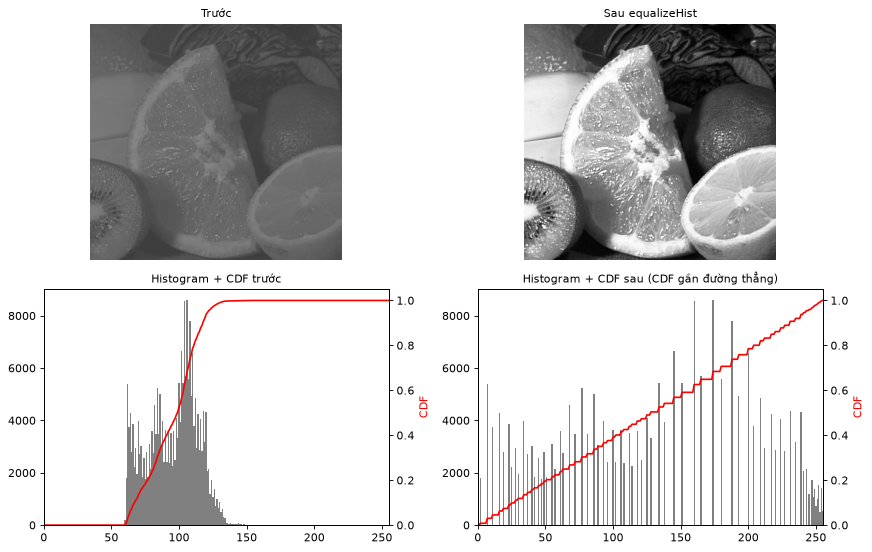

In [37]:
low = cv2.convertScaleAbs(gray, alpha=0.4, beta=60)
eq = cv2.equalizeHist(low)


def plot_hist_cdf(im, ax, title):
    hist = cv2.calcHist([im], [0], None, [256], [0, 256]).ravel()
    cdf = hist.cumsum()
    ax.bar(range(256), hist, color='gray', width=1)
    ax2 = ax.twinx(); ax2.plot(cdf / cdf.max(), 'r'); ax2.set_ylim(0, 1.05); ax2.set_ylabel('CDF', color='r')
    ax.set_xlim(0, 255); ax.set_title(title)


fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].imshow(low, cmap='gray', vmin=0, vmax=255); axes[0, 0].set_title('Trước'); axes[0, 0].axis('off')
axes[0, 1].imshow(eq, cmap='gray', vmin=0, vmax=255); axes[0, 1].set_title('Sau equalizeHist'); axes[0, 1].axis('off')
plot_hist_cdf(low, axes[1, 0], 'Histogram + CDF trước')
plot_hist_cdf(eq, axes[1, 1], 'Histogram + CDF sau (CDF gần đường thẳng)')
plt.tight_layout(); plt.show()

### 9.3. CLAHE — Cân bằng histogram thích nghi có giới hạn

`equalizeHist` dùng **một** phép biến đổi cho cả ảnh ⇒ có thể làm cháy vùng sáng, khuếch đại nhiễu. **CLAHE** (Contrast Limited Adaptive Histogram Equalization):
1. Chia ảnh thành lưới ô nhỏ (`tileGridSize`, vd 8×8).
2. Cân bằng histogram **trong từng ô**.
3. **Cắt** histogram tại `clipLimit` để không khuếch đại nhiễu quá mức.
4. Nội suy song tuyến tính giữa các ô để không thấy đường biên ô.

Rất hay dùng cho ảnh y tế, ảnh chụp ngược sáng, ảnh trước khi nhận dạng.

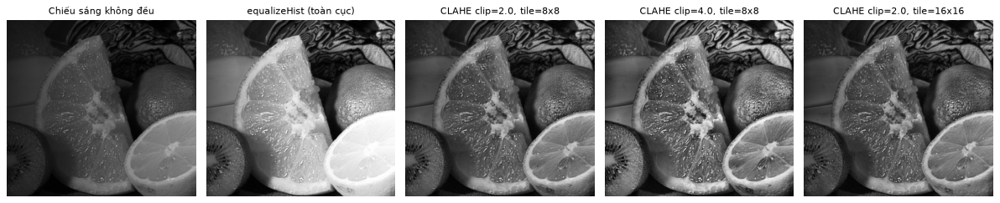

In [38]:
# Ảnh có chiếu sáng không đều: bên trái tối, bên phải sáng
h, w = gray.shape
shade = np.tile(np.linspace(0.25, 1.2, w), (h, 1))
uneven = np.clip(gray * shade, 0, 255).astype(np.uint8)

outs = [uneven, cv2.equalizeHist(uneven)]
titles = ['Chiếu sáng không đều', 'equalizeHist (toàn cục)']
for clip, tile in [(2.0, 8), (4.0, 8), (2.0, 16)]:
    clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile))
    outs.append(clahe.apply(uneven)); titles.append(f'CLAHE clip={clip}, tile={tile}x{tile}')
show(outs, titles, cols=5, size=3)

### 9.4. Cân bằng histogram cho ảnh màu — làm ĐÚNG cách

❌ **Sai:** cân bằng riêng từng kênh B, G, R ⇒ tỉ lệ giữa các kênh bị phá vỡ ⇒ **lệch màu**.

✅ **Đúng:** chuyển sang không gian tách độ sáng (YCrCb / LAB / HSV), **chỉ cân bằng kênh độ sáng**, rồi chuyển ngược lại.

C:\Users\Dell\AppData\Local\Temp\ipykernel_13832\1805128670.py:53: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Dell\AppData\Local\Temp\ipykernel_13832\1805128670.py:53: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


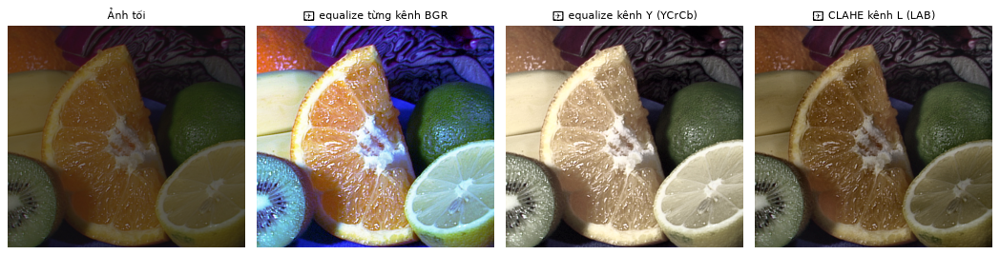

In [39]:
dark_color = cv2.convertScaleAbs(img, alpha=0.5, beta=10)

# Sai: từng kênh
wrong = cv2.merge([cv2.equalizeHist(ch) for ch in cv2.split(dark_color)])

# Đúng 1: kênh Y trong YCrCb
ycc = cv2.cvtColor(dark_color, cv2.COLOR_BGR2YCrCb)
ycc[..., 0] = cv2.equalizeHist(ycc[..., 0])
right_y = cv2.cvtColor(ycc, cv2.COLOR_YCrCb2BGR)

# Đúng 2: CLAHE trên kênh L của LAB (thường đẹp nhất)
lab = cv2.cvtColor(dark_color, cv2.COLOR_BGR2LAB)
lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
right_lab = cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

show([dark_color, wrong, right_y, right_lab],
     ['Ảnh tối', '❌ equalize từng kênh BGR', '✅ equalize kênh Y (YCrCb)', '✅ CLAHE kênh L (LAB)'], cols=4, size=3.3)

### 9.5. So sánh histogram — `cv2.compareHist`

Có thể dùng histogram như một "chữ ký màu" để so sánh độ giống nhau giữa các ảnh (tìm ảnh tương tự). Phương pháp `HISTCMP_CORREL`: 1 = giống hệt.

In [40]:
def hsv_hist(image):
    hsv_ = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    hst = cv2.calcHist([hsv_], [0, 1], None, [50, 60], [0, 180, 0, 256])   # histogram 2D theo H và S
    return cv2.normalize(hst, hst).flatten()


base = hsv_hist(img)
cands = {'fruits sáng hơn': cv2.add(img, np.full_like(img, 40)),
         'fruits lật ngang': cv2.flip(img, 1),
         'building': load_sample('building.jpg'),
         'smarties': load_sample('smarties.png')}
for name, cimg in cands.items():
    print(f'{name:18s}: correlation = {cv2.compareHist(base, hsv_hist(cimg), cv2.HISTCMP_CORREL):.3f}')

fruits sáng hơn   : correlation = 0.433
fruits lật ngang  : correlation = 1.000
building          : correlation = -0.002
smarties          : correlation = 0.007


🔍 **Nhận xét:** Ảnh lật ngang có histogram **giống hệt** (histogram không quan tâm vị trí pixel) — vừa là ưu điểm (bất biến với xoay/lật) vừa là nhược điểm (hai ảnh khác nhau hoàn toàn vẫn có thể cùng histogram).

---
## 10. Phân ngưỡng (Thresholding) — tạo ảnh nhị phân

Phân ngưỡng chuyển ảnh xám thành ảnh **nhị phân** (đen/trắng) — bước tiền xử lý quan trọng cho contour, OCR, đo đạc…

### 10.1. Ngưỡng toàn cục — `cv2.threshold(src, T, maxval, type)`

| Loại | Công thức (pixel `v`, ngưỡng `T`) |
|---|---|
| `THRESH_BINARY` | `maxval` nếu v > T, ngược lại 0 |
| `THRESH_BINARY_INV` | 0 nếu v > T, ngược lại `maxval` |
| `THRESH_TRUNC` | T nếu v > T, ngược lại giữ v |
| `THRESH_TOZERO` | giữ v nếu v > T, ngược lại 0 |
| `THRESH_TOZERO_INV` | 0 nếu v > T, ngược lại giữ v |

Hàm trả về **2 giá trị**: `(ngưỡng_đã_dùng, ảnh_kết_quả)`.

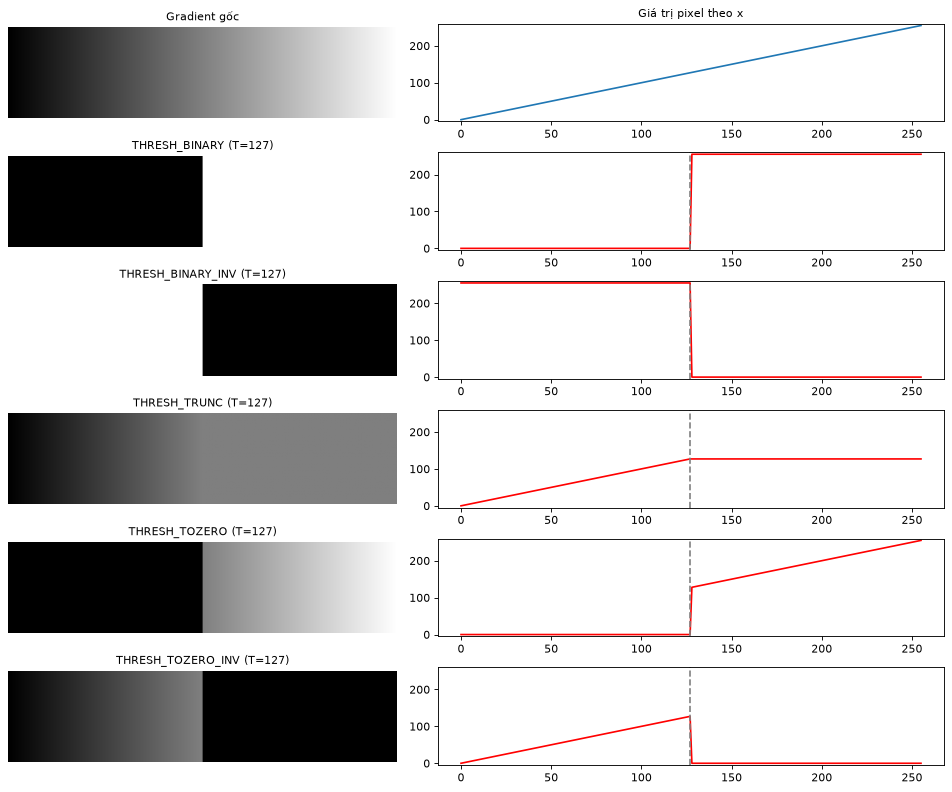

In [41]:
grad = np.tile(np.linspace(0, 255, 256, dtype=np.uint8), (60, 1))   # dải gradient đen -> trắng
types = ['THRESH_BINARY', 'THRESH_BINARY_INV', 'THRESH_TRUNC', 'THRESH_TOZERO', 'THRESH_TOZERO_INV']
fig, axes = plt.subplots(len(types) + 1, 2, figsize=(12, 10), gridspec_kw={'width_ratios': [1, 1.3]})
axes[0, 0].imshow(grad, cmap='gray', vmin=0, vmax=255); axes[0, 0].set_title('Gradient gốc'); axes[0, 0].axis('off')
axes[0, 1].plot(grad[0]); axes[0, 1].set_title('Giá trị pixel theo x'); axes[0, 1].set_ylim(-5, 260)
for i, t in enumerate(types, start=1):
    _, out = cv2.threshold(grad, 127, 255, getattr(cv2, t))
    axes[i, 0].imshow(out, cmap='gray', vmin=0, vmax=255); axes[i, 0].set_title(f'{t} (T=127)'); axes[i, 0].axis('off')
    axes[i, 1].plot(out[0], 'r'); axes[i, 1].set_ylim(-5, 260); axes[i, 1].axvline(127, ls='--', c='gray')
plt.tight_layout(); plt.show()

### 10.2. Ngưỡng Otsu — tự động chọn ngưỡng

Chọn ngưỡng tay rất khó. **Otsu** tự tìm T **tối đa hóa phương sai giữa hai lớp** (nền và đối tượng):

$$T^* = \arg\max_T \; \omega_0(T)\,\omega_1(T)\,[\mu_0(T) - \mu_1(T)]^2$$

Hoạt động tốt khi histogram có **2 đỉnh** (bimodal). Dùng bằng cách cộng cờ: `cv2.THRESH_BINARY + cv2.THRESH_OTSU` (tham số T truyền vào bị bỏ qua, thường để 0).

Ví dụ kinh điển: ảnh nhiễu → Otsu trực tiếp kém; **làm mờ Gauss trước** rồi Otsu → tốt hơn nhiều.

Otsu trên ảnh nhiễu chọn T = 122; trên ảnh đã làm mờ chọn T = 124


C:\Users\Dell\AppData\Local\Temp\ipykernel_13832\2448144336.py:19: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  axes[i, 1].hist(src.ravel(), 256, (0, 256), color='gray'); axes[i, 1].axvline(t, c='r', lw=2)


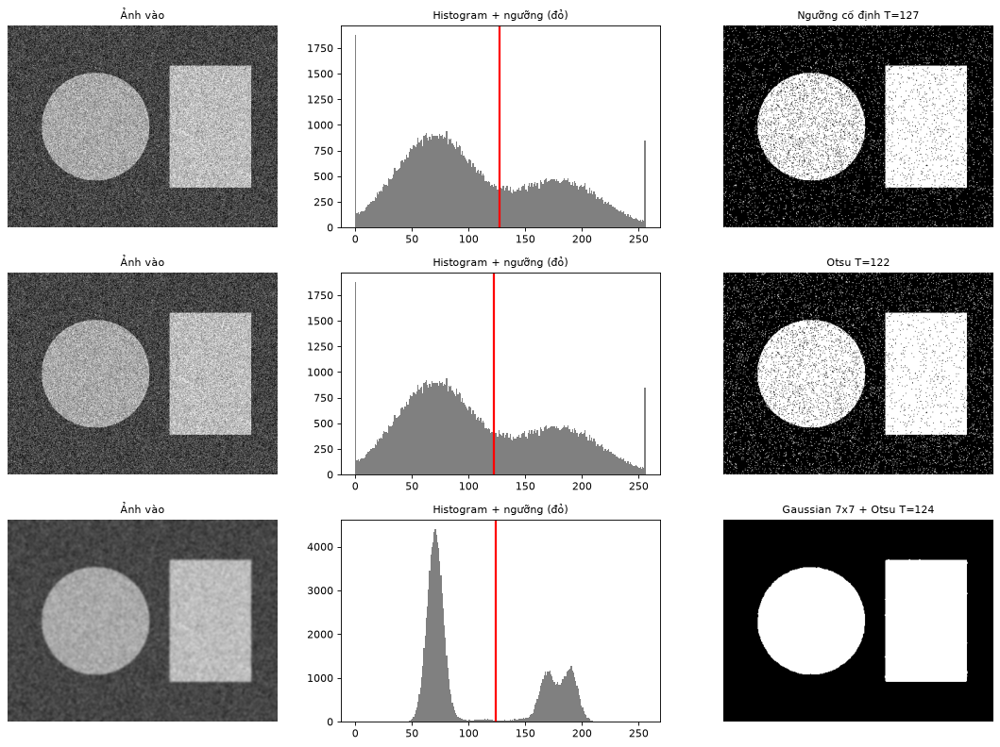

In [42]:
rng = np.random.default_rng(1)
bimodal = np.full((300, 400), 70, np.uint8)
cv2.circle(bimodal, (130, 150), 80, 170, -1)
cv2.rectangle(bimodal, (240, 60), (360, 240), 190, -1)
noisy = np.clip(bimodal + rng.normal(0, 35, bimodal.shape), 0, 255).astype(np.uint8)

_, th_fixed = cv2.threshold(noisy, 127, 255, cv2.THRESH_BINARY)
t_otsu, th_otsu = cv2.threshold(noisy, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
blur = cv2.GaussianBlur(noisy, (7, 7), 0)
t_otsu2, th_otsu2 = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f'Otsu trên ảnh nhiễu chọn T = {t_otsu:.0f}; trên ảnh đã làm mờ chọn T = {t_otsu2:.0f}')

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
rows = [(noisy, th_fixed, 'Ngưỡng cố định T=127', 127),
        (noisy, th_otsu, f'Otsu T={t_otsu:.0f}', t_otsu),
        (blur, th_otsu2, f'Gaussian 7x7 + Otsu T={t_otsu2:.0f}', t_otsu2)]
for i, (src, out, name, t) in enumerate(rows):
    axes[i, 0].imshow(src, cmap='gray', vmin=0, vmax=255); axes[i, 0].set_title('Ảnh vào'); axes[i, 0].axis('off')
    axes[i, 1].hist(src.ravel(), 256, (0, 256), color='gray'); axes[i, 1].axvline(t, c='r', lw=2)
    axes[i, 1].set_title('Histogram + ngưỡng (đỏ)')
    axes[i, 2].imshow(out, cmap='gray'); axes[i, 2].set_title(name); axes[i, 2].axis('off')
plt.tight_layout(); plt.show()

🔍 **Nhận xét:** Sau khi làm mờ, histogram tách thành **hai đỉnh rõ ràng** ⇒ Otsu chọn ngưỡng nằm giữa thung lũng và kết quả sạch hơn nhiều. Bài học: **khử nhiễu trước khi phân ngưỡng**.

### 10.3. Ngưỡng thích nghi — `cv2.adaptiveThreshold`

Khi ánh sáng **không đều** (một bên sáng, một bên tối), một ngưỡng toàn cục không thể đúng cho mọi nơi. Ngưỡng thích nghi tính **ngưỡng riêng cho từng pixel** dựa trên vùng lân cận `blockSize × blockSize`:

$$T(x,y) = \text{mean hoặc gaussian\_mean}(\text{lân cận}) - C$$

```python
cv2.adaptiveThreshold(src, 255, method, type, blockSize, C)
# method: cv2.ADAPTIVE_THRESH_MEAN_C hoặc cv2.ADAPTIVE_THRESH_GAUSSIAN_C
# blockSize: số lẻ (3, 5, 7, ..., 11, 21...)
# C: hằng số trừ đi (tăng C -> ít pixel trắng/nhiễu hơn với THRESH_BINARY)
```

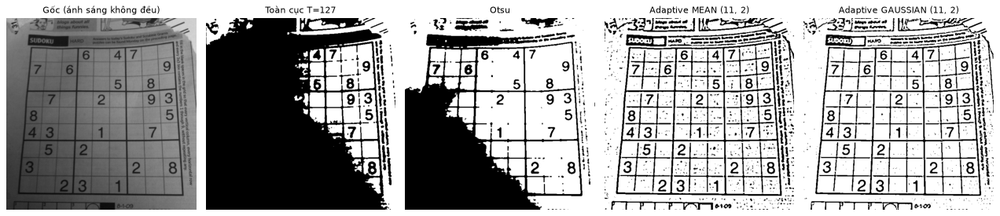

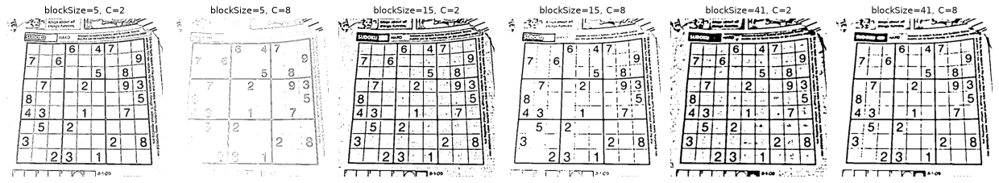

In [43]:
sud_gray = cv2.cvtColor(sudoku, cv2.COLOR_BGR2GRAY)
sud_blur = cv2.medianBlur(sud_gray, 5)

_, g1 = cv2.threshold(sud_blur, 127, 255, cv2.THRESH_BINARY)
_, g2 = cv2.threshold(sud_blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
a1 = cv2.adaptiveThreshold(sud_blur, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 2)
a2 = cv2.adaptiveThreshold(sud_blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)
show([sud_gray, g1, g2, a1, a2],
     ['Gốc (ánh sáng không đều)', 'Toàn cục T=127', 'Otsu', 'Adaptive MEAN (11, 2)', 'Adaptive GAUSSIAN (11, 2)'],
     cols=5, size=3.2)

# Ảnh hưởng của blockSize và C
outs, titles = [], []
for bs in [5, 15, 41]:
    for C in [2, 8]:
        outs.append(cv2.adaptiveThreshold(sud_blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, bs, C))
        titles.append(f'blockSize={bs}, C={C}')
show(outs, titles, cols=6, size=2.6)

🔍 **Nhận xét:**
- Ngưỡng toàn cục / Otsu làm **mất trắng hoặc đen hẳn** một vùng do bóng đổ.
- Adaptive giữ được nét chữ số và đường kẻ ở **mọi vùng sáng/tối**.
- `blockSize` nhỏ → chi tiết mảnh nhưng nhiễu; lớn → giống ngưỡng toàn cục hơn. `C` lớn → bớt nhiễu nền.

✍️ **Bài tập 10:** Áp dụng ngưỡng Otsu cho kênh S (saturation) của `smarties.png` để tách kẹo khỏi nền.

---
## 11. Tích chập và lọc ảnh: làm mịn & khử nhiễu

### 11.1. Tích chập (convolution) là gì?

Ta trượt một **ma trận nhỏ (kernel)** trên ảnh; tại mỗi vị trí, pixel mới = **tổng có trọng số** của các pixel lân cận:

$$g(x,y) = \sum_{i=-k}^{k}\sum_{j=-k}^{k} K(i,j)\, f(x+j,\, y+i)$$

> 📝 Về lý thuyết, tích chập phải *lật* kernel 180°. `cv2.filter2D` thực ra tính **tương quan (correlation)**, không lật kernel. Với kernel đối xứng (blur, Gauss, Laplace) hai cách cho kết quả như nhau.

Ví dụ thủ công với kernel trung bình 3×3:

In [44]:
f = np.array([[10, 10, 10, 10, 10],
              [10, 50, 50, 50, 10],
              [10, 50, 90, 50, 10],
              [10, 50, 50, 50, 10],
              [10, 10, 10, 10, 10]], np.float32)
K = np.ones((3, 3), np.float32) / 9

# Tính tay tại tâm (y=2, x=2)
manual = (f[1:4, 1:4] * K).sum()
print('Vùng 3x3 quanh tâm:\n', f[1:4, 1:4])
print(f'Tính tay tại tâm = tổng(vùng * K) = {manual:.2f}')

out = cv2.filter2D(f, -1, K, borderType=cv2.BORDER_REPLICATE)   # ddepth=-1: cùng kiểu với ảnh vào
print('Kết quả cv2.filter2D:\n', out.round(1))

Vùng 3x3 quanh tâm:
 [[50. 50. 50.]
 [50. 90. 50.]
 [50. 50. 50.]]
Tính tay tại tâm = tổng(vùng * K) = 54.44
Kết quả cv2.filter2D:
 [[14.4 18.9 23.3 18.9 14.4]
 [18.9 32.2 41.1 32.2 18.9]
 [23.3 41.1 54.4 41.1 23.3]
 [18.9 32.2 41.1 32.2 18.9]
 [14.4 18.9 23.3 18.9 14.4]]


### 11.2. Các kernel cơ bản và hiệu ứng

Cùng một hàm `cv2.filter2D`, chỉ thay kernel là được nhiều hiệu ứng khác nhau:

Identity:
[[0. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]]

Box blur 5x5:
[[0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]]

Sharpen:
[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]

Edge (Laplacian):
[[-1. -1. -1.]
 [-1.  8. -1.]
 [-1. -1. -1.]]

Emboss:
[[-2. -1.  0.]
 [-1.  1.  1.]
 [ 0.  1.  2.]]



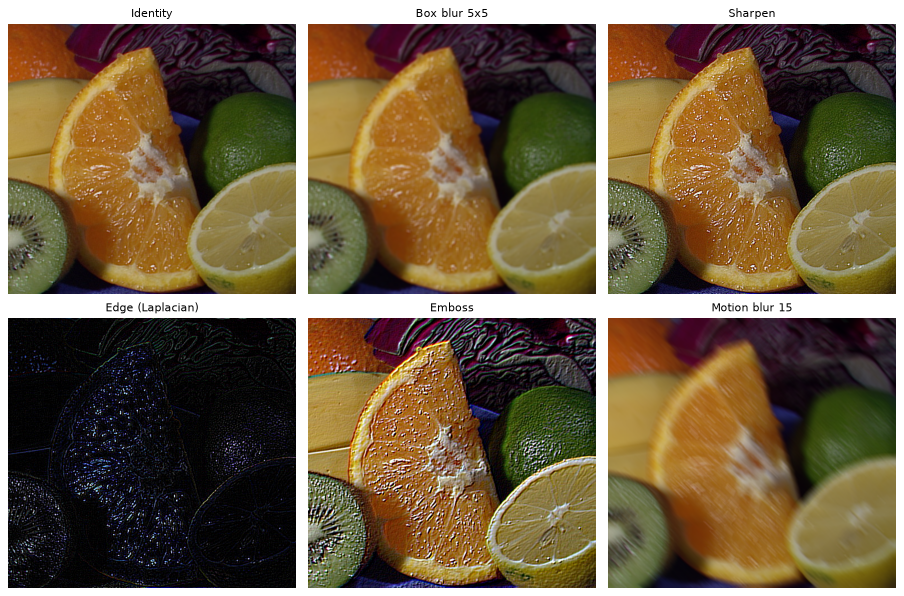

In [45]:
kernels = {
    'Identity':        np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], np.float32),
    'Box blur 5x5':    np.ones((5, 5), np.float32) / 25,
    'Sharpen':         np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32),
    'Edge (Laplacian)':np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], np.float32),
    'Emboss':          np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], np.float32),
    'Motion blur 15':  np.eye(15, dtype=np.float32) / 15,
}
for name, k in list(kernels.items())[:5]:
    print(f'{name}:\n{np.round(k, 3)}\n')
show([cv2.filter2D(img, -1, k) for k in kernels.values()], list(kernels.keys()), cols=3, size=3.8)

### 11.3. Bốn bộ lọc làm mịn chính của OpenCV

| Hàm | Nguyên lý | Ưu điểm | Nhược điểm |
|---|---|---|---|
| `cv2.blur(img, (k,k))` | trung bình đều | nhanh nhất | mờ cả cạnh, tạo "khối" |
| `cv2.GaussianBlur(img, (k,k), σ)` | trung bình theo trọng số Gauss (gần tâm nặng hơn) | tự nhiên, khử **nhiễu Gauss** tốt | vẫn mờ cạnh |
| `cv2.medianBlur(img, k)` | lấy **trung vị** | khử **nhiễu muối tiêu** cực tốt, giữ cạnh | chậm hơn với k lớn |
| `cv2.bilateralFilter(img, d, σColor, σSpace)` | Gauss theo **khoảng cách** × Gauss theo **chênh lệch màu** | **giữ cạnh** rất tốt | chậm |

> ⚠️ Kích thước kernel `k` phải là **số lẻ** (3, 5, 7…) để có pixel tâm. Trong `GaussianBlur`, σ = 0 nghĩa là tự tính từ k.

Hệ số kernel Gauss 1D (5 phần tử):

In [46]:
g1d = cv2.getGaussianKernel(5, 1.0)
print('Gaussian 1D (k=5, σ=1):', g1d.ravel().round(4))
print('Gaussian 2D = g1d · g1dᵀ:\n', (g1d @ g1d.T).round(4))

# Tạo 2 loại nhiễu
def add_gaussian_noise(image, sigma=20, seed=0):
    rng = np.random.default_rng(seed)
    return np.clip(image.astype(np.float32) + rng.normal(0, sigma, image.shape), 0, 255).astype(np.uint8)


def add_salt_pepper(image, amount=0.05, seed=0):
    rng = np.random.default_rng(seed)
    out = image.copy()
    m = rng.random(image.shape[:2])
    out[m < amount / 2] = 0          # tiêu (đen)
    out[m > 1 - amount / 2] = 255    # muối (trắng)
    return out


clean = img.copy()
n_gauss = add_gaussian_noise(clean, 25)
n_sp = add_salt_pepper(clean, 0.08)

filters = {
    'blur 5x5':        lambda x: cv2.blur(x, (5, 5)),
    'Gaussian 5x5':    lambda x: cv2.GaussianBlur(x, (5, 5), 0),
    'median 5':        lambda x: cv2.medianBlur(x, 5),
    'bilateral 9,75,75': lambda x: cv2.bilateralFilter(x, 9, 75, 75),
}
print(f'\n{"Bộ lọc":18s} | PSNR nhiễu Gauss | PSNR nhiễu muối tiêu')
print(f'{"(chưa lọc)":18s} | {cv2.PSNR(clean, n_gauss):10.2f} dB   | {cv2.PSNR(clean, n_sp):10.2f} dB')
res_g, res_sp = [], []
for name, fn in filters.items():
    a, b = fn(n_gauss), fn(n_sp)
    res_g.append(a); res_sp.append(b)
    print(f'{name:18s} | {cv2.PSNR(clean, a):10.2f} dB   | {cv2.PSNR(clean, b):10.2f} dB')

Gaussian 1D (k=5, σ=1): [0.0545 0.2442 0.4026 0.2442 0.0545]
Gaussian 2D = g1d · g1dᵀ:
 [[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]

Bộ lọc             | PSNR nhiễu Gauss | PSNR nhiễu muối tiêu
(chưa lọc)         |      20.65 dB   |      15.84 dB
blur 5x5           |      27.80 dB   |      25.56 dB
Gaussian 5x5       |      29.03 dB   |      25.28 dB
median 5           |      27.55 dB   |      29.49 dB
bilateral 9,75,75  |      28.72 dB   |      15.86 dB


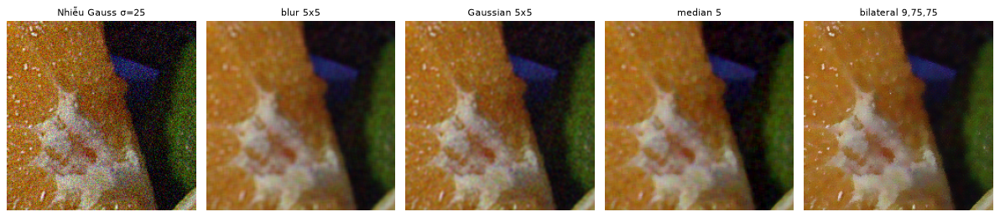

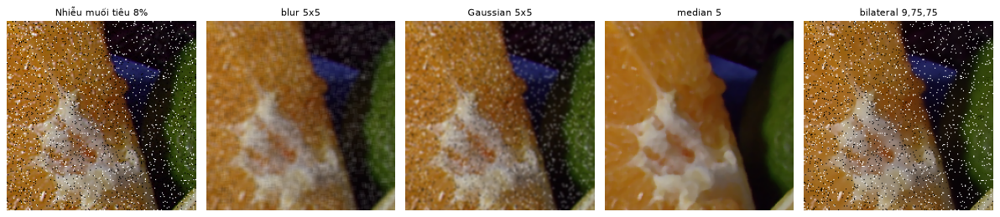

In [47]:
c = (slice(120, 320), slice(180, 380))     # phóng to một vùng để dễ so sánh
show([n_gauss[c]] + [r[c] for r in res_g], ['Nhiễu Gauss σ=25'] + list(filters.keys()), cols=5, size=3)
show([n_sp[c]] + [r[c] for r in res_sp], ['Nhiễu muối tiêu 8%'] + list(filters.keys()), cols=5, size=3)

🔍 **Nhận xét:**
- **Nhiễu muối tiêu** → `medianBlur` thắng tuyệt đối: các điểm trắng/đen cực trị không bao giờ là trung vị nên bị loại hoàn toàn. Lọc trung bình chỉ "trải" chúng ra thành vệt mờ.
- **Nhiễu Gauss** → Gaussian/bilateral tốt hơn.

### 11.4. Bilateral filter giữ cạnh như thế nào?

Ta vẽ **mặt cắt cường độ** qua một cạnh để thấy rõ:

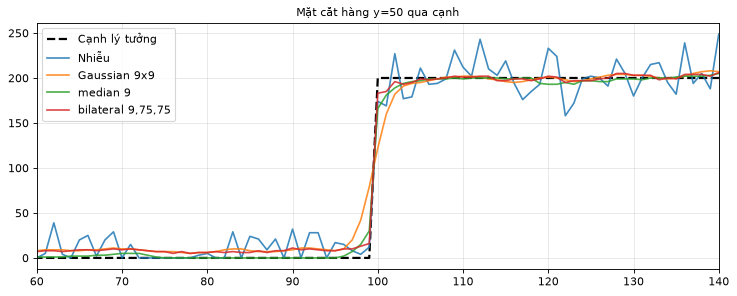

In [48]:
step = np.zeros((100, 200), np.uint8); step[:, 100:] = 200
step_n = add_gaussian_noise(step, 20, seed=3)
row = 50
outs = {'Nhiễu': step_n,
        'Gaussian 9x9': cv2.GaussianBlur(step_n, (9, 9), 0),
        'median 9': cv2.medianBlur(step_n, 9),
        'bilateral 9,75,75': cv2.bilateralFilter(step_n, 9, 75, 75)}
plt.figure(figsize=(11, 4))
plt.plot(step[row], 'k--', lw=2, label='Cạnh lý tưởng')
for name, o in outs.items():
    plt.plot(o[row], label=name, alpha=.85)
plt.xlim(60, 140); plt.legend(); plt.title(f'Mặt cắt hàng y={row} qua cạnh'); plt.grid(alpha=.3)
plt.show()

🔍 **Nhận xét:** Gaussian biến bước nhảy thành **dốc thoai thoải** (cạnh bị mờ); bilateral và median giữ **bước nhảy dốc đứng** trong khi vẫn làm phẳng nhiễu hai bên.

### 11.5. Ảnh hưởng của kích thước kernel & bộ khử nhiễu mạnh Non-Local Means

`cv2.fastNlMeansDenoisingColored` tìm các **mảng tương tự ở khắp ảnh** và lấy trung bình chúng ⇒ khử nhiễu rất tốt nhưng chậm hơn nhiều.

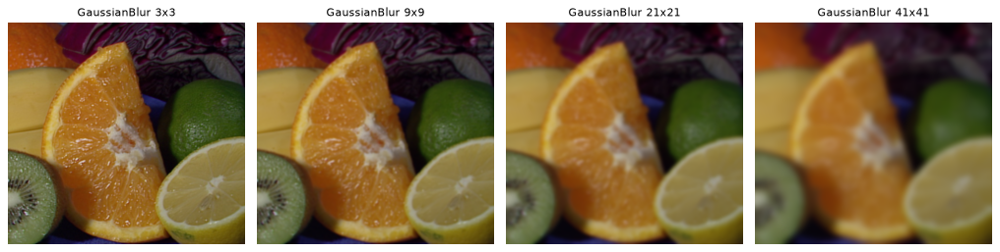

NLM: PSNR = 23.97 dB, thời gian = 0.36 s


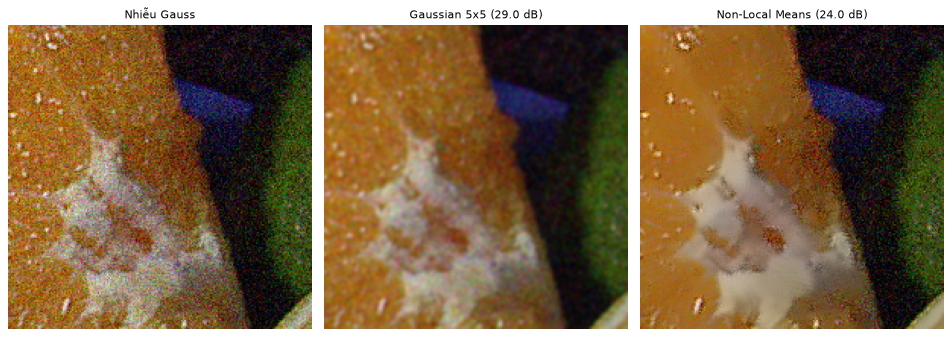

In [49]:
ks = [3, 9, 21, 41]
show([cv2.GaussianBlur(img, (k, k), 0) for k in ks], [f'GaussianBlur {k}x{k}' for k in ks], cols=4, size=3.2)

t = time.perf_counter()
nlm = cv2.fastNlMeansDenoisingColored(n_gauss, None, h=10, hColor=10, templateWindowSize=7, searchWindowSize=21)
t_nlm = time.perf_counter() - t
print(f'NLM: PSNR = {cv2.PSNR(clean, nlm):.2f} dB, thời gian = {t_nlm:.2f} s')
show([n_gauss[c], res_g[1][c], nlm[c]],
     ['Nhiễu Gauss', f'Gaussian 5x5 ({cv2.PSNR(clean, res_g[1]):.1f} dB)', f'Non-Local Means ({cv2.PSNR(clean, nlm):.1f} dB)'],
     size=4)

---
## 12. Làm sắc nét (Sharpening)

### 12.1. Kernel sharpen

Kernel `[[0,-1,0],[-1,5,-1],[0,-1,0]]` = ảnh gốc + (ảnh gốc − trung bình lân cận) ⇒ **khuếch đại chênh lệch** tại cạnh.

### 12.2. Unsharp Masking (cách chuyên nghiệp — dùng trong Photoshop)

$$\text{sharp} = \text{img} + \text{amount}\cdot(\text{img} - \text{blur(img)}) = (1+\text{amount})\cdot\text{img} - \text{amount}\cdot\text{blur}$$

- `img − blur` = **chi tiết tần số cao** (cạnh, kết cấu).
- `amount` điều khiển độ mạnh; σ của blur điều khiển độ "to" của chi tiết được làm nét.

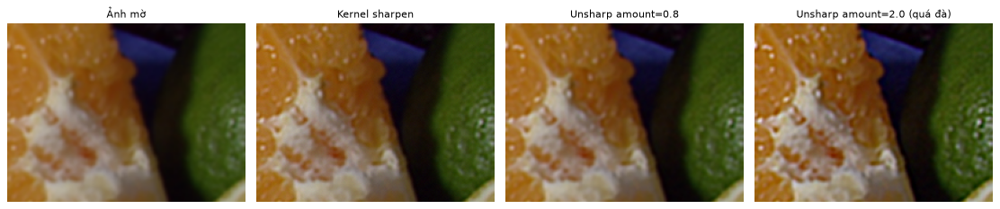

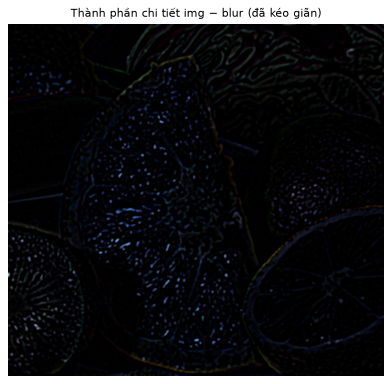

In [50]:
soft = cv2.GaussianBlur(img, (5, 5), 1.5)        # giả lập ảnh hơi mờ

k_sharp = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32)
sharp_k = cv2.filter2D(soft, -1, k_sharp)


def unsharp_mask(image, sigma=2.0, amount=1.0, threshold=0):
    blurred = cv2.GaussianBlur(image, (0, 0), sigma)
    sharp = cv2.addWeighted(image, 1 + amount, blurred, -amount, 0)
    if threshold > 0:                             # chỉ làm nét nơi chênh lệch đủ lớn (tránh khuếch đại nhiễu)
        low_contrast = cv2.absdiff(image, blurred) < threshold
        np.copyto(sharp, image, where=low_contrast)
    return sharp


c = (slice(150, 300), slice(200, 400))
outs = [soft, sharp_k, unsharp_mask(soft, 2, 0.8), unsharp_mask(soft, 2, 2.0)]
show([o[c] for o in outs], ['Ảnh mờ', 'Kernel sharpen', 'Unsharp amount=0.8', 'Unsharp amount=2.0 (quá đà)'],
     cols=4, size=3.5)
detail = cv2.subtract(soft, cv2.GaussianBlur(soft, (0, 0), 2))
show(cv2.normalize(detail, None, 0, 255, cv2.NORM_MINMAX), 'Thành phần chi tiết img − blur (đã kéo giãn)', size=5)

🔍 **Nhận xét:** `amount` quá lớn tạo **quầng sáng (halo)** quanh cạnh và khuếch đại nhiễu. Làm nét **không khôi phục** được chi tiết đã mất, chỉ tăng tương phản cục bộ tại cạnh.

---
## 13. Phát hiện cạnh (Edge Detection)

### 13.1. Cạnh = nơi cường độ thay đổi đột ngột

- **Đạo hàm bậc 1** (gradient): cạnh ứng với **cực đại** của |đạo hàm|. → Sobel, Scharr, Prewitt.
- **Đạo hàm bậc 2**: cạnh ứng với **điểm cắt 0** (zero-crossing). → Laplacian.

Xem trên tín hiệu 1D:

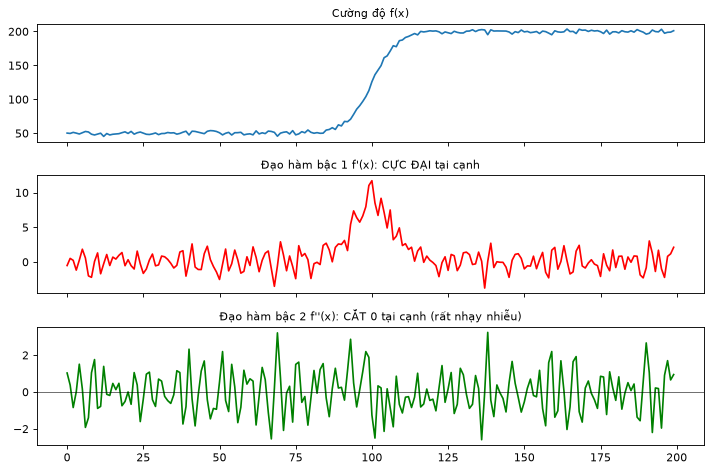

In [51]:
x1 = np.arange(200)
signal = 50 + 150 / (1 + np.exp(-(x1 - 100) / 4))            # cạnh mượt
signal_n = signal + np.random.default_rng(0).normal(0, 2, 200)
d1 = np.gradient(signal_n); d2 = np.gradient(d1)
fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
axes[0].plot(signal_n); axes[0].set_title('Cường độ f(x)')
axes[1].plot(d1, 'r'); axes[1].set_title("Đạo hàm bậc 1 f'(x): CỰC ĐẠI tại cạnh")
axes[2].plot(d2, 'g'); axes[2].axhline(0, c='k', lw=.5); axes[2].set_title("Đạo hàm bậc 2 f''(x): CẮT 0 tại cạnh (rất nhạy nhiễu)")
plt.tight_layout(); plt.show()

### 13.2. Sobel và Scharr

Kernel Sobel 3×3:

$$G_x = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}, \quad G_y = \begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix}$$

- $G_x$ phát hiện **cạnh dọc** (thay đổi theo x); $G_y$ phát hiện **cạnh ngang**.
- Độ lớn: $|G| = \sqrt{G_x^2 + G_y^2}$, hướng: $\theta = \arctan(G_y / G_x)$.

> ⚠️ Đạo hàm có thể **âm** (sáng → tối). Nếu dùng `ddepth=cv2.CV_8U` thì giá trị âm bị cắt về 0 ⇒ **mất một nửa số cạnh**! Hãy dùng `cv2.CV_64F` (hoặc `CV_16S`) rồi lấy trị tuyệt đối với `cv2.convertScaleAbs`.

C:\Users\Dell\AppData\Local\Temp\ipykernel_13832\1805128670.py:53: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


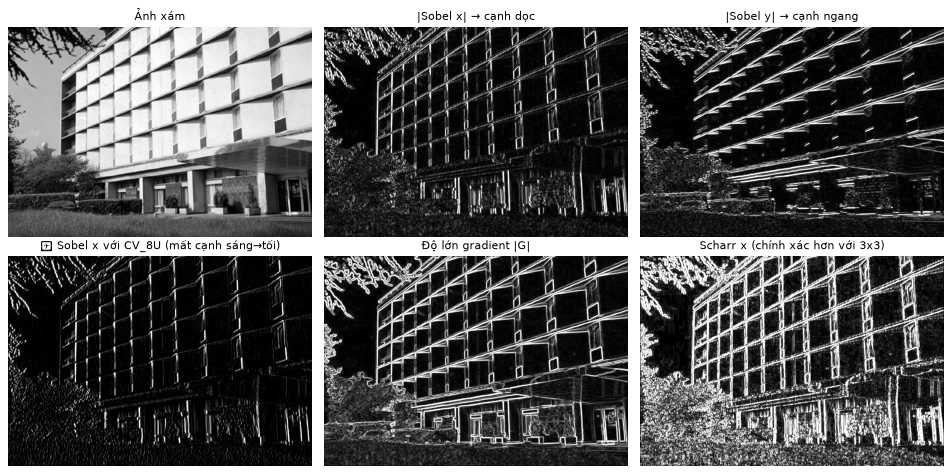

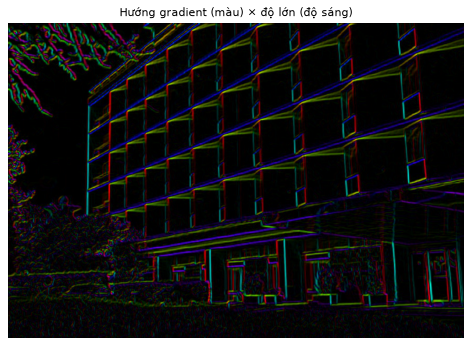

In [52]:
building = load_sample('building.jpg')
bgray = cv2.cvtColor(building, cv2.COLOR_BGR2GRAY)
bblur = cv2.GaussianBlur(bgray, (3, 3), 0)

gx = cv2.Sobel(bblur, cv2.CV_64F, 1, 0, ksize=3)   # dx=1, dy=0
gy = cv2.Sobel(bblur, cv2.CV_64F, 0, 1, ksize=3)   # dx=0, dy=1
mag = cv2.magnitude(gx, gy)
angle = cv2.phase(gx, gy, angleInDegrees=True)

gx_8u_wrong = cv2.Sobel(bblur, cv2.CV_8U, 1, 0, ksize=3)  # mất giá trị âm
show([bgray, cv2.convertScaleAbs(gx), cv2.convertScaleAbs(gy),
      gx_8u_wrong, cv2.convertScaleAbs(mag), cv2.convertScaleAbs(cv2.Scharr(bblur, cv2.CV_64F, 1, 0))],
     ['Ảnh xám', '|Sobel x| → cạnh dọc', '|Sobel y| → cạnh ngang',
      '❌ Sobel x với CV_8U (mất cạnh sáng→tối)', 'Độ lớn gradient |G|', 'Scharr x (chính xác hơn với 3x3)'],
     cols=3, size=4)

# Hiển thị hướng gradient bằng màu (H = hướng, V = độ lớn)
hsv_vis = np.zeros((*bgray.shape, 3), np.uint8)
hsv_vis[..., 0] = (angle / 2).astype(np.uint8)
hsv_vis[..., 1] = 255
hsv_vis[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
show(cv2.cvtColor(hsv_vis, cv2.COLOR_HSV2BGR), 'Hướng gradient (màu) × độ lớn (độ sáng)', size=6)

### 13.3. Laplacian

$$\nabla^2 f = \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2}$$

Phát hiện cạnh theo **mọi hướng** cùng lúc nhưng **rất nhạy nhiễu** ⇒ luôn làm mờ trước (kết hợp thành LoG — Laplacian of Gaussian). Ứng dụng hay: **đo độ nét ảnh** — phương sai của Laplacian càng lớn ⇒ ảnh càng nét.

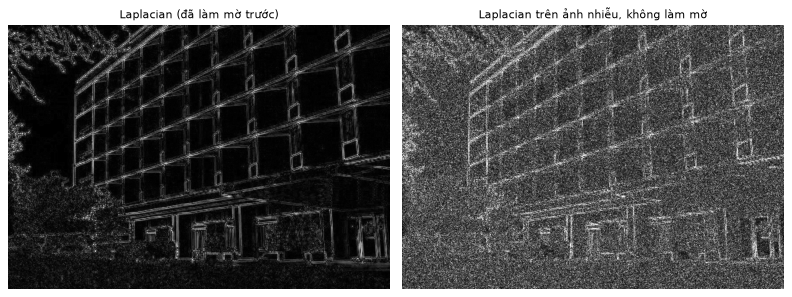

Đo độ nét bằng phương sai Laplacian:
  Blur  1x1 : var(Laplacian) =    274.1
  Blur  5x5 : var(Laplacian) =     63.7
  Blur 11x11: var(Laplacian) =     14.3
  Blur 21x21: var(Laplacian) =      4.0


In [53]:
lap = cv2.Laplacian(bblur, cv2.CV_64F, ksize=3)
lap_noblur = cv2.Laplacian(add_gaussian_noise(bgray, 10), cv2.CV_64F, ksize=3)
show([cv2.convertScaleAbs(lap), cv2.convertScaleAbs(lap_noblur)],
     ['Laplacian (đã làm mờ trước)', 'Laplacian trên ảnh nhiễu, không làm mờ'], size=5)

print('Đo độ nét bằng phương sai Laplacian:')
for k in [1, 5, 11, 21]:
    im = bgray if k == 1 else cv2.GaussianBlur(bgray, (k, k), 0)
    print(f'  Blur {k:2d}x{k:<2d}: var(Laplacian) = {cv2.Laplacian(im, cv2.CV_64F).var():8.1f}')

### 13.4. Canny — bộ phát hiện cạnh tốt nhất (cổ điển)

`cv2.Canny(img, threshold1, threshold2)` thực hiện 4 bước:

1. **Làm mờ Gauss 5×5** để giảm nhiễu.
2. **Tính gradient** (Sobel) — độ lớn và hướng.
3. **Non-Maximum Suppression**: chỉ giữ pixel là cực đại theo hướng gradient ⇒ cạnh **mỏng 1 pixel**.
4. **Hysteresis thresholding** (ngưỡng kép):
   - Gradient > `threshold2` (cao) → **cạnh chắc chắn**.
   - Gradient < `threshold1` (thấp) → loại.
   - Ở giữa → chỉ giữ nếu **nối liền** với cạnh chắc chắn.

Tỉ lệ khuyên dùng: `threshold2 ≈ 2–3 × threshold1`.

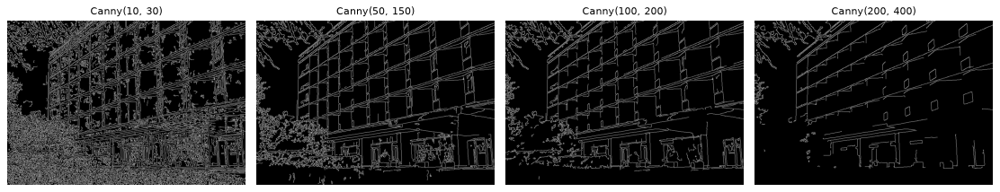

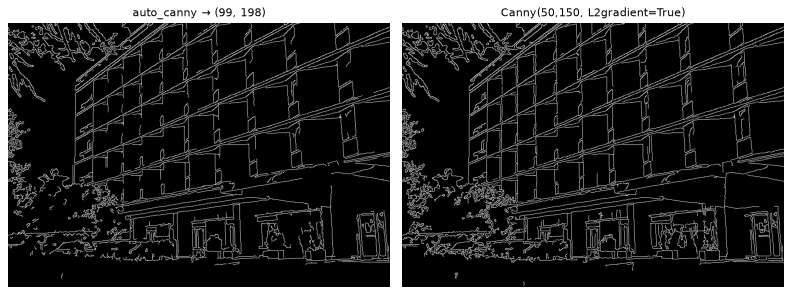

In [54]:
pairs = [(10, 30), (50, 150), (100, 200), (200, 400)]
show([cv2.Canny(bblur, a, b) for a, b in pairs], [f'Canny({a}, {b})' for a, b in pairs], cols=4, size=3.5)


def auto_canny(gray_img, sigma=0.33):
    """Chọn ngưỡng tự động dựa trên trung vị độ sáng."""
    v = np.median(gray_img)
    lower = int(max(0, (1.0 - sigma) * v))
    upper = int(min(255, (1.0 + sigma) * v))
    return cv2.Canny(gray_img, lower, upper), lower, upper


edges_auto, lo, hi = auto_canny(bblur)
edges_l2 = cv2.Canny(bblur, 50, 150, L2gradient=True)   # dùng sqrt(gx²+gy²) thay vì |gx|+|gy|
show([edges_auto, edges_l2], [f'auto_canny → ({lo}, {hi})', 'Canny(50,150, L2gradient=True)'], size=5)

🔍 **Nhận xét:** Ngưỡng thấp → nhiều cạnh vụn (kết cấu, nhiễu); ngưỡng cao → chỉ còn đường viền chính nhưng có thể đứt đoạn. So với Sobel, Canny cho cạnh **mảnh, liên tục, nhị phân** — rất phù hợp làm đầu vào cho contour và Hough.

✍️ **Bài tập 13:** Viết hàm nhận ảnh và trả về "ảnh phác thảo bút chì" bằng cách: xám → đảo màu → GaussianBlur → `cv2.divide(gray, 255 - blur, scale=256)`.

---
## 14. Hình thái học (Morphological Operations)

Các phép toán trên **ảnh nhị phân** (cũng dùng được cho ảnh xám) dựa trên một **phần tử cấu trúc (structuring element / kernel)**:

| Phép | Định nghĩa | Tác dụng |
|---|---|---|
| **Erosion** (co) | pixel = MIN trong kernel | đối tượng trắng **co lại**, xóa chấm trắng nhỏ, tách đối tượng dính nhau |
| **Dilation** (giãn) | pixel = MAX trong kernel | đối tượng trắng **phình ra**, lấp lỗ nhỏ, nối nét đứt |
| **Opening** | erode → dilate | **xóa nhiễu trắng** nhỏ bên ngoài, giữ kích thước đối tượng |
| **Closing** | dilate → erode | **lấp lỗ đen** nhỏ bên trong đối tượng |
| **Gradient** | dilate − erode | **đường viền** đối tượng |
| **Top-hat** | img − opening | chi tiết **sáng nhỏ** hơn kernel |
| **Black-hat** | closing − img | chi tiết **tối nhỏ** hơn kernel |

In [55]:
for name, shape in [('MORPH_RECT', cv2.MORPH_RECT), ('MORPH_ELLIPSE', cv2.MORPH_ELLIPSE), ('MORPH_CROSS', cv2.MORPH_CROSS)]:
    print(f'{name}:\n{cv2.getStructuringElement(shape, (5, 5))}\n')

MORPH_RECT:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

MORPH_ELLIPSE:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]

MORPH_CROSS:
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]



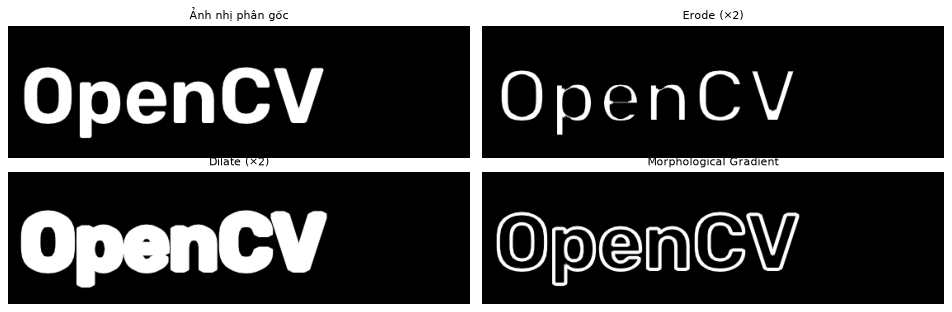

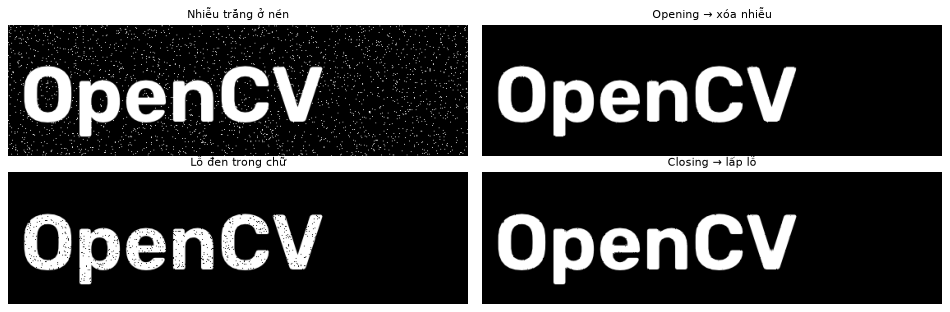

In [56]:
rng = np.random.default_rng(7)
bw = np.zeros((160, 560), np.uint8)
cv2.putText(bw, 'OpenCV', (15, 118), cv2.FONT_HERSHEY_SIMPLEX, 3.3, 255, 16)
noise = rng.random(bw.shape)
salt = bw.copy();   salt[noise < 0.03] = 255          # chấm trắng ngoài nền
holes = bw.copy();  holes[noise > 0.95] = 0           # lỗ đen trong chữ

k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
show([bw, cv2.erode(bw, k, iterations=2), cv2.dilate(bw, k, iterations=2), cv2.morphologyEx(bw, cv2.MORPH_GRADIENT, k)],
     ['Ảnh nhị phân gốc', 'Erode (×2)', 'Dilate (×2)', 'Morphological Gradient'], cols=2, size=6)
show([salt, cv2.morphologyEx(salt, cv2.MORPH_OPEN, k), holes, cv2.morphologyEx(holes, cv2.MORPH_CLOSE, k)],
     ['Nhiễu trắng ở nền', 'Opening → xóa nhiễu', 'Lỗ đen trong chữ', 'Closing → lấp lỗ'], cols=2, size=6)

🔍 **Nhận xét:** Opening = "erode để xóa các chấm nhỏ hơn kernel, rồi dilate để trả lại kích thước cũ cho chữ". Closing ngược lại. Chọn **kích thước kernel lớn hơn nhiễu nhưng nhỏ hơn chi tiết cần giữ**.

### 14.1. Làm sạch mask màu (tiếp nối mục 4.3)

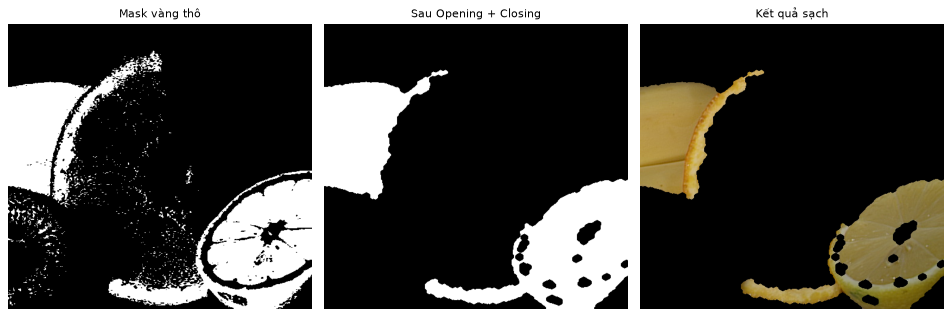

In [57]:
mask_y = cv2.inRange(cv2.cvtColor(img, cv2.COLOR_BGR2HSV), np.array((20, 100, 100)), np.array((35, 255, 255)))
k7 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
clean_mask = cv2.morphologyEx(mask_y, cv2.MORPH_OPEN, k7)
clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, k7, iterations=2)
show([mask_y, clean_mask, cv2.bitwise_and(img, img, mask=clean_mask)],
     ['Mask vàng thô', 'Sau Opening + Closing', 'Kết quả sạch'])

### 14.2. Top-hat / Black-hat: tách chữ khỏi nền chiếu sáng không đều

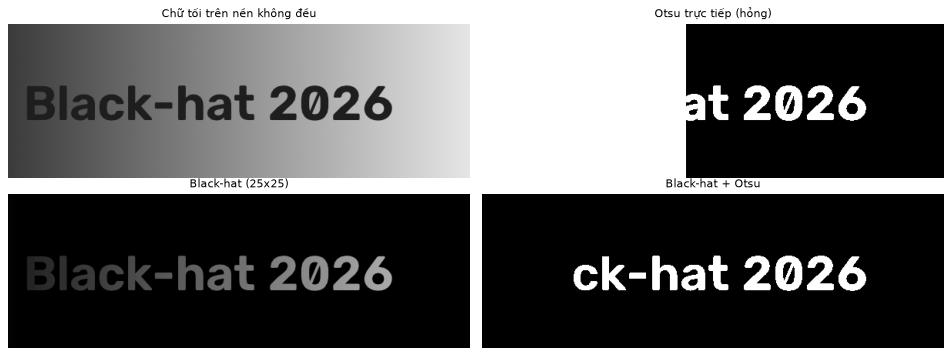

In [58]:
h, w = 200, 600
bg_light = np.tile(np.linspace(60, 230, w), (h, 1)).astype(np.uint8)          # nền sáng dần
text_img = bg_light.copy()
cv2.putText(text_img, 'Black-hat 2026', (20, 125), cv2.FONT_HERSHEY_SIMPLEX, 2.2, 30, 6)
kbig = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 25))
blackhat = cv2.morphologyEx(text_img, cv2.MORPH_BLACKHAT, kbig)
_, bin_direct = cv2.threshold(text_img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
_, bin_bh = cv2.threshold(blackhat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
show([text_img, bin_direct, blackhat, bin_bh],
     ['Chữ tối trên nền không đều', 'Otsu trực tiếp (hỏng)', 'Black-hat (25x25)', 'Black-hat + Otsu'], cols=2, size=6)

### 14.3. Tách đường kẻ ngang / dọc (bảng biểu, sudoku)

Dùng kernel **dài và mảnh**: opening với kernel `(W/15, 1)` chỉ giữ lại các đoạn **nằm ngang dài**; kernel `(1, H/15)` giữ đoạn **dọc**.

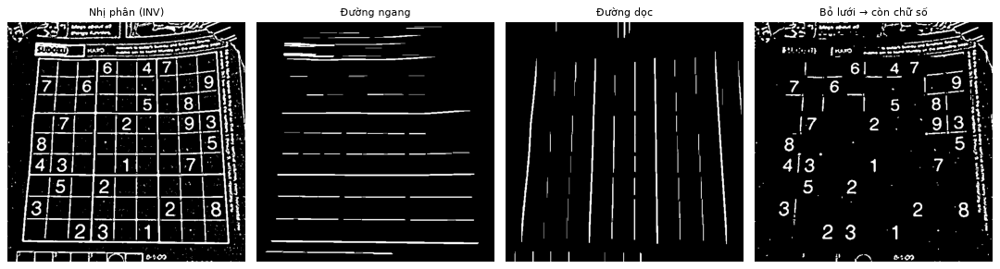

In [59]:
sud_bin = cv2.adaptiveThreshold(sud_blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 11, 2)
H_, W_ = sud_bin.shape
horiz = cv2.morphologyEx(sud_bin, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (W_ // 15, 1)))
vert = cv2.morphologyEx(sud_bin, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (1, H_ // 15)))
grid = cv2.bitwise_or(horiz, vert)
digits = cv2.morphologyEx(cv2.subtract(sud_bin, cv2.dilate(grid, np.ones((3, 3), np.uint8))), cv2.MORPH_OPEN,
                          np.ones((2, 2), np.uint8))
show([sud_bin, horiz, vert, digits], ['Nhị phân (INV)', 'Đường ngang', 'Đường dọc', 'Bỏ lưới → còn chữ số'],
     cols=4, size=3.4)

### 14.4. Skeleton (xương) bằng các phép hình thái

Lặp: `skeleton |= img − open(img)`, `img = erode(img)` cho tới khi img rỗng.

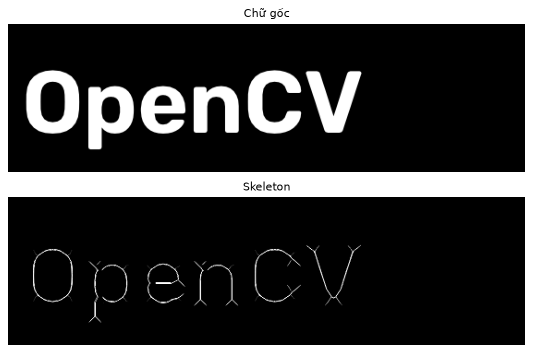

In [60]:
def skeletonize(bin_img):
    skel = np.zeros_like(bin_img)
    work = bin_img.copy()
    el = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
    while cv2.countNonZero(work) > 0:
        opened = cv2.morphologyEx(work, cv2.MORPH_OPEN, el)
        skel = cv2.bitwise_or(skel, cv2.subtract(work, opened))
        work = cv2.erode(work, el)
    return skel


show([bw, skeletonize(bw)], ['Chữ gốc', 'Skeleton'], cols=1, size=7)

---
## 15. Contour và phân tích hình dạng

**Contour** = đường cong nối các điểm liên tục **dọc theo biên** của một vùng cùng màu/cường độ. Là công cụ quan trọng nhất để **đếm, đo, nhận dạng hình dạng** đối tượng.

```python
contours, hierarchy = cv2.findContours(binary, mode, method)
```
- `binary`: ảnh **nhị phân**, **đối tượng màu TRẮNG trên nền ĐEN**.
- `mode`: `RETR_EXTERNAL` (chỉ viền ngoài cùng), `RETR_LIST` (tất cả, không phân cấp), `RETR_TREE` (tất cả + cây phân cấp cha/con), `RETR_CCOMP` (2 cấp).
- `method`: `CHAIN_APPROX_NONE` (giữ mọi điểm), `CHAIN_APPROX_SIMPLE` (nén đoạn thẳng còn 2 đầu mút — tiết kiệm bộ nhớ).
- Mỗi contour là mảng `shape = (N, 1, 2)` chứa các điểm `(x, y)`.

> 📝 OpenCV 3.x trả về 3 giá trị `(image, contours, hierarchy)`; từ OpenCV 4 trở đi chỉ 2 giá trị.

Số contour tìm được: 8
Tổng số điểm  CHAIN_APPROX_NONE  : 3103
Tổng số điểm  CHAIN_APPROX_SIMPLE: 1194
Contour đầu tiên shape = (176, 1, 2)


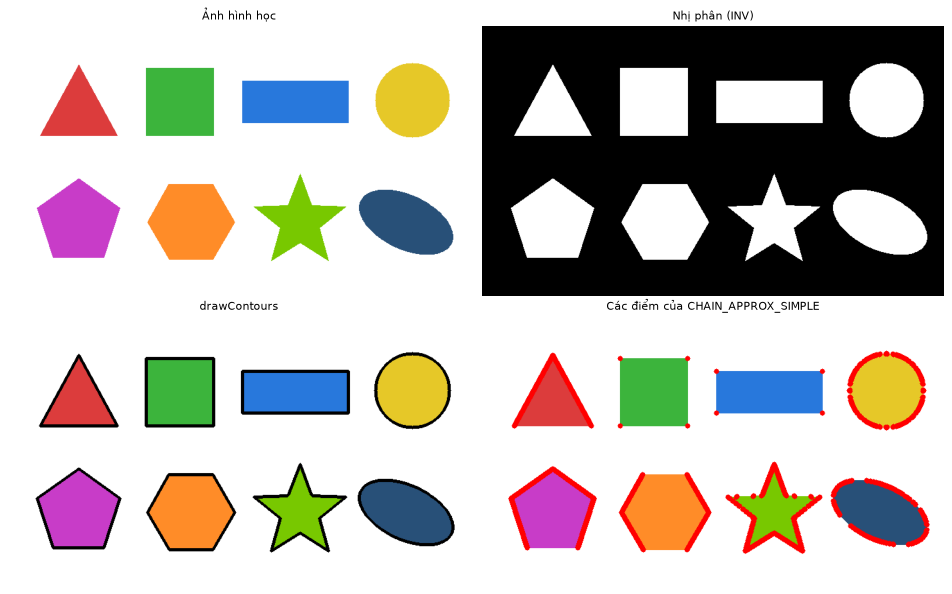

In [61]:
def regular_polygon(cx, cy, r, n, rot=-np.pi / 2):
    a = rot + np.arange(n) * 2 * np.pi / n
    return np.stack([cx + r * np.cos(a), cy + r * np.sin(a)], 1).astype(np.int32)


def star_points(cx, cy, r_out, r_in, n=5):
    pts = []
    for i in range(2 * n):
        r = r_out if i % 2 == 0 else r_in
        a = -np.pi / 2 + i * np.pi / n
        pts.append((cx + r * np.cos(a), cy + r * np.sin(a)))
    return np.array(pts, np.int32)


shapes = np.full((420, 720, 3), 255, np.uint8)
cv2.fillPoly(shapes, [np.array([[50, 170], [170, 170], [110, 60]], np.int32)], (60, 60, 220))    # tam giác
cv2.rectangle(shapes, (215, 65), (320, 170), (60, 180, 60), -1)                                   # vuông
cv2.rectangle(shapes, (365, 85), (530, 150), (220, 120, 40), -1)                                  # chữ nhật
cv2.circle(shapes, (630, 115), 58, (40, 200, 230), -1)                                            # tròn
cv2.fillPoly(shapes, [regular_polygon(110, 305, 68, 5)], (200, 60, 200))                          # ngũ giác
cv2.fillPoly(shapes, [regular_polygon(285, 305, 68, 6, 0)], (40, 140, 255))                       # lục giác
cv2.fillPoly(shapes, [star_points(455, 305, 75, 32)], (0, 200, 120))                              # ngôi sao
cv2.ellipse(shapes, (620, 305), (78, 42), 25, 0, 360, (120, 80, 40), -1)                          # elip

sgray = cv2.cvtColor(shapes, cv2.COLOR_BGR2GRAY)
_, sbin = cv2.threshold(sgray, 240, 255, cv2.THRESH_BINARY_INV)      # đối tượng trắng, nền đen
contours, hierarchy = cv2.findContours(sbin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours_none, _ = cv2.findContours(sbin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
print('Số contour tìm được:', len(contours))
print('Tổng số điểm  CHAIN_APPROX_NONE  :', sum(len(c) for c in contours_none))
print('Tổng số điểm  CHAIN_APPROX_SIMPLE:', sum(len(c) for c in contours))
print('Contour đầu tiên shape =', contours[0].shape)

drawn = shapes.copy()
cv2.drawContours(drawn, contours, -1, (0, 0, 0), 3)                  # -1 = vẽ tất cả
pts_vis = shapes.copy()
for cnt in contours:
    for p in cnt[:, 0]:
        cv2.circle(pts_vis, tuple(int(v) for v in p), 4, (0, 0, 255), -1)
show([shapes, sbin, drawn, pts_vis], ['Ảnh hình học', 'Nhị phân (INV)', 'drawContours', 'Các điểm của CHAIN_APPROX_SIMPLE'],
     cols=2, size=6)

### 15.1. Các đặc trưng của contour

| Đặc trưng | Hàm / công thức |
|---|---|
| Diện tích | `cv2.contourArea(c)` |
| Chu vi | `cv2.arcLength(c, closed=True)` |
| Tâm (centroid) | `M = cv2.moments(c)`; `cx = M['m10']/M['m00']`, `cy = M['m01']/M['m00']` |
| Hộp bao thẳng | `x, y, w, h = cv2.boundingRect(c)` |
| Hộp bao xoay nhỏ nhất | `rect = cv2.minAreaRect(c)`; `box = cv2.boxPoints(rect)` |
| Đường tròn bao nhỏ nhất | `(x, y), r = cv2.minEnclosingCircle(c)` |
| Elip khớp nhất | `cv2.fitEllipse(c)` (cần ≥ 5 điểm) |
| Bao lồi | `hull = cv2.convexHull(c)` |
| Xấp xỉ đa giác | `cv2.approxPolyDP(c, epsilon, True)` (thuật toán Douglas–Peucker) |
| Aspect ratio | `w / h` |
| Extent | `area / (w*h)` |
| Solidity (độ đặc) | `area / area(hull)` |
| Độ tròn (circularity) | $4\pi \cdot area / perimeter^2$ (=1 với hình tròn) |

 # |    area |   peri |    centroid |   w/h | extent | solidity |  circ
 0 |    6600 |  389.7 | (110,133)   |  1.09 |   0.49 |     0.99 |  0.55
 1 |   11025 |  420.0 | (267,117)   |  1.00 |   0.98 |     1.00 |  0.79
 2 |   10725 |  460.0 | (447,117)   |  2.52 |   0.98 |     1.00 |  0.64
 3 |   10392 |  384.3 | (630,115)   |  1.00 |   0.76 |     0.99 |  0.88
 4 |   10976 |  420.8 | (109,304)   |  1.05 |   0.68 |     0.99 |  0.78
 5 |   11964 |  426.9 | (284,304)   |  1.16 |   0.74 |     0.99 |  0.82
 6 |    7032 |  554.9 | (454,304)   |  1.06 |   0.36 |     0.53 |  0.29
 7 |   10296 |  407.1 | (620,305)   |  1.46 |   0.69 |     0.99 |  0.78


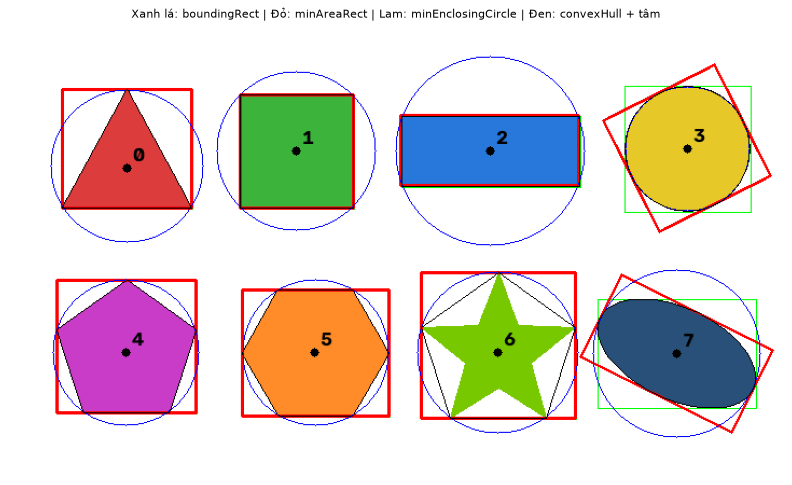

In [62]:
geo = shapes.copy()
print(f'{"#":>2} | {"area":>7} | {"peri":>6} | {"centroid":>11} | {"w/h":>5} | {"extent":>6} | {"solidity":>8} | {"circ":>5}')
for i, cnt in enumerate(sorted(contours, key=lambda c: cv2.boundingRect(c)[0] + 1000 * (cv2.boundingRect(c)[1] > 200))):
    area = cv2.contourArea(cnt)
    peri = cv2.arcLength(cnt, True)
    M = cv2.moments(cnt)
    cx, cy = int(M['m10'] / M['m00']), int(M['m01'] / M['m00'])
    x, y, w, h = cv2.boundingRect(cnt)
    hull = cv2.convexHull(cnt)
    solidity = area / cv2.contourArea(hull)
    circ = 4 * np.pi * area / peri ** 2
    print(f'{i:2d} | {area:7.0f} | {peri:6.1f} | ({cx:3d},{cy:3d})   | {w/h:5.2f} | {area/(w*h):6.2f} | {solidity:8.2f} | {circ:5.2f}')

    cv2.rectangle(geo, (x, y), (x + w, y + h), (0, 255, 0), 1)                           # bbox thẳng: xanh lá
    box = cv2.boxPoints(cv2.minAreaRect(cnt)).astype(np.int32)
    cv2.drawContours(geo, [box], 0, (0, 0, 255), 2)                                      # bbox xoay: đỏ
    (ex, ey), r = cv2.minEnclosingCircle(cnt)
    cv2.circle(geo, (int(ex), int(ey)), int(r), (255, 0, 0), 1)                          # đường tròn bao: lam
    cv2.drawContours(geo, [hull], 0, (0, 0, 0), 1)                                       # bao lồi: đen
    cv2.circle(geo, (cx, cy), 4, (0, 0, 0), -1)
    cv2.putText(geo, str(i), (cx + 6, cy - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)
show(geo, 'Xanh lá: boundingRect | Đỏ: minAreaRect | Lam: minEnclosingCircle | Đen: convexHull + tâm', size=10)

### 15.2. Nhận dạng hình dạng bằng `approxPolyDP`

`approxPolyDP(c, ε, True)` đơn giản hóa contour thành đa giác ít đỉnh hơn, sao cho khoảng cách lệch ≤ ε. Thường chọn **ε = 1–4% chu vi**. Sau đó đếm số đỉnh:
- 3 → tam giác; 4 → vuông/chữ nhật (xét tỉ lệ w/h); 5 → ngũ giác; 6 → lục giác.
- Lõm (solidity thấp) → ngôi sao.
- Nhiều đỉnh → tròn hoặc elip (xét tỉ lệ 2 trục của `fitEllipse`).

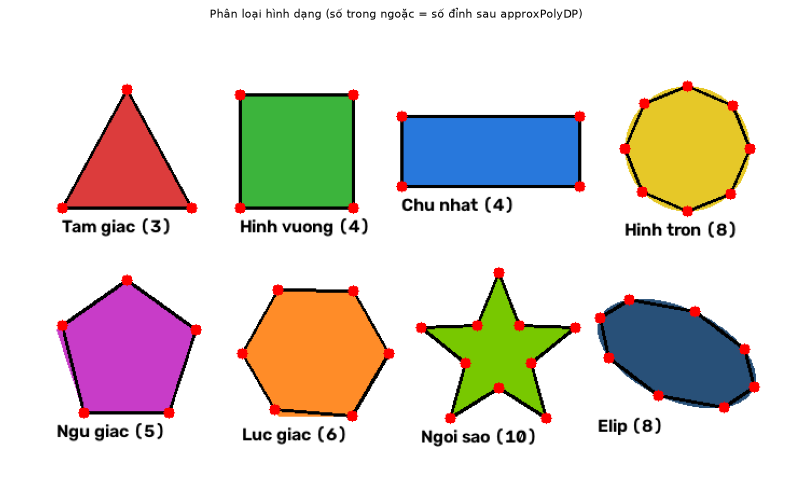

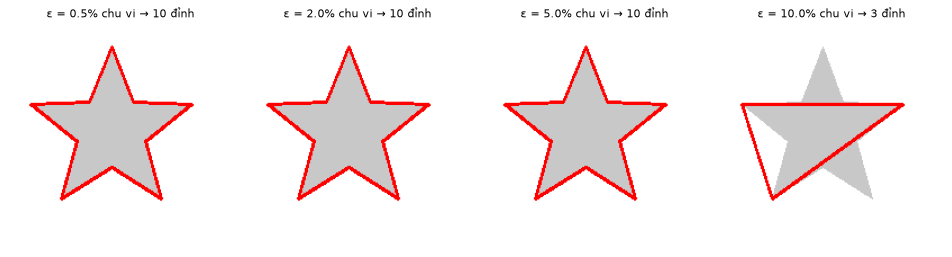

In [63]:
def classify_shape(cnt):
    peri = cv2.arcLength(cnt, True)
    approx = cv2.approxPolyDP(cnt, 0.02 * peri, True)
    v = len(approx)
    area = cv2.contourArea(cnt)
    solidity = area / cv2.contourArea(cv2.convexHull(cnt))
    if solidity < 0.8:
        return 'Ngoi sao', approx
    if v == 3:
        return 'Tam giac', approx
    if v == 4:
        (_, _), (rw, rh), _ = cv2.minAreaRect(cnt)
        return ('Hinh vuong' if 0.92 <= rw / rh <= 1.08 else 'Chu nhat'), approx
    if v == 5:
        return 'Ngu giac', approx
    if v == 6:
        return 'Luc giac', approx
    (_, _), (ma, MA), _ = cv2.fitEllipse(cnt)
    return ('Hinh tron' if min(ma, MA) / max(ma, MA) > 0.9 else 'Elip'), approx


labeled = shapes.copy()
for cnt in contours:
    name, approx = classify_shape(cnt)
    cv2.drawContours(labeled, [approx], -1, (0, 0, 0), 2)
    for p in approx[:, 0]:
        cv2.circle(labeled, tuple(int(v) for v in p), 5, (0, 0, 255), -1)
    x, y, w, h = cv2.boundingRect(cnt)
    cv2.putText(labeled, f'{name} ({len(approx)})', (x, y + h + 22), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 2)
show(labeled, 'Phân loại hình dạng (số trong ngoặc = số đỉnh sau approxPolyDP)', size=10)

# Ảnh hưởng của epsilon
star = min(contours, key=lambda c: cv2.contourArea(c) / cv2.contourArea(cv2.convexHull(c)))  # solidity nhỏ nhất
outs, titles = [], []
for eps in [0.005, 0.02, 0.05, 0.1]:
    canvas = np.full((200, 200, 3), 255, np.uint8)
    off = star - star.reshape(-1, 2).min(0) + 20
    ap = cv2.approxPolyDP(off, eps * cv2.arcLength(off, True), True)
    cv2.drawContours(canvas, [off], -1, (200, 200, 200), -1)
    cv2.drawContours(canvas, [ap], -1, (0, 0, 255), 2)
    outs.append(canvas); titles.append(f'ε = {eps*100:.1f}% chu vi → {len(ap)} đỉnh')
show(outs, titles, cols=4, size=3)

### 15.3. Phân cấp contour (hierarchy) — `RETR_TREE`

`hierarchy[0][i] = [next, previous, first_child, parent]` (−1 nếu không có). Dùng để phân biệt **lỗ bên trong** đối tượng, **đối tượng lồng nhau**.

RETR_EXTERNAL : 2 contour
RETR_LIST     : 5 contour
RETR_CCOMP    : 5 contour
RETR_TREE     : 5 contour

Hierarchy RETR_TREE [next, prev, first_child, parent]:
 [[ 1 -1 -1 -1]
 [-1  0  2 -1]
 [-1 -1  3  1]
 [-1 -1  4  2]
 [-1 -1 -1  3]]


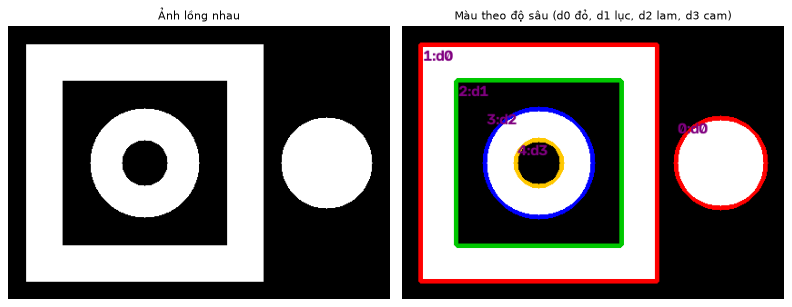

In [64]:
nest = np.zeros((300, 420), np.uint8)
cv2.rectangle(nest, (20, 20), (280, 280), 255, -1)    # cấp 0
cv2.rectangle(nest, (60, 60), (240, 240), 0, -1)      # lỗ (cấp 1)
cv2.circle(nest, (150, 150), 60, 255, -1)             # đảo trong lỗ (cấp 2)
cv2.circle(nest, (150, 150), 25, 0, -1)               # lỗ trong đảo (cấp 3)
cv2.circle(nest, (350, 150), 50, 255, -1)             # một đối tượng riêng

for mode in ['RETR_EXTERNAL', 'RETR_LIST', 'RETR_CCOMP', 'RETR_TREE']:
    cs, hi = cv2.findContours(nest, getattr(cv2, mode), cv2.CHAIN_APPROX_SIMPLE)
    print(f'{mode:14s}: {len(cs)} contour')

cs, hi = cv2.findContours(nest, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
print('\nHierarchy RETR_TREE [next, prev, first_child, parent]:\n', hi[0])


def depth(i):
    d = 0
    while hi[0][i][3] != -1:
        i = hi[0][i][3]; d += 1
    return d


vis = cv2.cvtColor(nest, cv2.COLOR_GRAY2BGR)
palette = [(0, 0, 255), (0, 200, 0), (255, 0, 0), (0, 200, 255)]
for i, c in enumerate(cs):
    cv2.drawContours(vis, cs, i, palette[depth(i) % 4], 4)
    x, y, w, h = cv2.boundingRect(c)
    cv2.putText(vis, f'{i}:d{depth(i)}', (x + 3, y + 18), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (128, 0, 128), 2)
show([nest, vis], ['Ảnh lồng nhau', 'Màu theo độ sâu (d0 đỏ, d1 lục, d2 lam, d3 cam)'], size=5)

### 15.4. So khớp hình dạng — `cv2.matchShapes` (Hu Moments)

7 **Hu moments** bất biến với tịnh tiến, co giãn, xoay (và lật). `cv2.matchShapes` so sánh 2 contour dựa trên chúng: **càng gần 0 càng giống**.

Hu moments của ngôi sao mẫu: [0.20315 0.      0.      0.     ] ...


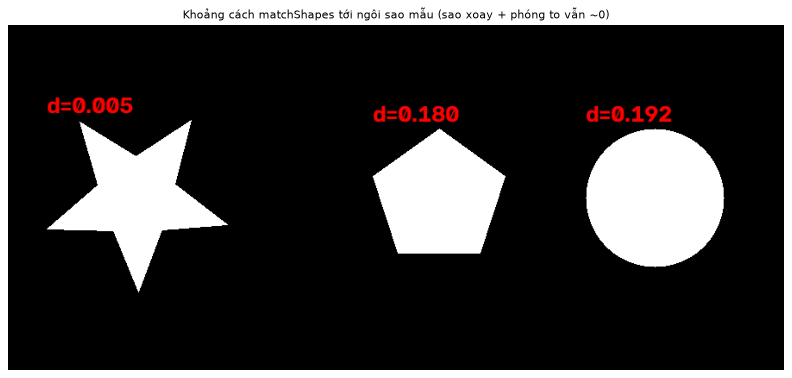

In [65]:
ref = star
big_star = star_points(150, 200, 110, 47).reshape(-1, 1, 2).astype(np.float32)   # sao to hơn
M_rot = cv2.getRotationMatrix2D((150, 200), 37, 1.0)                             # và xoay 37°
big_star = cv2.transform(big_star, M_rot).astype(np.int32)
canvas = np.zeros((400, 900), np.uint8)
cv2.fillPoly(canvas, [big_star], 255)
cv2.fillPoly(canvas, [regular_polygon(500, 200, 80, 5)], 255)
cv2.circle(canvas, (750, 200), 80, 255, -1)
cs2, _ = cv2.findContours(canvas, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
vis = cv2.cvtColor(canvas, cv2.COLOR_GRAY2BGR)
for c in cs2:
    d = cv2.matchShapes(ref, c, cv2.CONTOURS_MATCH_I1, 0)
    x, y, w, h = cv2.boundingRect(c)
    cv2.putText(vis, f'd={d:.3f}', (x, max(y - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 2)
print('Hu moments của ngôi sao mẫu:', cv2.HuMoments(cv2.moments(ref)).ravel()[:4].round(5), '...')
show(vis, 'Khoảng cách matchShapes tới ngôi sao mẫu (sao xoay + phóng to vẫn ~0)', size=10)

### 15.5. Convexity defects — các "chỗ lõm"

`cv2.convexityDefects(cnt, hull_indices)` trả về các điểm lõm sâu nhất giữa contour và bao lồi — ứng dụng nổi tiếng: **đếm ngón tay**.

Điểm lõm (474, 279), độ sâu = 28.7 px
Điểm lõm (435, 279), độ sâu = 28.4 px
Điểm lõm (424, 314), độ sâu = 28.9 px
Điểm lõm (455, 337), độ sâu = 28.0 px
Điểm lõm (485, 314), độ sâu = 28.9 px


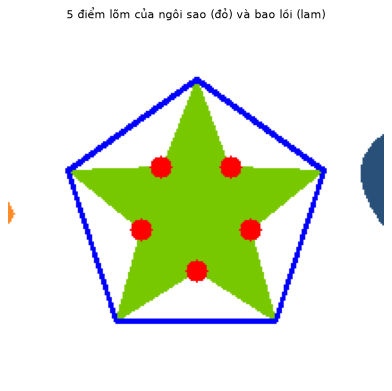

In [66]:
hull_idx = cv2.convexHull(star, returnPoints=False)
defects = cv2.convexityDefects(star, hull_idx)
vis = shapes.copy()
cv2.drawContours(vis, [cv2.convexHull(star)], 0, (255, 0, 0), 2)
for s, e, f, d in defects.reshape(-1, 4):
    far = tuple(int(v) for v in star.reshape(-1, 2)[f])
    cv2.circle(vis, far, 6, (0, 0, 255), -1)
    print(f'Điểm lõm {far}, độ sâu = {d / 256:.1f} px')
show(vis[200:400, 350:560], f'{len(defects.reshape(-1, 4))} điểm lõm của ngôi sao (đỏ) và bao lồi (lam)', size=5)

---
## 16. Connected Components — gán nhãn vùng liên thông

`cv2.connectedComponentsWithStats(binary, connectivity=8)` gán **một nhãn (số nguyên) cho mỗi vùng trắng liên thông** và trả về luôn thống kê:

- `num_labels`: số nhãn (**bao gồm nền = nhãn 0**).
- `labels`: ảnh nhãn cùng kích thước.
- `stats[i] = [x, y, w, h, area]`.
- `centroids[i] = [cx, cy]`.

So với contour: nhanh hơn, cho diện tích chính xác theo pixel; nhưng không có thông tin hình dạng biên.

Số vùng (không tính nền): 258
Sau khi lọc area >= 30: còn 14 vùng


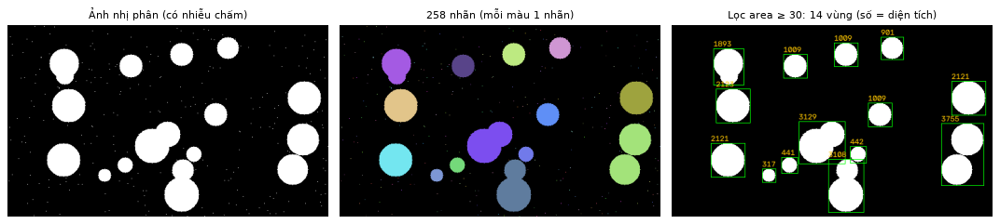

In [67]:
rng = np.random.default_rng(11)
blobs = np.zeros((300, 500), np.uint8)
for _ in range(18):
    cv2.circle(blobs, (int(rng.integers(30, 470)), int(rng.integers(30, 270))), int(rng.integers(8, 28)), 255, -1)
blobs[rng.random(blobs.shape) < 0.002] = 255        # nhiễu chấm nhỏ

num, labels, stats, cents = cv2.connectedComponentsWithStats(blobs, connectivity=8)
print('Số vùng (không tính nền):', num - 1)

# Tô màu ngẫu nhiên cho mỗi nhãn
colors = rng.integers(50, 255, (num, 3), dtype=np.uint8); colors[0] = 0
colored = colors[labels]

# Lọc bỏ vùng nhỏ (nhiễu)
min_area = 30
keep = [i for i in range(1, num) if stats[i, cv2.CC_STAT_AREA] >= min_area]
filtered = np.isin(labels, keep).astype(np.uint8) * 255
vis = cv2.cvtColor(filtered, cv2.COLOR_GRAY2BGR)
for i in keep:
    x, y, w, h, a = stats[i]
    cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 1)
    cv2.putText(vis, str(a), (x, y - 3), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 200, 255), 1)
print(f'Sau khi lọc area >= {min_area}: còn {len(keep)} vùng')
show([blobs, colored, vis], ['Ảnh nhị phân (có nhiễu chấm)', f'{num-1} nhãn (mỗi màu 1 nhãn)',
                             f'Lọc area ≥ {min_area}: {len(keep)} vùng (số = diện tích)'], size=4.5)

🔍 **Nhận xét:** Các hình tròn **chạm nhau** bị tính là **một** vùng. Để tách chúng ta cần **Watershed** (mục 22.2) hoặc erosion trước khi đếm.

---
## 17. Biến đổi Hough — tìm đường thẳng và đường tròn

### 17.1. Ý tưởng

Một đường thẳng được biểu diễn bằng $(\rho, \theta)$: $\rho = x\cos\theta + y\sin\theta$.
- Mỗi **điểm cạnh** $(x, y)$ "bỏ phiếu" cho **tất cả** các đường $(\rho, \theta)$ có thể đi qua nó (một đường sin trong không gian tham số).
- Các ô trong ma trận tích lũy (accumulator) được **nhiều phiếu** ⇒ là đường thẳng thật.

| Hàm | Kết quả |
|---|---|
| `cv2.HoughLines(edges, ρ_res, θ_res, threshold)` | các đường vô hạn `(ρ, θ)` |
| `cv2.HoughLinesP(edges, ρ_res, θ_res, threshold, minLineLength, maxLineGap)` | các **đoạn thẳng** `(x1,y1,x2,y2)` — thường hữu ích hơn |
| `cv2.HoughCircles(gray, HOUGH_GRADIENT, dp, minDist, param1, param2, minRadius, maxRadius)` | các đường tròn `(x, y, r)` |

HoughLines tìm được 14 đường
HoughLinesP tìm được 36 đoạn thẳng


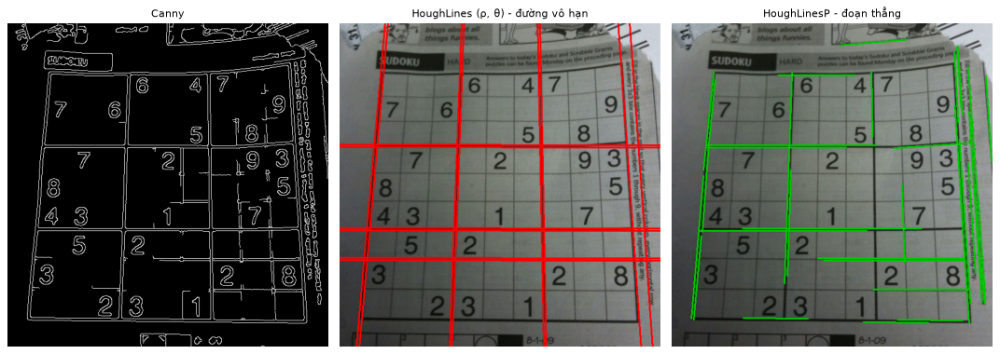

In [68]:
sud_edges = cv2.Canny(sud_blur, 50, 150, apertureSize=3)

# HoughLines chuẩn
lines = cv2.HoughLines(sud_edges, 1, np.pi / 180, 200)
vis_std = sudoku.copy()
print('HoughLines tìm được', 0 if lines is None else len(lines), 'đường')
if lines is not None:
    for rho, theta in lines.reshape(-1, 2):
        a, b = np.cos(theta), np.sin(theta)
        x0, y0 = a * rho, b * rho
        p1 = (int(x0 + 1000 * (-b)), int(y0 + 1000 * a))
        p2 = (int(x0 - 1000 * (-b)), int(y0 - 1000 * a))
        cv2.line(vis_std, p1, p2, (0, 0, 255), 2)

# HoughLinesP xác suất
segs = cv2.HoughLinesP(sud_edges, 1, np.pi / 180, threshold=80, minLineLength=100, maxLineGap=10)
vis_p = sudoku.copy()
print('HoughLinesP tìm được', 0 if segs is None else len(segs), 'đoạn thẳng')
if segs is not None:
    for x1, y1, x2, y2 in segs.reshape(-1, 4):
        cv2.line(vis_p, (x1, y1), (x2, y2), (0, 200, 0), 2)
show([sud_edges, vis_std, vis_p], ['Canny', 'HoughLines (ρ, θ) - đường vô hạn', 'HoughLinesP - đoạn thẳng'], size=4.5)

Tổng 145 đoạn; 36 đoạn dọc, 45 đoạn ngang


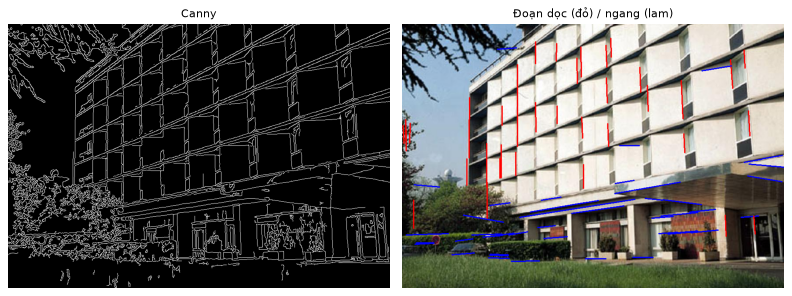

In [69]:
# Hough Lines trên ảnh tòa nhà: lọc theo góc -> chỉ giữ đường gần thẳng đứng / nằm ngang
bedges = cv2.Canny(bblur, 50, 150)
segs = cv2.HoughLinesP(bedges, 1, np.pi / 180, threshold=60, minLineLength=40, maxLineGap=5)
vis = building.copy()
n_v = n_h = 0
for x1, y1, x2, y2 in segs.reshape(-1, 4):
    ang = abs(np.degrees(np.arctan2(y2 - y1, x2 - x1)))
    if ang > 80 and ang < 100:
        cv2.line(vis, (x1, y1), (x2, y2), (0, 0, 255), 2); n_v += 1     # dọc: đỏ
    elif ang < 10 or ang > 170:
        cv2.line(vis, (x1, y1), (x2, y2), (255, 0, 0), 2); n_h += 1     # ngang: lam
print(f'Tổng {len(segs)} đoạn; {n_v} đoạn dọc, {n_h} đoạn ngang')
show([bedges, vis], ['Canny', 'Đoạn dọc (đỏ) / ngang (lam)'], size=5)

### 17.2. HoughCircles — đếm đồng xu, viên kẹo, bánh xe…

Tham số quan trọng:
- `dp`: tỉ lệ nghịch độ phân giải accumulator (1 = bằng ảnh).
- `minDist`: khoảng cách tối thiểu giữa 2 tâm (tránh phát hiện trùng).
- `param1`: ngưỡng cao của Canny bên trong.
- `param2`: ngưỡng tích lũy cho tâm — **nhỏ → nhiều vòng tròn (cả giả)**, lớn → ít hơn.
- `minRadius`, `maxRadius`: giới hạn bán kính.

Luôn **làm mờ** (median) trước để giảm vòng tròn giả.

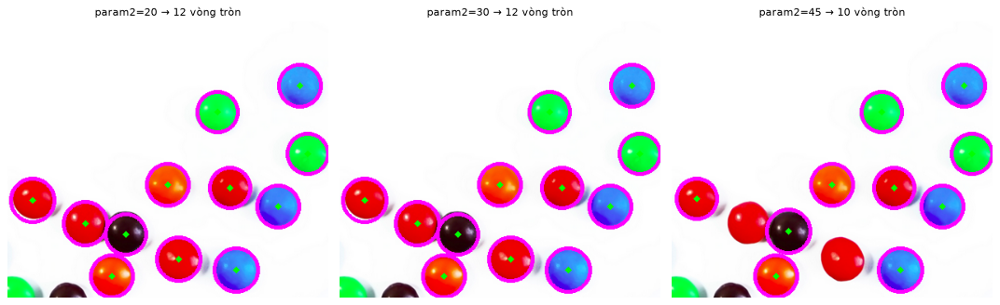

In [70]:
smarties = load_sample('smarties.png')
sm_gray = cv2.medianBlur(cv2.cvtColor(smarties, cv2.COLOR_BGR2GRAY), 5)
rows = sm_gray.shape[0]
outs, titles = [], []
for p2 in [20, 30, 45]:
    circles = cv2.HoughCircles(sm_gray, cv2.HOUGH_GRADIENT, dp=1, minDist=rows / 8,
                               param1=100, param2=p2, minRadius=1, maxRadius=40)
    vis = smarties.copy()
    n = 0
    if circles is not None:
        circles = np.round(circles.reshape(-1, 3)).astype(int)
        n = len(circles)
        for x, y, r in circles:
            cv2.circle(vis, (x, y), r, (255, 0, 255), 3)
            cv2.circle(vis, (x, y), 2, (0, 255, 0), 3)
    outs.append(vis); titles.append(f'param2={p2} → {n} vòng tròn')
show(outs, titles, size=4.5)

🔍 **Nhận xét:** `param2` là tham số cần tinh chỉnh nhiều nhất. Hãy thử thay `minDist`, `minRadius`/`maxRadius` để thấy ảnh hưởng.

---
## 18. Template Matching — tìm mẫu trong ảnh

`cv2.matchTemplate(image, template, method)` trượt template trên ảnh và tính độ tương đồng tại mỗi vị trí ⇒ trả về **bản đồ điểm** kích thước `(H−h+1, W−w+1)`. Sau đó dùng `cv2.minMaxLoc` để tìm vị trí tốt nhất.

| Method | Tốt nhất tại |
|---|---|
| `TM_SQDIFF`, `TM_SQDIFF_NORMED` | giá trị **nhỏ nhất** (min) |
| `TM_CCORR`, `TM_CCORR_NORMED`, `TM_CCOEFF`, `TM_CCOEFF_NORMED` | giá trị **lớn nhất** (max) |

`TM_CCOEFF_NORMED` (∈ [−1, 1]) thường đáng tin cậy nhất và dễ đặt ngưỡng.

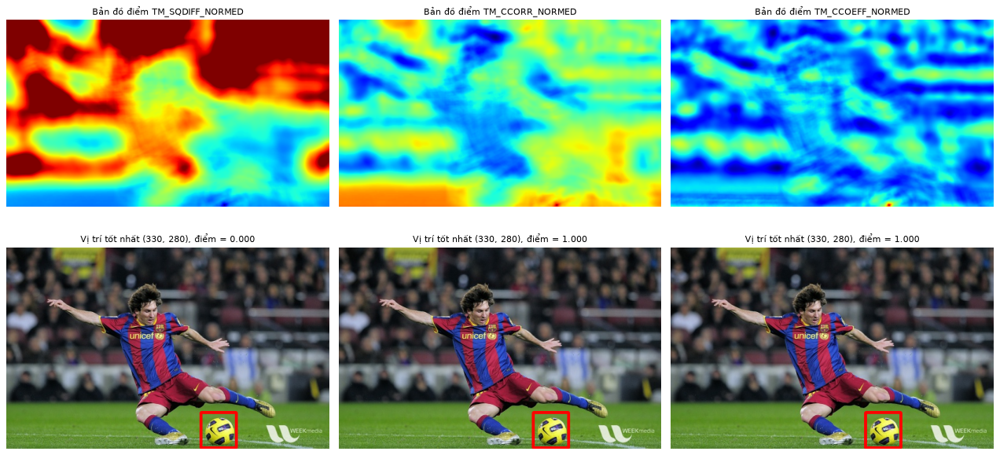

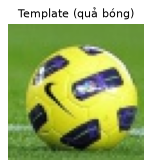

In [71]:
messi = load_sample('messi5.jpg')
template = messi[280:340, 330:390].copy()     # cắt quả bóng làm mẫu
th, tw = template.shape[:2]
methods = ['TM_SQDIFF_NORMED', 'TM_CCORR_NORMED', 'TM_CCOEFF_NORMED']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, m in enumerate(methods):
    res = cv2.matchTemplate(messi, template, getattr(cv2, m))
    min_v, max_v, min_loc, max_loc = cv2.minMaxLoc(res)
    top_left = min_loc if 'SQDIFF' in m else max_loc
    score = min_v if 'SQDIFF' in m else max_v
    vis = messi.copy()
    cv2.rectangle(vis, top_left, (top_left[0] + tw, top_left[1] + th), (0, 0, 255), 3)
    axes[0, i].imshow(res, cmap='jet'); axes[0, i].set_title(f'Bản đồ điểm {m}'); axes[0, i].axis('off')
    axes[1, i].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); axes[1, i].axis('off')
    axes[1, i].set_title(f'Vị trí tốt nhất {top_left}, điểm = {score:.3f}')
plt.tight_layout(); plt.show()
show(template, 'Template (quả bóng)', size=2)

### 18.1. Tìm NHIỀU đối tượng + Non-Maximum Suppression (NMS)

Lấy mọi vị trí có điểm > ngưỡng. Vì các vị trí lân cận một đối tượng đều có điểm cao, ta cần **NMS** để chỉ giữ 1 hộp cho mỗi đối tượng:
1. Sắp xếp hộp theo điểm giảm dần.
2. Lấy hộp điểm cao nhất, loại mọi hộp có **IoU** (Intersection over Union) với nó > ngưỡng.
3. Lặp lại.

Số vị trí vượt ngưỡng 0.8: 54  ->  sau NMS: 6 đối tượng


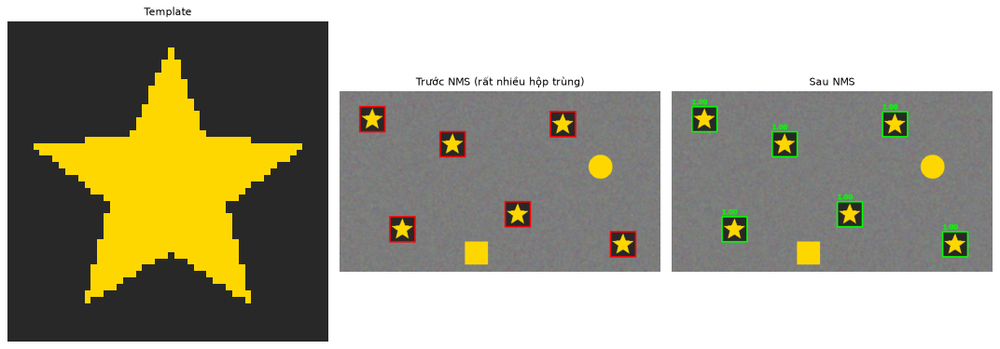

In [72]:
def nms(boxes, scores, iou_thresh=0.3):
    """boxes: Nx4 (x1, y1, x2, y2). Trả về chỉ số các hộp được giữ."""
    boxes = np.asarray(boxes, np.float32)
    order = np.argsort(scores)[::-1]
    keep = []
    while len(order):
        i = order[0]; keep.append(i)
        xx1 = np.maximum(boxes[i, 0], boxes[order[1:], 0]); yy1 = np.maximum(boxes[i, 1], boxes[order[1:], 1])
        xx2 = np.minimum(boxes[i, 2], boxes[order[1:], 2]); yy2 = np.minimum(boxes[i, 3], boxes[order[1:], 3])
        inter = np.clip(xx2 - xx1, 0, None) * np.clip(yy2 - yy1, 0, None)
        area = lambda b: (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
        iou = inter / (area(boxes[[i]]) + area(boxes[order[1:]]) - inter)
        order = order[1:][iou <= iou_thresh]
    return keep


# Tạo "màn chơi" với nhiều ngôi sao và vài vật gây nhiễu
rng = np.random.default_rng(5)
scene = cv2.GaussianBlur(rng.integers(90, 160, (360, 640, 3), dtype=np.uint8), (7, 7), 0)
icon = np.full((50, 50, 3), 40, np.uint8)
cv2.fillPoly(icon, [star_points(25, 26, 22, 9)], (0, 215, 255))
positions = [(40, 30), (200, 80), (420, 40), (100, 250), (330, 220), (540, 280)]
for x, y in positions:
    scene[y:y+50, x:x+50] = icon
cv2.circle(scene, (520, 150), 24, (0, 215, 255), -1)        # vật gây nhiễu: tròn cùng màu
cv2.rectangle(scene, (250, 300), (295, 345), (0, 215, 255), -1)

res = cv2.matchTemplate(scene, icon, cv2.TM_CCOEFF_NORMED)
ys, xs = np.where(res >= 0.8)
boxes = [(x, y, x + 50, y + 50) for x, y in zip(xs, ys)]
scores = res[ys, xs]
keep = nms(boxes, scores, 0.3)
print(f'Số vị trí vượt ngưỡng 0.8: {len(boxes)}  ->  sau NMS: {len(keep)} đối tượng')

raw, final = scene.copy(), scene.copy()
for (x1, y1, x2, y2) in boxes:
    cv2.rectangle(raw, (x1, y1), (x2, y2), (0, 0, 255), 1)
for i in keep:
    x1, y1, x2, y2 = boxes[i]
    cv2.rectangle(final, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(final, f'{scores[i]:.2f}', (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
show([icon, raw, final], ['Template', 'Trước NMS (rất nhiều hộp trùng)', 'Sau NMS'], size=4.5)

### 18.2. Hạn chế: không bất biến với tỉ lệ và góc xoay

In [73]:
for desc, tpl in [('Gốc', icon),
                  ('Thu nhỏ 70%', cv2.resize(icon, None, fx=0.7, fy=0.7)),
                  ('Phóng to 140%', cv2.resize(icon, None, fx=1.4, fy=1.4)),
                  ('Xoay 30°', cv2.warpAffine(icon, cv2.getRotationMatrix2D((25, 25), 30, 1), (50, 50), borderValue=(40, 40, 40)))]:
    best = cv2.minMaxLoc(cv2.matchTemplate(scene, tpl, cv2.TM_CCOEFF_NORMED))[1]
    print(f'{desc:14s}: điểm cao nhất = {best:.3f}')
print('=> Muốn bất biến tỉ lệ: lặp nhiều scale (multi-scale). Muốn bất biến xoay: dùng đặc trưng (mục 19).')

Gốc           : điểm cao nhất = 1.000
Thu nhỏ 70%   : điểm cao nhất = 0.612
Phóng to 140% : điểm cao nhất = 0.590
Xoay 30°      : điểm cao nhất = 0.498
=> Muốn bất biến tỉ lệ: lặp nhiều scale (multi-scale). Muốn bất biến xoay: dùng đặc trưng (mục 19).


---
## 19. Phát hiện góc & đặc trưng (Corners & Features)

**Góc** là điểm mà cường độ thay đổi mạnh theo **mọi hướng** — dễ định vị và theo dõi hơn nhiều so với cạnh hay vùng phẳng.

### 19.1. Harris Corner

Xét ma trận cấu trúc $M = \sum w(x,y) \begin{bmatrix} I_x^2 & I_xI_y \\ I_xI_y & I_y^2 \end{bmatrix}$ với trị riêng $\lambda_1, \lambda_2$:

$$R = \det(M) - k\,(\text{trace}\,M)^2 = \lambda_1\lambda_2 - k(\lambda_1+\lambda_2)^2$$

- $R$ lớn dương ⇒ **góc** (cả hai λ lớn); $R$ âm ⇒ **cạnh**; $|R|$ nhỏ ⇒ **vùng phẳng**.

`cv2.cornerHarris(gray_float32, blockSize, ksize, k)` — thường `blockSize=2`, `ksize=3`, `k=0.04`.

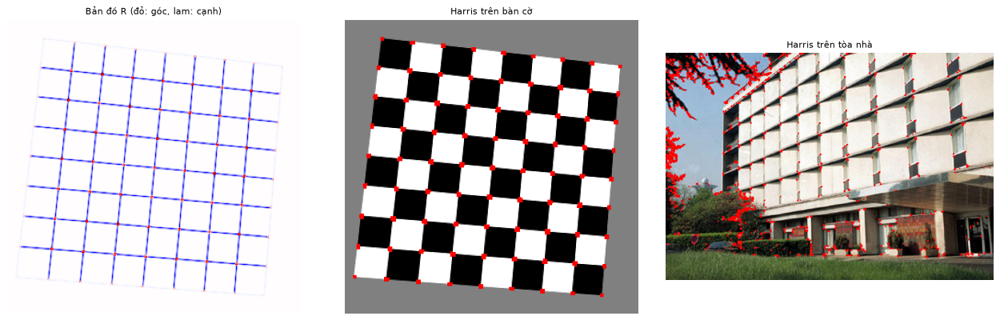

In [74]:
board = np.zeros((320, 320), np.uint8)
for i in range(8):
    for j in range(8):
        if (i + j) % 2:
            board[i*40:(i+1)*40, j*40:(j+1)*40] = 255
Mp = cv2.getPerspectiveTransform(np.float32([[0, 0], [320, 0], [320, 320], [0, 320]]),
                                 np.float32([[40, 20], [300, 50], [280, 300], [10, 280]]))
board = cv2.warpPerspective(board, Mp, (320, 320), borderValue=128)

def harris_vis(gray_img, color_img, thresh=0.01):
    R = cv2.cornerHarris(np.float32(gray_img), blockSize=2, ksize=3, k=0.04)
    vis = color_img.copy()
    vis[cv2.dilate(R, None) > thresh * R.max()] = (0, 0, 255)
    return R, vis

R_b, vis_b = harris_vis(board, cv2.cvtColor(board, cv2.COLOR_GRAY2BGR))
R_bd, vis_bd = harris_vis(bgray, building)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(R_b, cmap='seismic', vmin=-R_b.max(), vmax=R_b.max()); axes[0].set_title('Bản đồ R (đỏ: góc, lam: cạnh)')
axes[1].imshow(cv2.cvtColor(vis_b, cv2.COLOR_BGR2RGB)); axes[1].set_title('Harris trên bàn cờ')
axes[2].imshow(cv2.cvtColor(vis_bd, cv2.COLOR_BGR2RGB)); axes[2].set_title('Harris trên tòa nhà')
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

### 19.2. Shi-Tomasi — `cv2.goodFeaturesToTrack`

Dùng $R = \min(\lambda_1, \lambda_2)$; cho phép chọn **N góc tốt nhất**, cách nhau tối thiểu `minDistance`. Rất hay dùng làm điểm đầu vào cho theo dõi chuyển động (optical flow).

`cv2.cornerSubPix` tinh chỉnh vị trí góc tới độ chính xác **dưới pixel** (dùng trong hiệu chuẩn camera).

Ví dụ tọa độ góc (nguyên)  : [[261. 139.]
 [164. 128.]
 [ 67.  86.]]
Sau cornerSubPix (dưới pixel): [[260.51 138.35]
 [163.36 128.48]
 [ 66.4   86.5 ]]


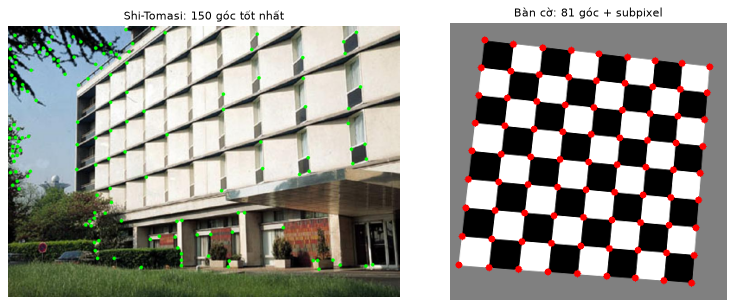

In [75]:
corners = cv2.goodFeaturesToTrack(bgray, maxCorners=150, qualityLevel=0.01, minDistance=10)
vis = building.copy()
for x, y in corners.reshape(-1, 2):
    cv2.circle(vis, (int(x), int(y)), 4, (0, 255, 0), -1)

bc = cv2.goodFeaturesToTrack(board, 100, 0.1, 15)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
bc_sub = cv2.cornerSubPix(board, bc.copy(), (5, 5), (-1, -1), criteria)
print('Ví dụ tọa độ góc (nguyên)  :', bc[:3].reshape(-1, 2))
print('Sau cornerSubPix (dưới pixel):', bc_sub[:3].reshape(-1, 2).round(2))
vis_b = cv2.cvtColor(board, cv2.COLOR_GRAY2BGR)
for x, y in bc_sub.reshape(-1, 2):
    cv2.circle(vis_b, (int(round(x)), int(round(y))), 4, (0, 0, 255), -1)
show([vis, vis_b], [f'Shi-Tomasi: {len(corners)} góc tốt nhất', f'Bàn cờ: {len(bc)} góc + subpixel'], size=5)

### 19.3. Keypoint & Descriptor: ORB và SIFT

Góc Harris chưa đủ để **so khớp** giữa các ảnh: cần **descriptor** — vector mô tả vùng quanh điểm, bất biến với xoay/tỉ lệ.

| Thuật toán | Descriptor | Bất biến | Tốc độ | Ghi chú |
|---|---|---|---|---|
| **ORB** | nhị phân 32 byte (256 bit) | xoay, tỉ lệ (pyramid) | rất nhanh | so khớp bằng khoảng cách **Hamming** |
| **SIFT** | 128 số thực | xoay, tỉ lệ, ánh sáng | chậm hơn | chính xác; miễn phí từ OpenCV 4.4 |

`drawKeypoints(..., flags=DRAW_RICH_KEYPOINTS)` vẽ cả **kích thước** (vòng tròn) và **hướng** (đường bán kính) của keypoint.

ORB : 500 keypoint, descriptor shape (500, 32), dtype uint8
SIFT: 501 keypoint, descriptor shape (501, 128), dtype float32
Một keypoint ORB: pt=(386.0, 431.0), size=31.0, angle=181.5°, response=0.00190


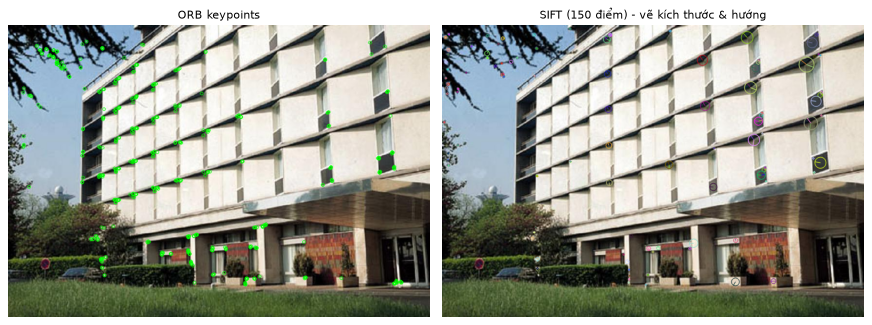

In [76]:
orb = cv2.ORB_create(nfeatures=500)
kp_orb, des_orb = orb.detectAndCompute(bgray, None)
sift = cv2.SIFT_create(nfeatures=500)
kp_sift, des_sift = sift.detectAndCompute(bgray, None)
print(f'ORB : {len(kp_orb)} keypoint, descriptor shape {des_orb.shape}, dtype {des_orb.dtype}')
print(f'SIFT: {len(kp_sift)} keypoint, descriptor shape {des_sift.shape}, dtype {des_sift.dtype}')
k0 = kp_orb[0]
print(f'Một keypoint ORB: pt={tuple(round(v, 1) for v in k0.pt)}, size={k0.size:.1f}, angle={k0.angle:.1f}°, response={k0.response:.5f}')

v1 = cv2.drawKeypoints(building, kp_orb, None, color=(0, 255, 0))
v2 = cv2.drawKeypoints(building, kp_sift[:150], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
show([v1, v2], ['ORB keypoints', 'SIFT (150 điểm) - vẽ kích thước & hướng'], size=5.5)

**Thử nghiệm bất biến:** so khớp ảnh với **chính nó sau khi xoay 30° và thu nhỏ 70%** — template matching thất bại, nhưng ORB vẫn tìm được các cặp điểm tương ứng.

Số cặp khớp: 213; khoảng cách tốt nhất = 5.0, tệ nhất = 76.0

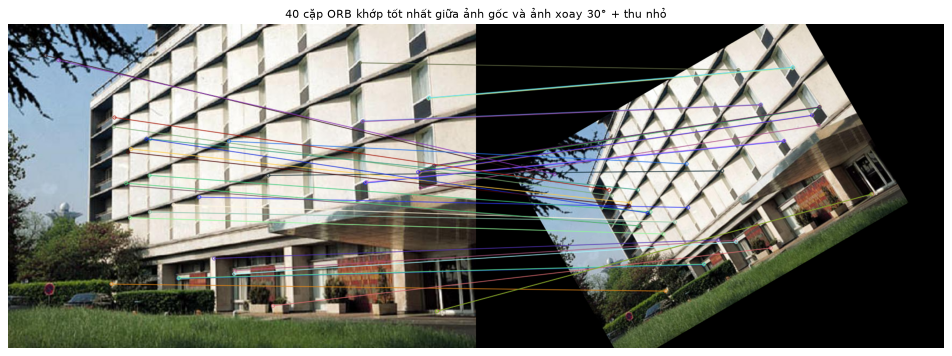

In [77]:
M2 = cv2.getRotationMatrix2D((bgray.shape[1] / 2, bgray.shape[0] / 2), 30, 0.7)
b2 = cv2.warpAffine(building, M2, (bgray.shape[1], bgray.shape[0]))
kp2, des2 = orb.detectAndCompute(cv2.cvtColor(b2, cv2.COLOR_BGR2GRAY), None)

bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)      # Hamming cho descriptor nhị phân
matches = sorted(bf.match(des_orb, des2), key=lambda m: m.distance)
print(f'Số cặp khớp: {len(matches)}; khoảng cách tốt nhất = {matches[0].distance}, tệ nhất = {matches[-1].distance}')
vis = cv2.drawMatches(building, kp_orb, b2, kp2, matches[:40], None,
                      flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
show(vis, '40 cặp ORB khớp tốt nhất giữa ảnh gốc và ảnh xoay 30° + thu nhỏ', size=12)

---
## 20. Image Pyramid (kim tự tháp ảnh)

- **Gaussian pyramid**: lặp lại *làm mờ Gauss + bỏ một nửa hàng/cột* — `cv2.pyrDown` (mỗi tầng giảm 1/2 mỗi chiều). `cv2.pyrUp` phóng to ×2 (nhưng **không khôi phục** chi tiết đã mất).
- **Laplacian pyramid**: $L_i = G_i - \text{pyrUp}(G_{i+1})$ ⇒ lưu **chi tiết** ở mỗi tầng. Từ tầng nhỏ nhất + các $L_i$ có thể **tái tạo hoàn hảo** ảnh gốc.

Ứng dụng: xử lý đa tỉ lệ (phát hiện đối tượng ở nhiều kích thước), nén, **trộn ảnh liền mạch**.

Kích thước các tầng Gaussian: [(480, 512), (240, 256), (120, 128), (60, 64)]


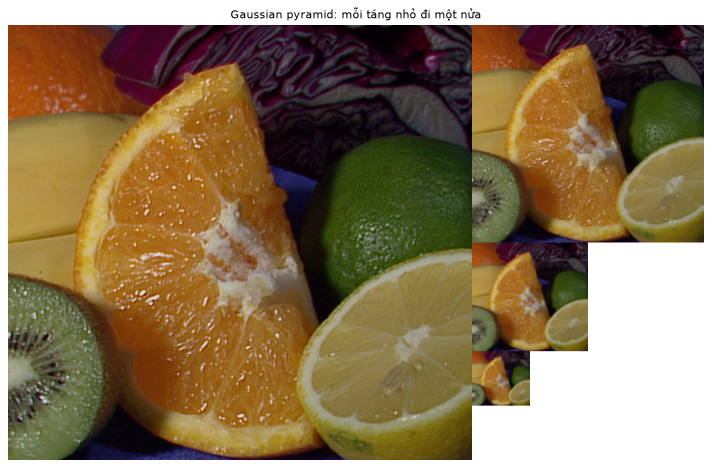

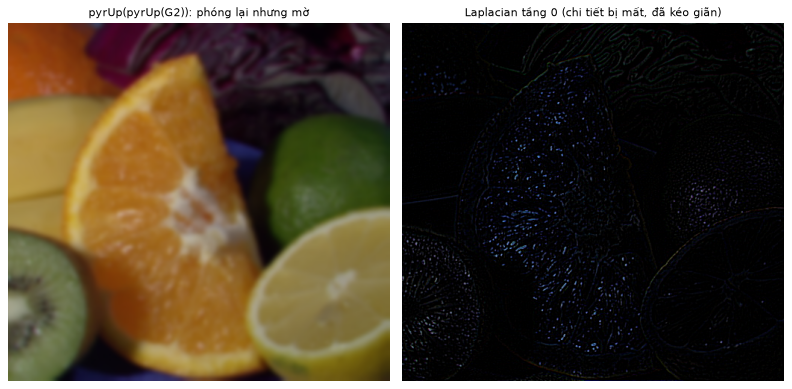

In [78]:
G = [img.copy()]
for _ in range(3):
    G.append(cv2.pyrDown(G[-1]))
print('Kích thước các tầng Gaussian:', [g.shape[:2] for g in G])

# Ghép các tầng vào 1 canvas để thấy rõ tỉ lệ
canvas = np.full((G[0].shape[0], G[0].shape[1] + G[1].shape[1], 3), 255, np.uint8)
canvas[:G[0].shape[0], :G[0].shape[1]] = G[0]
yoff = 0
for g in G[1:]:
    canvas[yoff:yoff + g.shape[0], G[0].shape[1]:G[0].shape[1] + g.shape[1]] = g
    yoff += g.shape[0]
show(canvas, 'Gaussian pyramid: mỗi tầng nhỏ đi một nửa', size=9)

up = cv2.pyrUp(cv2.pyrUp(G[2]), dstsize=(G[0].shape[1], G[0].shape[0]))
lap0 = cv2.subtract(G[0], cv2.pyrUp(G[1], dstsize=(G[0].shape[1], G[0].shape[0])))
show([up, cv2.normalize(lap0, None, 0, 255, cv2.NORM_MINMAX)],
     ['pyrUp(pyrUp(G2)): phóng lại nhưng mờ', 'Laplacian tầng 0 (chi tiết bị mất, đã kéo giãn)'], size=5)

### 20.1. Trộn ảnh liền mạch (Pyramid Blending) — "táo-cam" kinh điển

Ghép trực tiếp nửa trái ảnh A với nửa phải ảnh B ⇒ đường nối rất rõ. Pyramid blending ghép **từng tầng Laplacian** rồi tái tạo ⇒ tần số thấp được trộn trên vùng rộng, tần số cao trên vùng hẹp ⇒ **mối nối mượt**.

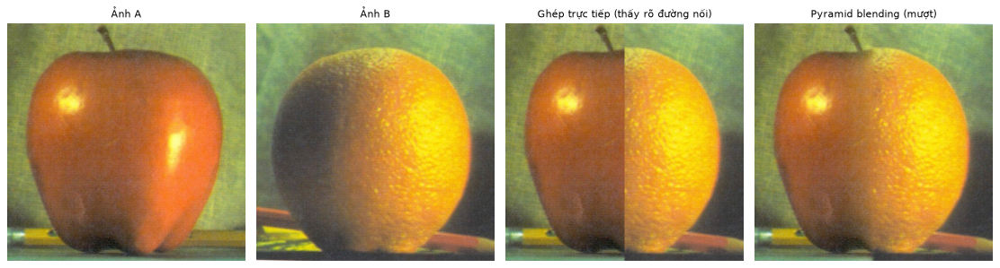

In [79]:
A = cv2.resize(load_sample('apple.jpg'), (512, 512)).astype(np.float32)
B = cv2.resize(load_sample('orange.jpg'), (512, 512)).astype(np.float32)
levels = 6


def gaussian_pyr(x, n):
    gp = [x]
    for _ in range(n):
        gp.append(cv2.pyrDown(gp[-1]))
    return gp


def laplacian_pyr(gp):
    lp = [gp[-1]]
    for i in range(len(gp) - 1, 0, -1):
        size = (gp[i - 1].shape[1], gp[i - 1].shape[0])
        lp.append(gp[i - 1] - cv2.pyrUp(gp[i], dstsize=size))
    return lp            # lp[0] là tầng nhỏ nhất


lpA, lpB = laplacian_pyr(gaussian_pyr(A, levels)), laplacian_pyr(gaussian_pyr(B, levels))
LS = [np.hstack((la[:, :la.shape[1] // 2], lb[:, la.shape[1] // 2:])) for la, lb in zip(lpA, lpB)]
blend = LS[0]
for i in range(1, len(LS)):
    blend = cv2.pyrUp(blend, dstsize=(LS[i].shape[1], LS[i].shape[0])) + LS[i]
blend = np.clip(blend, 0, 255).astype(np.uint8)
direct = np.hstack((A[:, :256], B[:, 256:])).astype(np.uint8)
show([A.astype(np.uint8), B.astype(np.uint8), direct, blend],
     ['Ảnh A', 'Ảnh B', 'Ghép trực tiếp (thấy rõ đường nối)', 'Pyramid blending (mượt)'], cols=4, size=3.5)

---
## 21. Miền tần số — Biến đổi Fourier

Mọi ảnh có thể biểu diễn bằng **tổng các sóng sin/cos** với tần số, hướng khác nhau:
- **Tần số thấp** (gần tâm phổ sau khi `fftshift`) ⇒ vùng thay đổi chậm: màu nền, mảng lớn.
- **Tần số cao** (xa tâm) ⇒ thay đổi nhanh: cạnh, chi tiết, **nhiễu**.

```python
F = np.fft.fft2(gray)             # hoặc cv2.dft(np.float32(gray), flags=cv2.DFT_COMPLEX_OUTPUT)
F = np.fft.fftshift(F)            # đưa tần số 0 về tâm
mag = np.log1p(np.abs(F))         # phổ biên độ (log để dễ nhìn)
img_back = np.real(np.fft.ifft2(np.fft.ifftshift(F_filtered)))
```

**Định lý tích chập:** tích chập trong miền không gian = **phép nhân** trong miền tần số ⇒ lọc ảnh = nhân phổ với một mặt nạ.

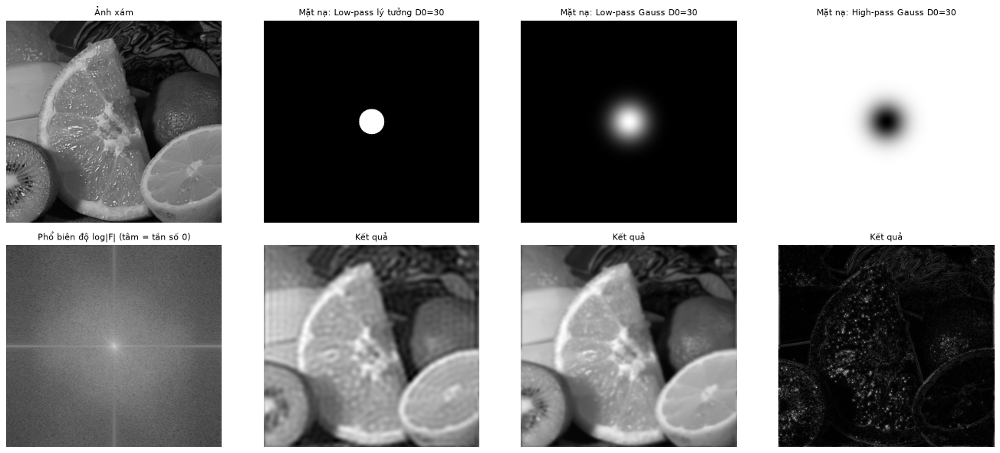

In [80]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
h, w = gray.shape
F = np.fft.fftshift(np.fft.fft2(gray))
mag = np.log1p(np.abs(F))

yy, xx = np.mgrid[0:h, 0:w]
dist = np.sqrt((yy - h / 2) ** 2 + (xx - w / 2) ** 2)
D0 = 30
masks = {
    f'Low-pass lý tưởng D0={D0}':  (dist <= D0).astype(np.float32),
    f'Low-pass Gauss D0={D0}':     np.exp(-dist ** 2 / (2 * D0 ** 2)).astype(np.float32),
    f'High-pass Gauss D0={D0}':    1 - np.exp(-dist ** 2 / (2 * D0 ** 2)).astype(np.float32),
}
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
axes[0, 0].imshow(gray, cmap='gray'); axes[0, 0].set_title('Ảnh xám')
axes[1, 0].imshow(mag, cmap='gray'); axes[1, 0].set_title('Phổ biên độ log|F| (tâm = tần số 0)')
for i, (name, m) in enumerate(masks.items(), start=1):
    back = np.real(np.fft.ifft2(np.fft.ifftshift(F * m)))
    axes[0, i].imshow(m, cmap='gray'); axes[0, i].set_title(f'Mặt nạ: {name}')
    axes[1, i].imshow(back if 'Low' in name else np.abs(back), cmap='gray'); axes[1, i].set_title('Kết quả')
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

🔍 **Nhận xét:**
- Low-pass ⇒ **làm mờ** (bỏ chi tiết). Bộ lọc **lý tưởng** (cắt cụt) gây hiện tượng **gợn sóng (ringing)** quanh cạnh; bộ lọc **Gauss** thì không.
- High-pass ⇒ chỉ còn **cạnh/chi tiết**.

### 21.1. Ứng dụng thực tế: xóa nhiễu tuần hoàn (sọc) bằng **notch filter**

Nhiễu sọc (do quét, do lưới điện, moiré…) rất khó xóa trong miền không gian, nhưng trong miền tần số nó chỉ là **vài điểm sáng** ⇒ chỉ cần "khoét" các điểm đó.

Đỉnh nhiễu tại (213, 221)
Đỉnh nhiễu tại (299, 259)
PSNR ảnh nhiễu sọc  : 19.38 dB
PSNR sau notch      : 32.63 dB
PSNR nếu dùng Gauss : 25.57 dB


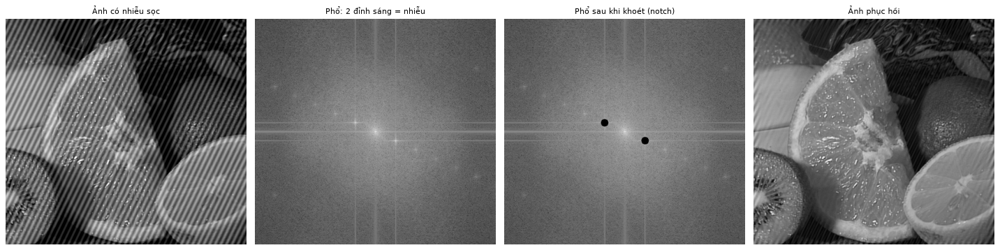

In [81]:
stripes = 40 * np.sin(2 * np.pi * (xx / 12 + yy / 25))
noisy = np.clip(gray + stripes, 0, 255).astype(np.float32)
Fn = np.fft.fftshift(np.fft.fft2(noisy))
mag_n = np.log1p(np.abs(Fn))

# Tự tìm các đỉnh nhiễu: bỏ vùng tâm, lấy 2 điểm sáng nhất (đối xứng qua tâm)
search = mag_n.copy()
cv2.circle(search, (w // 2, h // 2), 20, 0, -1)
notch = np.ones((h, w), np.float32)
for _ in range(2):
    _, _, _, peak = cv2.minMaxLoc(search)
    print('Đỉnh nhiễu tại', peak)
    cv2.circle(notch, peak, 8, 0, -1)
    cv2.circle(search, peak, 8, 0, -1)

restored = np.real(np.fft.ifft2(np.fft.ifftshift(Fn * notch)))
restored = np.clip(restored, 0, 255).astype(np.uint8)
g8 = gray.astype(np.uint8)
print(f'PSNR ảnh nhiễu sọc  : {cv2.PSNR(g8, noisy.astype(np.uint8)):.2f} dB')
print(f'PSNR sau notch      : {cv2.PSNR(g8, restored):.2f} dB')
print(f'PSNR nếu dùng Gauss : {cv2.PSNR(g8, cv2.GaussianBlur(noisy, (15, 15), 0).astype(np.uint8)):.2f} dB')

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
axes[0].imshow(noisy, cmap='gray'); axes[0].set_title('Ảnh có nhiễu sọc')
axes[1].imshow(mag_n, cmap='gray'); axes[1].set_title('Phổ: 2 đỉnh sáng = nhiễu')
axes[2].imshow(mag_n * notch, cmap='gray'); axes[2].set_title('Phổ sau khi khoét (notch)')
axes[3].imshow(restored, cmap='gray'); axes[3].set_title('Ảnh phục hồi')
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

---
## 22. Phân vùng ảnh (Image Segmentation)

### 22.1. K-Means — lượng tử hóa màu / phân cụm màu

Coi mỗi pixel là một điểm trong không gian 3D (B, G, R). K-Means chia chúng thành **K cụm**, mỗi pixel được thay bằng **màu tâm cụm** ⇒ ảnh chỉ còn K màu.

```python
compactness, labels, centers = cv2.kmeans(data_float32, K, None, criteria, attempts, flags)
```
- `criteria`: điều kiện dừng `(type, max_iter, epsilon)`.
- `attempts`: số lần chạy với khởi tạo khác nhau (lấy kết quả tốt nhất).
- `flags`: `cv2.KMEANS_PP_CENTERS` (k-means++) hoặc `cv2.KMEANS_RANDOM_CENTERS`.

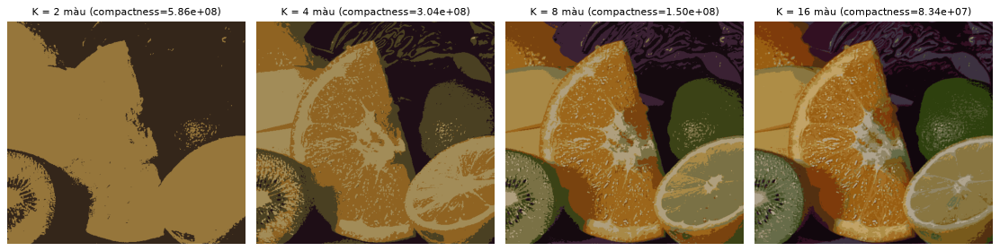

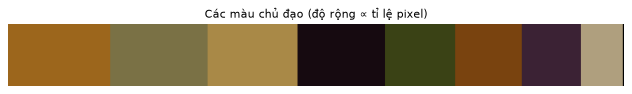

In [82]:
Z = img.reshape(-1, 3).astype(np.float32)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0)
outs, titles, palettes = [], [], []
for K in [2, 4, 8, 16]:
    compactness, labels, centers = cv2.kmeans(Z, K, None, criteria, 3, cv2.KMEANS_PP_CENTERS)
    centers = centers.astype(np.uint8)
    outs.append(centers[labels.ravel()].reshape(img.shape))
    titles.append(f'K = {K} màu (compactness={compactness:.2e})')
    palettes.append(centers)
show(outs, titles, cols=4, size=3.5)

# Bảng màu (palette) của K=8, sắp xếp theo tỉ lệ pixel
_, labels8, centers8 = cv2.kmeans(Z, 8, None, criteria, 3, cv2.KMEANS_PP_CENTERS)
counts = np.bincount(labels8.ravel(), minlength=8) / len(labels8)
order = np.argsort(counts)[::-1]
bar = np.zeros((50, 500, 3), np.uint8); x0 = 0
for i in order:
    x1 = x0 + int(round(counts[i] * 500))
    bar[:, x0:x1] = centers8[i]; x0 = x1
show(bar, 'Các màu chủ đạo (độ rộng ∝ tỉ lệ pixel)', size=8)

### 22.2. Watershed — tách các đối tượng chạm nhau

Hình dung ảnh xám như **địa hình**: nơi sáng là đỉnh núi, nơi tối là thung lũng. Đổ nước từ các **điểm đánh dấu (markers)**; nơi nước từ các nguồn khác nhau gặp nhau ⇒ dựng **đập** = đường biên phân vùng.

Quy trình chuẩn với OpenCV:
1. Nhị phân hóa (Otsu) + opening khử nhiễu.
2. **Sure background**: dilate vùng đối tượng.
3. **Sure foreground**: **distance transform** (khoảng cách tới nền gần nhất) rồi ngưỡng ⇒ "lõi" của từng đối tượng.
4. **Unknown** = sure_bg − sure_fg.
5. Gán nhãn các lõi bằng `connectedComponents` ⇒ markers; vùng unknown = 0.
6. `cv2.watershed(img_color, markers)` ⇒ biên được đánh dấu **−1**.

connectedComponents trực tiếp: 2 vùng (sai vì đồng xu chạm nhau)
Watershed: 7 đối tượng


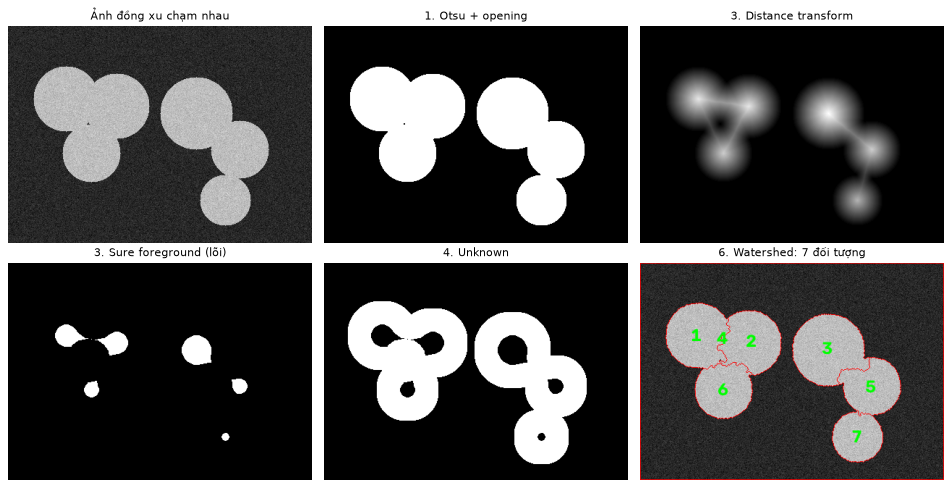

In [83]:
rng = np.random.default_rng(2)
coins = np.full((300, 420), 40, np.uint8)
for (x, y, r) in [(80, 100, 45), (150, 110, 45), (115, 175, 40), (260, 120, 50), (320, 170, 40), (300, 240, 35)]:
    cv2.circle(coins, (x, y), r, 190, -1)
coins = np.clip(coins + rng.normal(0, 12, coins.shape), 0, 255).astype(np.uint8)
coins_bgr = cv2.cvtColor(coins, cv2.COLOR_GRAY2BGR)

_, thresh = cv2.threshold(cv2.GaussianBlur(coins, (5, 5), 0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)
sure_bg = cv2.dilate(opening, kernel, iterations=3)
dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(dist, 0.6 * dist.max(), 255, 0)
sure_fg = sure_fg.astype(np.uint8)
unknown = cv2.subtract(sure_bg, sure_fg)

n_markers, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1            # nền chắc chắn = 1 (không phải 0)
markers[unknown == 255] = 0      # vùng chưa biết = 0 -> watershed sẽ quyết định
markers = cv2.watershed(coins_bgr, markers)

result = coins_bgr.copy()
result[markers == -1] = (0, 0, 255)                 # đường biên
n_obj = len(np.unique(markers)) - 2                 # trừ nhãn -1 (biên) và 1 (nền)
for lbl in range(2, markers.max() + 1):
    ys, xs = np.where(markers == lbl)
    cv2.putText(result, str(lbl - 1), (int(xs.mean()) - 8, int(ys.mean()) + 8), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

n_cc, _ = cv2.connectedComponents(opening)
print(f'connectedComponents trực tiếp: {n_cc - 1} vùng (sai vì đồng xu chạm nhau)')
print(f'Watershed: {n_obj} đối tượng')
show([coins, opening, cv2.normalize(dist, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8),
      sure_fg, unknown, result],
     ['Ảnh đồng xu chạm nhau', '1. Otsu + opening', '3. Distance transform',
      '3. Sure foreground (lõi)', '4. Unknown', f'6. Watershed: {n_obj} đối tượng'], cols=3, size=4)

### 22.3. GrabCut — tách tiền cảnh tương tác

Chỉ cần vẽ **một hình chữ nhật bao quanh đối tượng**; GrabCut dùng mô hình **Gaussian Mixture** cho màu tiền cảnh/hậu cảnh + **graph cut** để tìm biên tối ưu, lặp nhiều lần.

Mask kết quả có 4 giá trị: `GC_BGD=0` (chắc chắn nền), `GC_FGD=1` (chắc chắn đối tượng), `GC_PR_BGD=2` (có thể nền), `GC_PR_FGD=3` (có thể đối tượng).

GrabCut 5 vòng lặp: 1.33 s


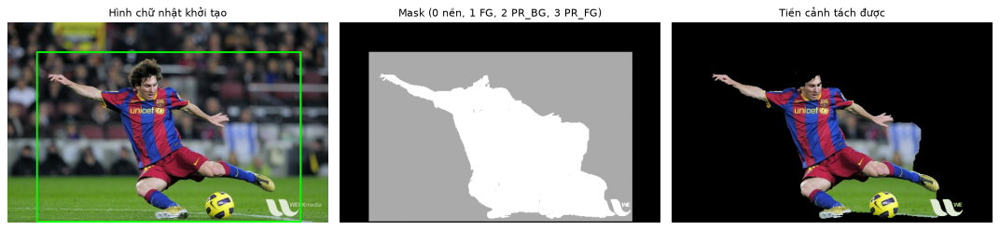

In [84]:
mask_gc = np.zeros(messi.shape[:2], np.uint8)
bgd_model = np.zeros((1, 65), np.float64)
fgd_model = np.zeros((1, 65), np.float64)
rect = (50, 50, 450, 290)                       # (x, y, w, h) bao quanh cầu thủ

t = time.perf_counter()
cv2.grabCut(messi, mask_gc, rect, bgd_model, fgd_model, 5, cv2.GC_INIT_WITH_RECT)
print(f'GrabCut 5 vòng lặp: {time.perf_counter() - t:.2f} s')
fg_mask = np.where((mask_gc == cv2.GC_FGD) | (mask_gc == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)

vis = messi.copy()
cv2.rectangle(vis, rect[:2], (rect[0] + rect[2], rect[1] + rect[3]), (0, 255, 0), 2)
cut = cv2.bitwise_and(messi, messi, mask=fg_mask)
show([vis, (mask_gc * 85).astype(np.uint8), cut],
     ['Hình chữ nhật khởi tạo', 'Mask (0 nền, 1 FG, 2 PR_BG, 3 PR_FG)', 'Tiền cảnh tách được'], size=4.5)

🔍 **Nhận xét:** Kết quả có thể còn sót nền (cỏ) hoặc mất một phần đối tượng. Trong ứng dụng thực tế, người dùng sẽ **tô thêm nét** đánh dấu FG/BG lên mask rồi gọi lại `grabCut` với `cv2.GC_INIT_WITH_MASK` để tinh chỉnh.

---
## 23. Phục hồi ảnh (Inpainting)

`cv2.inpaint(img, mask, inpaintRadius, method)` "lấp" các pixel trong `mask` (≠ 0) bằng thông tin từ vùng xung quanh — dùng để **xóa vết xước, chữ, watermark, vật thể nhỏ**.

- `cv2.INPAINT_TELEA`: Fast Marching Method — lấp dần từ biên vào trong.
- `cv2.INPAINT_NS`: dựa trên phương trình Navier–Stokes (động lực học chất lỏng) — lan truyền theo đường đẳng sáng.

PSNR ảnh hỏng : 13.91 dB
PSNR TELEA    : 32.76 dB
PSNR NS       : 32.77 dB


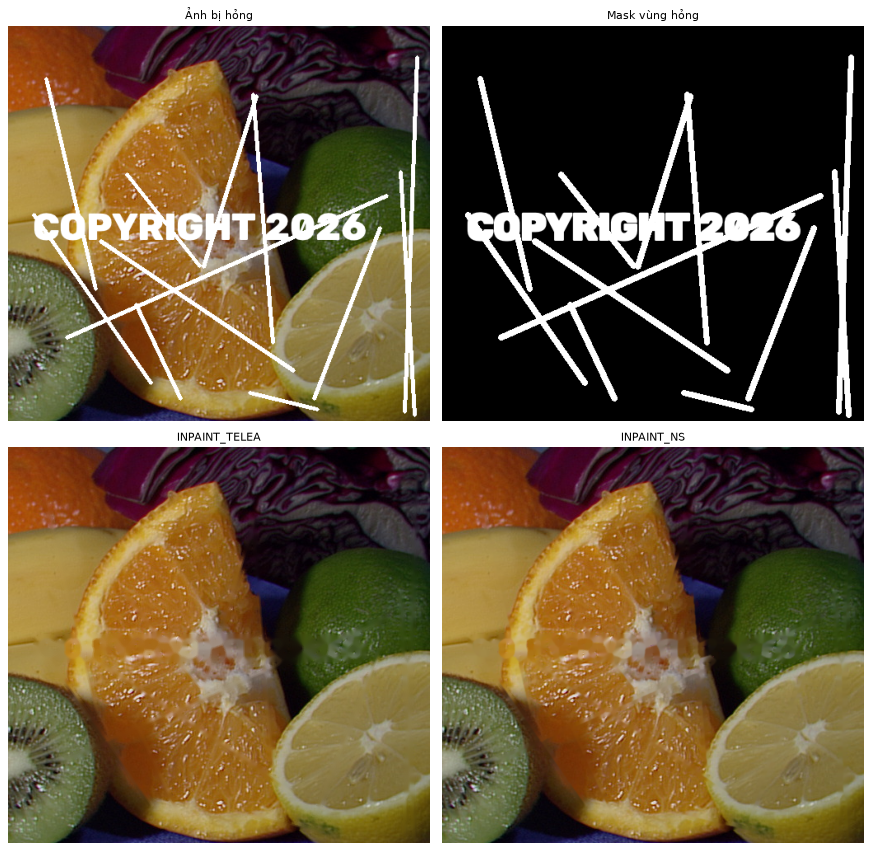

In [85]:
rng = np.random.default_rng(4)
damaged = img.copy()
dmask = np.zeros(img.shape[:2], np.uint8)
for _ in range(12):                                              # vết xước ngẫu nhiên
    p1 = tuple(int(v) for v in rng.integers(0, [img.shape[1], img.shape[0]]))
    p2 = tuple(int(v) for v in rng.integers(0, [img.shape[1], img.shape[0]]))
    cv2.line(damaged, p1, p2, (255, 255, 255), 3)
    cv2.line(dmask, p1, p2, 255, 3)
cv2.putText(damaged, 'COPYRIGHT 2026', (30, 260), cv2.FONT_HERSHEY_DUPLEX, 1.6, (255, 255, 255), 4)
cv2.putText(dmask, 'COPYRIGHT 2026', (30, 260), cv2.FONT_HERSHEY_DUPLEX, 1.6, 255, 4)
dmask = cv2.dilate(dmask, np.ones((3, 3), np.uint8))           # mở rộng mask một chút cho chắc

r_telea = cv2.inpaint(damaged, dmask, 3, cv2.INPAINT_TELEA)
r_ns = cv2.inpaint(damaged, dmask, 3, cv2.INPAINT_NS)
print(f'PSNR ảnh hỏng : {cv2.PSNR(img, damaged):.2f} dB')
print(f'PSNR TELEA    : {cv2.PSNR(img, r_telea):.2f} dB')
print(f'PSNR NS       : {cv2.PSNR(img, r_ns):.2f} dB')
show([damaged, dmask, r_telea, r_ns], ['Ảnh bị hỏng', 'Mask vùng hỏng', 'INPAINT_TELEA', 'INPAINT_NS'], cols=2, size=5.5)

🔍 **Nhận xét:** Inpainting cổ điển hoạt động tốt với vùng hỏng **mảnh** (vết xước, chữ). Với vùng lớn (xóa cả một người) nó sẽ để lại vệt nhòe — khi đó cần phương pháp học sâu (LaMa, Stable Diffusion inpainting…).

**Mẹo:** kết hợp với mục 4.3/10 để **tự động tạo mask** — ví dụ ngưỡng các pixel rất trắng để xóa chữ watermark trắng.

---
## 24. 🚀 Dự án tổng hợp: Document Scanner (máy quét tài liệu)

Kết hợp gần như mọi kỹ thuật đã học để biến **ảnh chụp nghiêng một tờ giấy** thành **bản scan phẳng, đen trắng rõ nét** (giống CamScanner):

```
Ảnh chụp → Xám → Làm mờ → Canny → Dilate → findContours → Contour 4 đỉnh lớn nhất
        → Sắp xếp 4 góc → getPerspectiveTransform → warpPerspective → Adaptive threshold
```

Vì không có ảnh chụp thật, trước hết ta **tự tạo ảnh chụp giả lập**: một hóa đơn được đặt nghiêng trên mặt bàn gỗ, có bóng đổ và ánh sáng không đều.

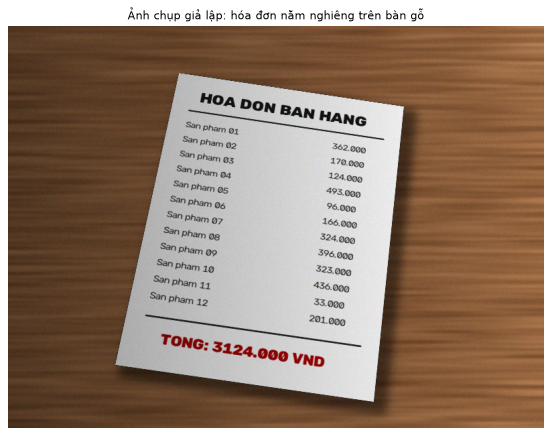

In [86]:
# ---------- Tạo ảnh "chụp" giả lập ----------
rng = np.random.default_rng(8)
doc = np.full((560, 400, 3), 245, np.uint8)
cv2.putText(doc, 'HOA DON BAN HANG', (45, 55), cv2.FONT_HERSHEY_DUPLEX, 1.0, (20, 20, 20), 2)
cv2.line(doc, (30, 75), (370, 75), (40, 40, 40), 2)
total = 0
for i in range(12):
    price = int(rng.integers(10, 500)); total += price
    cv2.putText(doc, f'San pham {i + 1:02d}', (30, 110 + i * 30), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (40, 40, 40), 1)
    cv2.putText(doc, f'{price:>4d}.000', (280, 110 + i * 30), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (40, 40, 40), 1)
cv2.line(doc, (30, 470), (370, 470), (40, 40, 40), 2)
cv2.putText(doc, f'TONG: {total}.000 VND', (60, 515), cv2.FONT_HERSHEY_DUPLEX, 0.85, (0, 0, 160), 2)

H0, W0 = 600, 800
wood = rng.normal(0, 1, (H0, W0)).astype(np.float32)
wood = cv2.GaussianBlur(wood, (0, 0), sigmaX=40, sigmaY=2)                    # vân gỗ kéo dài theo ngang
wood = cv2.normalize(wood, None, 0, 1, cv2.NORM_MINMAX)
table = np.dstack([40 + 40 * wood, 70 + 50 * wood, 110 + 60 * wood]).astype(np.uint8)

src_c = np.float32([[0, 0], [399, 0], [399, 559], [0, 559]])
dst_c = np.float32([[255, 70], [590, 120], [545, 560], [160, 505]])
Mdoc = cv2.getPerspectiveTransform(src_c, dst_c)
warped_doc = cv2.warpPerspective(doc, Mdoc, (W0, H0))
paper_mask = cv2.warpPerspective(np.full(doc.shape[:2], 255, np.uint8), Mdoc, (W0, H0))

shadow = cv2.GaussianBlur(cv2.dilate(paper_mask, np.ones((15, 15), np.uint8)), (41, 41), 0)
shadow = np.roll(shadow, (12, 12), axis=(0, 1))
photo = (table * (1 - 0.5 * shadow[..., None] / 255)).astype(np.uint8)       # bóng đổ của tờ giấy
photo = np.where(paper_mask[..., None] > 0, warped_doc, photo)
light = np.tile(np.linspace(0.6, 1.1, W0), (H0, 1))[..., None]                # ánh sáng không đều
photo = np.clip(photo * light + rng.normal(0, 4, photo.shape), 0, 255).astype(np.uint8)
show(photo, 'Ảnh chụp giả lập: hóa đơn nằm nghiêng trên bàn gỗ', size=7)

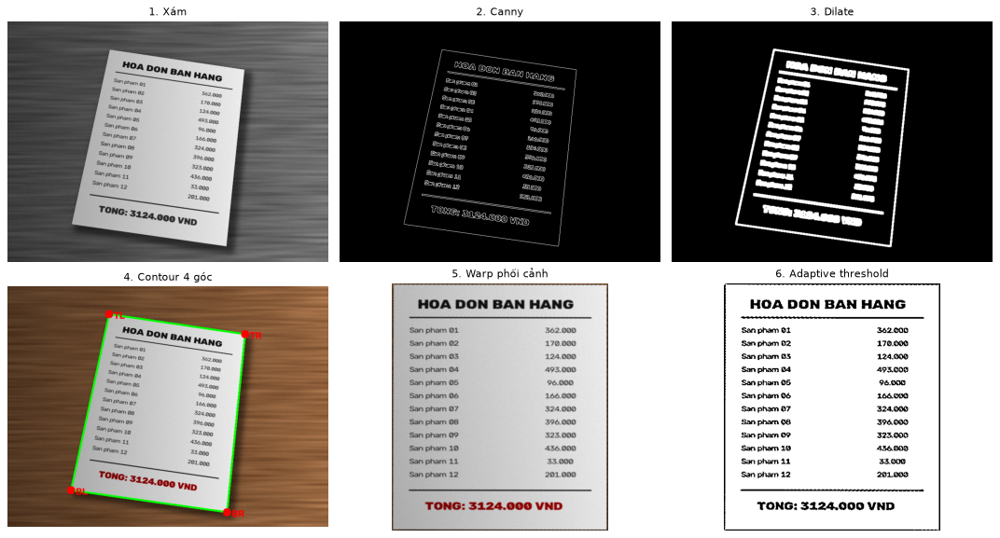

Đã lưu kết quả: outputs_opencv\scanned_document.png | kích thước (449, 392)


In [87]:
# ---------- PIPELINE DOCUMENT SCANNER ----------
def order_points(pts):
    """Sắp xếp 4 điểm theo thứ tự: trên-trái, trên-phải, dưới-phải, dưới-trái."""
    pts = pts.reshape(4, 2).astype(np.float32)
    s = pts.sum(axis=1)              # x + y: nhỏ nhất = TL, lớn nhất = BR
    d = np.diff(pts, axis=1).ravel() # y - x: nhỏ nhất = TR, lớn nhất = BL
    return np.array([pts[np.argmin(s)], pts[np.argmin(d)], pts[np.argmax(s)], pts[np.argmax(d)]], np.float32)


def four_point_transform(image, pts):
    tl, tr, br, bl = rect = order_points(pts)
    width = int(max(np.linalg.norm(br - bl), np.linalg.norm(tr - tl)))
    height = int(max(np.linalg.norm(tr - br), np.linalg.norm(tl - bl)))
    dst = np.float32([[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]])
    M = cv2.getPerspectiveTransform(rect, dst)
    return cv2.warpPerspective(image, M, (width, height))


def scan_document(image, debug=False):
    steps = {}
    gray_ = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY);               steps['1. Xám'] = gray_
    blur_ = cv2.GaussianBlur(gray_, (5, 5), 0)
    edges_ = cv2.Canny(blur_, 50, 150);                             steps['2. Canny'] = edges_
    edges_ = cv2.dilate(edges_, np.ones((3, 3), np.uint8), iterations=2)   # nối các đoạn cạnh đứt
    steps['3. Dilate'] = edges_
    cnts, _ = cv2.findContours(edges_, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    cnts = sorted(cnts, key=cv2.contourArea, reverse=True)[:10]      # các contour lớn nhất
    doc_cnt = None
    for c in cnts:
        if cv2.contourArea(c) < 0.08 * image.shape[0] * image.shape[1]:
            break
        peri = cv2.arcLength(c, True)
        for eps in (0.02, 0.03, 0.04, 0.05):
            approx = cv2.approxPolyDP(c, eps * peri, True)
            if len(approx) == 4 and cv2.isContourConvex(approx):
                doc_cnt = approx
                break
        if doc_cnt is not None:
            break
    if doc_cnt is None:
        doc_cnt = cv2.boxPoints(cv2.minAreaRect(cnts[0])).astype(np.int32).reshape(-1, 1, 2)
    vis_ = image.copy()
    cv2.drawContours(vis_, [doc_cnt], -1, (0, 255, 0), 3)
    for i, p in enumerate(order_points(doc_cnt)):
        cv2.circle(vis_, tuple(int(v) for v in p), 10, (0, 0, 255), -1)
        cv2.putText(vis_, ['TL', 'TR', 'BR', 'BL'][i], tuple(int(v) + 12 for v in p), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
    steps['4. Contour 4 góc'] = vis_
    flat = four_point_transform(image, doc_cnt);                    steps['5. Warp phối cảnh'] = flat
    flat_gray = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    scanned = cv2.adaptiveThreshold(flat_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 21, 10)
    steps['6. Adaptive threshold'] = scanned
    return scanned, flat, steps


scanned, flat, steps = scan_document(photo)
show(list(steps.values()), list(steps.keys()), cols=3, size=4.5)
cv2.imwrite(str(OUT_DIR / 'scanned_document.png'), scanned)
print('Đã lưu kết quả:', OUT_DIR / 'scanned_document.png', '| kích thước', scanned.shape)

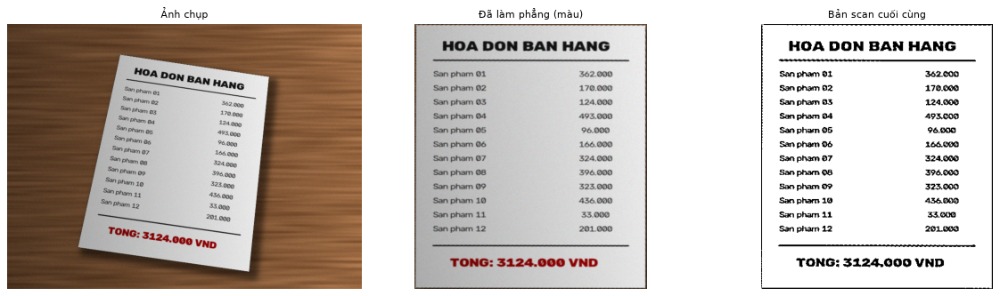

In [88]:
show([photo, flat, scanned], ['Ảnh chụp', 'Đã làm phẳng (màu)', 'Bản scan cuối cùng'], size=5)

🔍 **Phân tích pipeline:**

| Bước | Kỹ thuật (mục) | Vì sao cần |
|---|---|---|
| Xám + Gaussian | 4, 11 | giảm nhiễu, vân gỗ để Canny không bắt cạnh vụn |
| Canny | 13 | tìm biên tờ giấy |
| Dilate | 14 | nối các đoạn biên bị đứt (do bóng, ánh sáng) |
| findContours + sort theo diện tích | 15 | tờ giấy thường là vật lớn nhất |
| approxPolyDP → 4 đỉnh | 15.2 | xác nhận đó là tứ giác |
| order_points + warpPerspective | 7.4 | "nhìn thẳng" tài liệu |
| Adaptive threshold | 10.3 | khử ánh sáng không đều, cho bản đen trắng sạch |

✍️ **Mở rộng:** (1) Áp dụng `scan_document` cho ảnh `sudoku.png` để tự tìm 4 góc thay vì nhập tay ở mục 7.4. (2) Thêm bước khử bóng bằng *chia cho nền*: `cv2.divide(gray, cv2.medianBlur(cv2.dilate(gray, np.ones((7,7))), 21), scale=255)`.

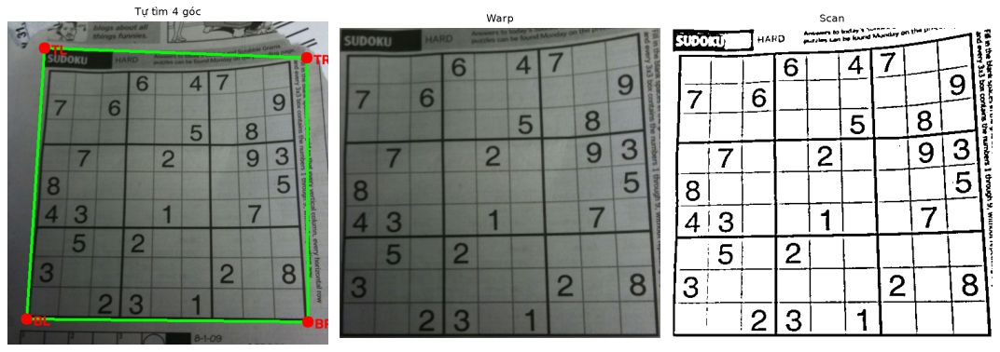

In [89]:
# Mở rộng (1): tự động tìm 4 góc sudoku bằng chính pipeline trên
sud_scan, sud_flat, sud_steps = scan_document(sudoku)
show([sud_steps['4. Contour 4 góc'], sud_flat, sud_scan], ['Tự tìm 4 góc', 'Warp', 'Scan'], size=4.5)

---
## 25. Tra cứu nhanh, lỗi hay gặp, bài tập & lời giải

### 25.1. Bảng tra cứu hàm

| Nhóm | Hàm | Ghi nhớ |
|---|---|---|
| I/O | `imread`, `imwrite`, `imdecode`, `imencode` | `imread` trả `None` nếu lỗi |
| Màu | `cvtColor(img, COLOR_BGR2GRAY / HSV / LAB / YCrCb)` | H ∈ [0, 179] |
| Mask màu | `inRange(hsv, lo, hi)` | đỏ cần 2 khoảng |
| Số học | `add`, `subtract`, `multiply`, `addWeighted`, `absdiff` | bão hòa, không tràn |
| Bitwise | `bitwise_and/or/xor/not(..., mask=)` | |
| Hình học | `resize`, `flip`, `rotate`, `warpAffine`, `warpPerspective`, `remap` | `dsize = (W, H)` |
| Ma trận | `getRotationMatrix2D`, `getAffineTransform` (3 điểm), `getPerspectiveTransform` (4 điểm) | |
| Điểm ảnh | `convertScaleAbs`, `LUT`, `normalize` | |
| Histogram | `calcHist`, `equalizeHist`, `createCLAHE`, `compareHist` | ảnh màu: xử lý kênh sáng |
| Ngưỡng | `threshold` (+`THRESH_OTSU`), `adaptiveThreshold` | blockSize lẻ |
| Lọc | `filter2D`, `blur`, `GaussianBlur`, `medianBlur`, `bilateralFilter`, `fastNlMeansDenoisingColored` | ksize lẻ |
| Cạnh | `Sobel`, `Scharr`, `Laplacian`, `Canny` | dùng `CV_64F` cho đạo hàm |
| Hình thái | `getStructuringElement`, `erode`, `dilate`, `morphologyEx` | đối tượng màu trắng |
| Contour | `findContours`, `drawContours`, `contourArea`, `arcLength`, `moments`, `boundingRect`, `minAreaRect`, `approxPolyDP`, `convexHull`, `matchShapes` | |
| Vùng | `connectedComponentsWithStats`, `distanceTransform` | nhãn 0 = nền |
| Hough | `HoughLines`, `HoughLinesP`, `HoughCircles` | đầu vào là cạnh / ảnh xám mờ |
| Mẫu | `matchTemplate` + `minMaxLoc` | SQDIFF: lấy min |
| Đặc trưng | `cornerHarris`, `goodFeaturesToTrack`, `ORB_create`, `SIFT_create`, `BFMatcher` | ORB → Hamming |
| Pyramid | `pyrDown`, `pyrUp` | |
| Phân vùng | `kmeans`, `watershed`, `grabCut` | |
| Phục hồi | `inpaint` | mask ≠ 0 là vùng cần lấp |

### 25.2. Những lỗi người mới hay gặp

| Triệu chứng | Nguyên nhân | Cách sửa |
|---|---|---|
| `AttributeError: 'NoneType' object has no attribute 'shape'` | `imread` đọc thất bại (sai đường dẫn / đường dẫn tiếng Việt) | kiểm tra `img is None`, dùng `imread_unicode` |
| Màu hiển thị bị đỏ ↔ xanh | đưa BGR vào Matplotlib | `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` |
| Ảnh sáng bỗng có đốm đen | tràn số `uint8` khi cộng NumPy | dùng `cv2.add` hoặc ép kiểu + `np.clip` |
| `error: (-215:Assertion failed) ... ksize.width % 2 == 1` | kích thước kernel chẵn | dùng số lẻ: 3, 5, 7… |
| `resize` ra ảnh bị xoay chiều | truyền `(H, W)` thay vì `(W, H)` | `cv2.resize(img, (width, height))` |
| Pixel truy cập sai vị trí | nhầm `img[x, y]` | đúng là `img[y, x]` |
| `findContours` tìm ra 1 contour bao cả ảnh | đối tượng đen trên nền trắng | dùng `THRESH_BINARY_INV` để đối tượng thành màu trắng |
| `findContours` báo lỗi kiểu dữ liệu | ảnh không phải `uint8` 1 kênh | chuyển xám + ngưỡng trước |
| Sobel mất một nửa cạnh | `ddepth=CV_8U` cắt giá trị âm | `CV_64F` rồi `convertScaleAbs` |
| Ảnh float hiển thị toàn trắng | float phải nằm trong [0, 1] với `imshow` | `normalize` hoặc ép về `uint8` |
| Sửa ROI làm hỏng ảnh gốc | slicing NumPy là view | `.copy()` |
| `cv2.imshow` treo notebook | GUI cửa sổ không hợp Jupyter | dùng Matplotlib |
| `ValueError: not enough values to unpack` với `findContours` | khác phiên bản (OpenCV 3 trả 3 giá trị) | `cnts = cv2.findContours(...)[-2]` |

### 25.3. Bài tập tổng hợp

1. **Đếm kẹo theo màu:** Với `smarties.png`, đếm có bao nhiêu viên kẹo mỗi màu (gợi ý: HoughCircles để lấy vị trí, lấy giá trị H trung bình trong mỗi vòng tròn).
2. **Phát hiện điểm khác nhau:** Tạo 2 ảnh gần giống nhau (sửa vài chỗ) và khoanh tròn các điểm khác bằng `absdiff` + threshold + contour.
3. **Bộ lọc "hoạt hình" (cartoon):** bilateral filter nhiều lần + cạnh từ adaptive threshold + `bitwise_and`.
4. **Đo kích thước vật thể:** Biết một vật tham chiếu có chiều rộng thật 2 cm, hãy tính kích thước các vật còn lại trong ảnh hình học ở mục 15 (pixel → cm).
5. **Làm mờ biển số / khuôn mặt:** cho một hình chữ nhật, áp dụng hiệu ứng pixelate (resize nhỏ bằng `INTER_LINEAR` rồi phóng lại bằng `INTER_NEAREST`).
6. **Xoay thẳng văn bản (deskew):** tạo ảnh chữ bị nghiêng, dùng `minAreaRect` trên các pixel chữ để tìm góc nghiêng và xoay lại.

### 25.4. Lời giải gợi ý cho các bài tập nhỏ

<details><summary><b>Bài 3, 4, 10, 13 (nhấn để mở)</b></summary>

```python
# Bài 3.2: nửa trái gốc, nửa phải âm bản
out = img.copy(); w = img.shape[1]
out[:, w // 2:] = 255 - out[:, w // 2:]

# Bài 4: kẹo xanh lam trong smarties
hsv = cv2.cvtColor(smarties, cv2.COLOR_BGR2HSV)
mask = cv2.inRange(hsv, (95, 120, 60), (130, 255, 255))

# Bài 10: Otsu trên kênh S
s = cv2.cvtColor(smarties, cv2.COLOR_BGR2HSV)[..., 1]
_, m = cv2.threshold(cv2.GaussianBlur(s, (5, 5), 0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Bài 13: ảnh phác thảo bút chì
g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(255 - g, (21, 21), 0)
sketch = cv2.divide(g, 255 - blur, scale=256)
```
</details>

Ô dưới đây chạy lời giải cho một số bài để bạn đối chiếu:

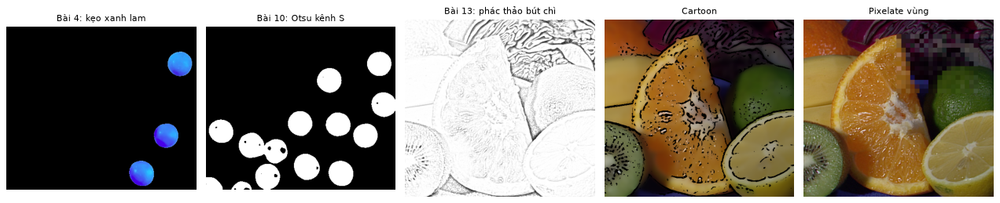

In [90]:
# --- Bài 4 & 10 ---
sm_hsv = cv2.cvtColor(smarties, cv2.COLOR_BGR2HSV)
blue_mask = cv2.inRange(sm_hsv, np.array((95, 120, 60)), np.array((130, 255, 255)))
_, s_otsu = cv2.threshold(cv2.GaussianBlur(sm_hsv[..., 1], (5, 5), 0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# --- Bài 13: phác thảo bút chì ---
g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
sketch = cv2.divide(g, 255 - cv2.GaussianBlur(255 - g, (21, 21), 0), scale=256)

# --- Bài tổng hợp 3: cartoon ---
color_c = img.copy()
for _ in range(5):
    color_c = cv2.bilateralFilter(color_c, 9, 50, 50)
edges_c = cv2.adaptiveThreshold(cv2.medianBlur(g, 7), 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 9, 4)
cartoon = cv2.bitwise_and(color_c, color_c, mask=edges_c)

# --- Bài tổng hợp 5: pixelate một vùng ---
pix = img.copy()
x, y, w_, h_ = 250, 40, 220, 160
small_roi = cv2.resize(pix[y:y+h_, x:x+w_], (w_ // 12, h_ // 12), interpolation=cv2.INTER_LINEAR)
pix[y:y+h_, x:x+w_] = cv2.resize(small_roi, (w_, h_), interpolation=cv2.INTER_NEAREST)

show([cv2.bitwise_and(smarties, smarties, mask=blue_mask), s_otsu, sketch, cartoon, pix],
     ['Bài 4: kẹo xanh lam', 'Bài 10: Otsu kênh S', 'Bài 13: phác thảo bút chì', 'Cartoon', 'Pixelate vùng'],
     cols=5, size=3.2)

Tổng số kẹo: 12
Theo màu   : {'lam': 3, 'do': 6, 'cam': 1, 'luc': 2}
Góc nghiêng ước lượng: -11.99°


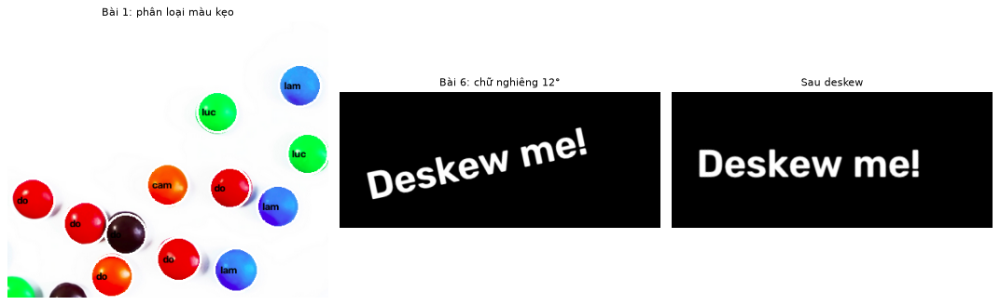

In [91]:
# --- Bài tổng hợp 1: đếm kẹo theo màu ---
circles = cv2.HoughCircles(sm_gray, cv2.HOUGH_GRADIENT, 1, rows / 8, param1=100, param2=30, minRadius=1, maxRadius=40)
circles = np.round(circles.reshape(-1, 3)).astype(int)


def hue_name(hv, sv):
    if sv < 60:   return 'xam/trang'
    if hv < 8 or hv >= 165: return 'do'
    if hv < 22:   return 'cam'
    if hv < 35:   return 'vang'
    if hv < 85:   return 'luc'
    if hv < 130:  return 'lam'
    return 'tim/hong'


vis = smarties.copy()
counts = {}
for x, y, r in circles:
    m = np.zeros(sm_gray.shape, np.uint8)
    cv2.circle(m, (x, y), max(r - 6, 3), 255, -1)
    hv = cv2.mean(sm_hsv, mask=m)[:2]
    # Hue là góc: lấy trung vị thay vì trung bình để tránh lỗi quấn vòng ở màu đỏ
    hue_med = int(np.median(sm_hsv[..., 0][m > 0]))
    name = hue_name(hue_med, hv[1])
    counts[name] = counts.get(name, 0) + 1
    cv2.circle(vis, (x, y), r, (255, 255, 255), 2)
    cv2.putText(vis, name, (x - 20, y + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 2)
print('Tổng số kẹo:', len(circles))
print('Theo màu   :', counts)

# --- Bài tổng hợp 6: deskew ---
txt = np.zeros((220, 520), np.uint8)
cv2.putText(txt, 'Deskew me!', (40, 130), cv2.FONT_HERSHEY_SIMPLEX, 2.2, 255, 6)
skewed = cv2.warpAffine(txt, cv2.getRotationMatrix2D((260, 110), 12, 1.0), (520, 220))
pts = np.column_stack(np.where(skewed > 0))[:, ::-1].astype(np.float32)   # (x, y)
(cx, cy), (rw, rh), ang = cv2.minAreaRect(pts)
if rw < rh:          # chuẩn hóa góc: lấy góc của cạnh dài
    ang = ang - 90
print(f'Góc nghiêng ước lượng: {ang:.2f}°')
deskewed = cv2.warpAffine(skewed, cv2.getRotationMatrix2D((cx, cy), ang, 1.0), (520, 220))
show([vis, skewed, deskewed], ['Bài 1: phân loại màu kẹo', 'Bài 6: chữ nghiêng 12°', 'Sau deskew'], size=4.5)

---
## 🎓 Tổng kết & lộ trình học tiếp

Bạn đã đi qua toàn bộ các thao tác xử lý **một bức ảnh** với OpenCV:

```mermaid
flowchart LR
  A[Đọc ảnh] --> B[Tiền xử lý: màu, resize, khử nhiễu, cân bằng sáng]
  B --> C[Trích xuất: ngưỡng, cạnh, hình thái học]
  C --> D[Phân tích: contour, components, Hough, đặc trưng]
  D --> E[Ứng dụng: đo, đếm, nhận dạng, scan, phục hồi]
```

**Lộ trình tiếp theo:**
1. **Video & camera:** `cv2.VideoCapture`, trừ nền (`createBackgroundSubtractorMOG2`), optical flow, tracking.
2. **Hình học đa ảnh:** homography + RANSAC (`findHomography`), ghép panorama, hiệu chuẩn camera (`calibrateCamera`).
3. **Học máy & học sâu với OpenCV:** module `cv2.dnn` để chạy model YOLO / ONNX, Haar cascade, HOG + SVM.
4. **Tài liệu:** [OpenCV-Python Tutorials](https://docs.opencv.org/4.x/d6/d00/tutorial_py_root.html), sách *Digital Image Processing* (Gonzalez & Woods), *Learning OpenCV* (Bradski & Kaehler).

> 💡 Cách tốt nhất để nhớ: chọn một ảnh **của chính bạn** (ảnh điện thoại) và chạy lại toàn bộ notebook với ảnh đó, chỉnh lại tham số cho phù hợp. Chúc bạn học tốt! 🚀